# Exploratory Data Analysis (EDA) in R
## Complete Study Notes, Dataset Dictionary and Line-by-Line Code Explanation

<br>

# **Kajola Gbenga**
### **Data Scientist & AI Engineer**

<br>

**Source material analysed:** <code>EDA&#95;in&#95;R&#95;Complete&#95;Masterclass&#95;FIXED.ipynb</code> (66 cells: 29 markdown, 37 code) and the two datasets it uses, <code>zedcrest&#95;employee&#95;data.csv</code> and <code>customer&#95;transactions.csv</code>.

**Language and kernel:** R (the notebook was executed on R 4.5.2 with the <code>ir</code> kernel).

**Purpose of this document:** a single study reference that (1) gives a high-level note on the whole notebook, (2) explains every column of both datasets, (3) explains every line of every code cell, every output it produces and the statistics behind each output.

---
## Table of Contents

| Part | What you will find |
|---|---|
| **Part 1** | High-level note on the notebook: purpose, structure, the EDA workflow, headline findings, and a health check of the notebook itself |
| **Part 2** | Dataset notes: file anatomy, a column-by-column data dictionary for **both** datasets, data quality findings, hidden relationships inside the data |
| **Part 3** | The full walkthrough, section by section (Section 0 to Section 9). Every code cell is reproduced with its real output, followed by a line-by-line table, an output explanation and a statistical interpretation |
| **Part 4** | Reference material: statistics glossary, R symbol and operator decoder, function dictionary, interpretation thresholds, discrepancy log, exercises |

### How to read each code walkthrough
Every code cell in Part 3 is followed by the same four blocks so you always know where to look:

1. **Purpose** - the business or analytical problem the code solves.
2. **Line-by-line table** - each line or phrase of the code with *what it means* and *why it is written that way*.
3. **Output explained** - what each printed line, table or chart in the result actually is.
4. **Statistical interpretation** - what the numbers tell us, and how confident we can be.

### Important notes on how this document was produced
- **All outputs are real.** In your uploaded notebook, execution stopped at an error in Section 5.2 (cell 38), so every code cell after it (Sections 5.3 to 9 and both Projects) had **no output stored**. I installed R, re-ran every cell against your two CSV files and embedded the genuine results. Outputs for cells that already had results in your file were reproduced and match yours exactly (for example 508 rows, 43 and 29 missing values, 500 cleaned rows, skewness 2.144).
- **Four code cells contained bugs** (cells 38, 50, 62 and 64). They are marked **FIXED** in the code and explained in the text, with the original faulty line shown so you can see exactly what changed.
- **The "Expected Output" blocks in your markdown cells contain illustrative numbers that do not match the real data.** For example the notebook's text says the mean salary is N370,245 but the real value is N367,294. In this document, real outputs always win. Part 4 has a full discrepancy log.
- **Punctuation:** only the standard hyphen (<code>-</code>) is used throughout. No long dashes.

---
# PART 1 - HIGH-LEVEL NOTE ON THE NOTEBOOK

## 1.1 What this notebook is

The notebook is a **two-week practical training module** on Exploratory Data Analysis (EDA) using R, written for the *Zedcrest Capital Data Analyst Training Programme*. It teaches a complete analytical routine on two realistic Nigerian financial-services datasets:

| Dataset | Business story | Rows x Columns (raw) | Grain (what one row is) |
|---|---|---|---|
| <code>zedcrest&#95;employee&#95;data.csv</code> | HR data of an investment firm, Zedcrest Capital | 508 x 15 | One row = one employee |
| <code>customer&#95;transactions.csv</code> | 2023 banking transactions of a retail bank | 810 x 15 | One row = one transaction |

**EDA** (Exploratory Data Analysis) is the disciplined first look at data: *before* you model, forecast or present, you check what the data contains, how clean it is, how each variable is distributed, how variables relate, and where the strange values are. A bad EDA produces wrong models and wrong management decisions; a good EDA prevents both.

## 1.2 The EDA workflow the notebook follows

```
   LOAD  ->  INSPECT  ->  CLEAN  ->  SUMMARISE  ->  COUNT  ->  CROSS  ->  CORRELATE  ->  FIND OUTLIERS  ->  PROFILE  ->  APPLY (2 projects)
  read_csv   str/glimpse  mutate    summary()     table()    tabyl(a,b)   cor()         IQR / Z-score      skim()       dashboards
             dim/head     distinct  mean/sd       tabyl()    chisq.test   corrplot      boxplot            DataExplorer
```

Each step answers one question:

| Step | Question it answers | Section in notebook |
|---|---|---|
| Load | Can R read the file and did all rows and columns arrive? | 1.1 |
| Inspect structure | What type is each column? Are any columns wrongly typed? | 1.2 - 1.3 |
| Missing-value audit | Where is data absent and how bad is it? | 1.4 |
| Clean | How do I fix types, fill gaps and remove duplicates without damaging the original file? | 1.5 |
| Summary statistics | Where is the centre of each variable, how spread out is it, what shape does it have? | 2 |
| Frequency tables | How many of each category do we have? | 3 |
| Crosstabs | How do two categorical variables interact? Is the link statistically real? | 4 |
| Correlation | Do two numeric variables move together? | 5 |
| Outliers | Which values are extreme, and are they errors or real? | 6 |
| Profiling | Can the whole dataset be audited in one call? | 7 |
| Project 1 | Can I turn the above into an HR management report? | 8 |
| Project 2 | Can I turn the above into a transaction and customer intelligence report? | 9 |

## 1.3 The tools (packages) and why each one is there

| Package | Role in this notebook | Python counterpart |
|---|---|---|
| <code>tidyverse</code> (umbrella) | Loads <code>dplyr</code>, <code>ggplot2</code>, <code>readr</code>, <code>tidyr</code>, <code>stringr</code>, <code>forcats</code>, <code>tibble</code>, <code>purrr</code>, <code>lubridate</code> in one line | pandas + matplotlib + seaborn |
| <code>dplyr</code> | Data manipulation verbs: <code>filter</code>, <code>select</code>, <code>mutate</code>, <code>summarise</code>, <code>group&#95;by</code>, <code>arrange</code>, <code>count</code>, <code>distinct</code> | pandas |
| <code>readr</code> | Fast CSV import: <code>read&#95;csv()</code> | <code>pd.read&#95;csv</code> |
| <code>tidyr</code> | Reshaping: <code>pivot&#95;longer</code>, <code>pivot&#95;wider</code>, <code>replace&#95;na</code> | <code>melt</code>, <code>pivot</code>, <code>fillna</code> |
| <code>ggplot2</code> | Charts built with the Grammar of Graphics | matplotlib / seaborn / plotnine |
| <code>lubridate</code> | Date parts: <code>month()</code>, <code>quarter()</code>, <code>wday()</code> | <code>df.dt.month</code> etc. |
| <code>janitor</code> | <code>clean&#95;names()</code>, <code>tabyl()</code>, <code>adorn&#95;&#42;()</code> for report-ready tables | manual formatting |
| <code>skimr</code> | <code>skim()</code>: one-call data profile with mini histograms | <code>describe()</code> + <code>ydata-profiling</code> |
| <code>corrplot</code> | Correlation matrix heat-map | <code>seaborn.heatmap</code> |
| <code>scales</code> | Number and percent formatters for axes | matplotlib formatters |
| <code>moments</code> | <code>skewness()</code> and <code>kurtosis()</code> | <code>scipy.stats.skew/kurtosis</code> |
| <code>gridExtra</code> | <code>grid.arrange()</code>: put several ggplots on one page (dashboard) | <code>plt.subplots</code> |
| <code>DataExplorer</code> (optional, commented out) | <code>create&#95;report()</code>: automatic HTML EDA report | <code>ydata-profiling</code> |

## 1.4 What the notebook teaches, skill by skill

1. **R syntax fundamentals:** assignment <code>&lt;-</code>, the <code>&#36;</code> column operator, vectors, functions, lists, <code>for</code> loops, <code>if</code>/<code>ifelse</code>, the two pipes (<code>&#124;&gt;</code> and <code>%&gt;%</code>).
2. **Data types and factors:** <code>chr</code>, <code>num</code>/<code>dbl</code>, <code>int</code>, <code>lgl</code>, <code>fct</code>, <code>ord</code>, <code>Date</code>; converting text to ordered categories.
3. **Missing data handling:** detect with <code>is.na()</code>, quantify, impute (median, zero), and understand <code>na.rm = TRUE</code>.
4. **Descriptive statistics:** mean, median, mode, standard deviation, variance, range, IQR, coefficient of variation, percentiles, skewness, kurtosis.
5. **Categorical analysis:** frequency, relative frequency, crosstabs, row percentages, chi-square test of independence.
6. **Correlation:** Pearson <code>r</code>, significance test, confidence interval, correlation matrix and heat-map, why Spearman is preferred for skewed data.
7. **Outlier detection:** Tukey IQR fences and Z-scores, box plots.
8. **Visual grammar:** histogram, bar, grouped bar, scatter with regression line, box, violin, jitter, heat-map, pie (polar bar), bubble, dual-axis line, density, facets, multi-panel dashboards.
9. **Business reporting:** payroll analysis, gender pay-gap table, performance heat-map, customer segmentation, channel mix, month-on-month growth, flagged-transaction (fraud watch) analysis.

## 1.5 Headline findings from the real outputs

### Employee data (500 unique staff after cleaning)
| Finding | Evidence (real output) | Reading |
|---|---|---|
| Data is clean but not perfect | 508 raw rows, **8 exact duplicates**, 72 missing cells (0.94 %) in two columns, 438 complete rows | Cleaning was necessary but light |
| Pay is extremely right-skewed | Mean N367,294 vs median N251,358; skewness **2.144**; kurtosis **8.153**; CV **90.4 %** | Use **median** as the typical salary; the mean is inflated by senior grades |
| Salary is determined almost entirely by **grade** | Grade bands never overlap: Grade 5 = N80,061 to N119,879, Grade 12 = N1,451,538 to N2,065,381 | Grade, not tenure or performance, sets pay |
| Tenure does **not** drive salary | <code>r</code> (salary, years of service) = **-0.012**, p = 0.7815, 95 % CI [-0.100, 0.075] | No evidence of a link; the notebook's text expected a positive link and the data disagree |
| Bonus is proportional to salary | <code>r</code> (salary, bonus) = **+0.816** | Bonus behaves like 5 % to 35 % of monthly salary |
| Age and tenure move together | <code>r</code> (age, years of service) = **+0.446** | The only moderate correlation among employee variables |
| Training does not predict performance | <code>r</code> (training hours, performance) = **-0.048** | Negligible; the notebook's text expected a positive link |
| Grade and employment status are independent | Chi-square = 15.078, df = 21, **p = 0.819** | No significant association (but see the small-count warning in Section 4) |
| Salary "outliers" are just senior staff | IQR method flags **39** (7.8 %), all Grade 11 or 12; Z-score flags **11** (9 are Grade 12) | Legitimate high earners, not errors |
| Payroll concentration | Total monthly payroll **N183,646,770**; Grades 11 and 12 (39 staff, 7.8 %) take **27.1 %** of it | A small senior group drives cost |

### Transaction data (800 unique transactions after cleaning)
| Finding | Evidence (real output) | Reading |
|---|---|---|
| 810 raw rows, 10 duplicates | 800 unique; 275 customers; 2023-01-01 to 2023-12-31 | Full calendar year |
| Missing data | 87 missing cells: <code>transaction&#95;category</code> 55, <code>customer&#95;satisfaction</code> 32 | The notebook never treats these; they stay as <code>NA</code> |
| Amounts are extremely skewed | Mean N189,920 vs median N50,101; skewness **6.095**; max N5,889,954 | Median and log scales are essential |
| Premium customers dominate value | Premium = 15.3 % of transactions but **67.8 %** of value (N102.98 M of N151.94 M) | Revenue concentration risk |
| Mobile App is the main channel | 30.8 % of volume, 34.2 % of value | Digital first |
| Higher flag rates on Internet Banking, POS, USSD | 7.8 %, 7.5 %, 7.5 % vs Branch 3.2 % and ATM 3.5 % | Where fraud monitoring should focus |
| September spike | N29.28 M in September (19.3 % of the year), +112 % month on month, then **-78.5 %** in October | Driven by 5 huge Premium transactions worth N18.4 M |
| Customer variables are unrelated | Largest absolute correlation among the five numeric variables is 0.059 | Practically zero linear relationship |
| Flagged transactions are **not** larger | Median flagged amount is N30,362 vs N50,245 for normal ones | The chart subtitle in the notebook ("flagged tend to be larger amounts") is contradicted by the data |

## 1.6 Health check of the notebook itself (what a reviewer would flag)

Learning from mistakes is part of good analysis. These are genuine issues found when the notebook was actually executed end to end:

| # | Cell | Issue | Severity | Fix applied here |
|---|---|---|---|---|
| 1 | 38 | <code>select(-is&#95;manager)</code> throws *Can't select columns that don't exist* because <code>is&#95;manager</code> was already converted to a factor, so <code>where(is.numeric)</code> had removed it. **This error stopped the whole notebook**, leaving cells 39 to 64 without output | Blocking | <code>select(-any&#95;of("is&#95;manager"))</code> |
| 2 | 50 | <code>sapply(df, class)</code> returns a **list** when any column is an ordered factor (its class has two labels), so <code>table()</code> fails with *all arguments must have the same length* | Blocking | <code>sapply(df, function(x) class(x)&#91;1&#93;)</code> |
| 3 | 62 | <code>round()</code> on a data frame that contains a factor column errors (*non-numeric-alike variable*), so the segment x channel heat-map never drew | Blocking | round only numeric columns via <code>across()</code> |
| 4 | 64 | <code>scale&#95;x&#95;continuous(limits = c(0,240))</code> silently **deleted the Debit bar** (241 rows) from "Transactions by Type" | Silent wrong chart | limit raised to 300 |
| 5 | 13 | Comment says "department median" but code uses the **overall** median for performance_score | Documentation | explained in Section 1.5 notes |
| 6 | 3, 12, 19, 21, 27, 31 ... | "Expected Output" blocks show numbers that differ from the real data | Misleading | Part 4 log |
| 7 | 40, 34, 41 ... | Some narrative claims are not supported by the data (salary rises with tenure, training raises performance, Technology leads headcount, flagged transactions are larger) | Misleading | Part 4 log |
| 8 | 2 | <code>cat("R version:", R.version&#36;major, ".", R.version&#36;minor)</code> prints <code>4 . 5.2</code> with stray spaces | Cosmetic | use <code>R.version.string</code> |
| 9 | 22 | The "Median" and "Mean" text labels overlap on the histogram | Cosmetic | offset the labels |

Nothing here reduces the teaching value of the notebook; it makes a good case study in **"always execute and verify"**.

---
# PART 2 - DATASET NOTES

## 2.0 Anatomy of a CSV file (applies to both datasets)

A **CSV (Comma-Separated Values)** file is plain text. Line 1 is the **header** (column names). Every following line is one **record** (row). Values within a line are separated by commas. Rules that matter for EDA:

| Rule | Meaning | Consequence in R |
|---|---|---|
| Header row | First line holds names, not data | <code>read&#95;csv()</code> uses it as column names |
| Comma delimiter | <code>,</code> separates fields | <code>read&#95;csv()</code> (comma) vs <code>read&#95;csv2()</code> (semicolon) vs <code>read&#95;tsv()</code> (tab) |
| Empty field (<code>,,</code>) | A missing value | <code>read&#95;csv()</code> turns an empty field into <code>NA</code> |
| No type information | Everything is text on disk | <code>readr</code> **guesses** the type of each column from the first 1,000 rows (<code>guess&#95;max</code>): all digits -> <code>double</code>; otherwise <code>character</code> |
| Dates are just text | <code>2023-01-08</code> is a string | Must be converted with <code>as.Date()</code> |

<code>NA</code> means "Not Available": R's universal marker for a missing value. Any arithmetic on an <code>NA</code> returns <code>NA</code> unless you say <code>na.rm = TRUE</code>.

## 2A. Dataset 1 - <code>zedcrest&#95;employee&#95;data.csv</code> (HR / Workforce)

### 2A.1 File facts

| Property | Value |
|---|---|
| Rows in file (excluding header) | **508** |
| Columns | **15** |
| Unique employees (<code>employee&#95;id</code>) | **500** (the extra 8 rows are exact duplicate records) |
| Missing cells | **72** (<code>performance&#95;score</code> 43, <code>annual&#95;bonus</code> 29) = 0.94 % of all cells |
| Complete rows (no <code>NA</code> anywhere) | 438 |
| Currency | Nigerian Naira (N) |
| Business grain | One row = one employee at a point in time (a snapshot, not a history) |
| Time reference | "YTD" fields (<code>training&#95;hours&#95;ytd</code>) are year-to-date; the notebook's chart caption calls it "HR Data 2024" |

### 2A.2 First five raw rows

| employee_id | department | grade | gender | state_of_origin | highest_qualification | age | years_of_service |
|---|---|---|---|---|---|---|---|
| ZED-1497 | Compliance | Grade 6 | Female | Lagos | ACCA | 45 | 12 |
| ZED-1240 | Sales | Grade 10 | Female | Abuja | CFA | 33 | 3 |
| ZED-1466 | Sales | Grade 8 | Female | Kano | B.Sc | 36 | 14 |
| ZED-1165 | Compliance | Grade 5 | Female | Abuja | M.Sc | 50 | 8 |
| ZED-1002 | Technology | Grade 8 | Male | Anambra | MBA | 57 | 11 |

| employment_status | monthly_salary | annual_bonus | performance_score | training_hours_ytd | leave_days_used | is_manager |
|---|---|---|---|---|---|---|
| Active | 121689 | 40157 |  | 37 | 19 | 0 |
| Active | 747591 |  | 2.80 | 107 | 3 | 1 |
| Active | 363994 | 127397 | 2.20 | 96 | 9 | 0 |
| Suspended | 82586 | 17343 | 3.50 | 22 | 21 | 0 |
| Active | 335701 | 16785 | 1.80 | 73 | 14 | 0 |

*(The 15 columns are shown in two blocks so the table fits on screen. A blank cell is a missing value.)*

### 2A.3 Data dictionary (all 15 columns)

*Profiles below use the 500 unique employees unless stated otherwise.*

| # | Column | What it means (business meaning) | Type in raw file | Type after cleaning in R | Observed values / range | Missing | Analytical role and cautions |
|---|---|---|---|---|---|---|---|
| 1 | <code>employee&#95;id</code> | Unique staff number. Format <code>ZED-</code> + 4 digits (ZED is the company prefix; numbers run 1000 to 1499). It is the **primary key**: one value should identify one person. | text (<code>chr</code>) | text (<code>chr</code>) | 500 unique values in 508 rows; 8 IDs appear twice | none | Use to detect duplicates. It has **no analytical meaning** as a number; never average or correlate it. |
| 2 | <code>department</code> | The business unit the employee works in. | text | factor (unordered) | Finance (83), Technology (81), Sales (79), Operations (74), Compliance (53), Risk Management (53), Human Resources (43), Audit (34) | none | Nominal category (no natural order). Used for group comparisons and headcount. |
| 3 | <code>grade</code> | Job grade or pay band. A higher grade means a more senior post. Values run Grade 5 (junior) to Grade 12 (most senior). | text | **ordered** factor (Grade 5 < ... < Grade 12) | Grade 6 (107), Grade 7 (95), Grade 8 (82), Grade 5 (74), Grade 9 (64), Grade 10 (39), Grade 11 (30), Grade 12 (9) | none | Ordinal category. Alphabetical order would put "Grade 10" before "Grade 5", so you **must** give R the level order explicitly. Grade almost fully determines salary (see 2A.5). |
| 4 | <code>gender</code> | Employee gender as recorded by HR. | text | factor | Male (290), Female (210) | none | Binary nominal. Used for representation and pay-equity analysis. |
| 5 | <code>state&#95;of&#95;origin</code> | Nigerian state the employee originates from (origin, not current residence). | text | stays <code>chr</code> | Lagos (213), Abuja (92), Kano (55), Rivers (37), Edo (30), Oyo (29), Delta (24), Anambra (20) | none | Nominal, 8 values. Not converted to a factor in the notebook and never analysed further. |
| 6 | <code>highest&#95;qualification</code> | Highest academic or professional qualification. HND = Higher National Diploma; B.Sc = Bachelor of Science; M.Sc = Master of Science; MBA = Master of Business Administration; Ph.D = Doctorate; ACCA = Association of Chartered Certified Accountants; CFA = Chartered Financial Analyst. | text | factor | B.Sc (149), M.Sc (105), HND (95), MBA (73), ACCA (28), Ph.D (27), CFA (23) | none | Mixes academic degrees and professional certificates, so it is **not a clean ladder**; treat as nominal. |
| 7 | <code>age</code> | Age in completed years. | integer-like (<code>dbl</code>) | <code>dbl</code> | 22 to 57; mean 40; median 40 | none | Continuous-like numeric. Adult working range; nobody under 22. |
| 8 | <code>years&#95;of&#95;service</code> | Whole years the employee has worked at Zedcrest. | <code>dbl</code> | <code>dbl</code> | 0.0 to 19.0; mean 7.7; median 7.0 | none | Discrete numeric. Consistency check passed: <code>age - years&#95;of&#95;service</code> is never below 22, so nobody "started work" before 22. |
| 9 | <code>employment&#95;status</code> | Current HR status: Active, On Leave, Resigned, Suspended. | text | factor | Active (406), On Leave (44), Resigned (27), Suspended (23) | none | Nominal. Note that **Resigned** staff are still in the file, so they are included in salary and performance statistics. |
| 10 | <code>monthly&#95;salary</code> | Monthly pay in Naira (gross basis is not stated in the file). | <code>dbl</code> | <code>dbl</code> | 80,061 to 2,065,381; mean 367,294; median 251,358 | none | The most important numeric variable. Strongly right-skewed (skewness 2.14). |
| 11 | <code>annual&#95;bonus</code> | Bonus in Naira for the year. Empirically it equals **5 % to 35 %** of <code>monthly&#95;salary</code> (mean ratio 19.4 %), i.e. less than one month of pay. | <code>dbl</code> (with blanks) | <code>dbl</code>, blanks replaced by **0** | 5,194 to 660,921; mean 71,582; median 42,588 (non-missing) | 29 in raw file | Filling with 0 assumes "no record = no bonus", which pulls the mean down from N70,857 to N67,431. A judgement call, not a fact. |
| 12 | <code>performance&#95;score</code> | Appraisal score from 1.0 (poor) to 5.0 (excellent), recorded to one decimal. | <code>dbl</code> (with blanks) | <code>dbl</code>, blanks replaced by the **median 3.2** | 1.00 to 5.00; mean 3.23; median 3.20 (non-missing) | 43 in raw file | Median fill leaves the mean unchanged (3.227) but **shrinks the spread** and creates a spike at 3.2. |
| 13 | <code>training&#95;hours&#95;ytd</code> | Training hours completed so far this year. | <code>dbl</code> | <code>dbl</code> | 0.0 to 119.0; mean 58.0; median 57.0 | none | Discrete numeric; almost uniform between 0 and 119 hours. |
| 14 | <code>leave&#95;days&#95;used</code> | Leave days taken. The maximum is 21, which suggests a 21-day annual entitlement. | <code>dbl</code> | <code>dbl</code> | 0.0 to 21.0; mean 10.7; median 10.0 | none | Discrete numeric; almost uniform between 0 and 21. |
| 15 | <code>is&#95;manager</code> | Flag: 1 = the employee manages people, 0 = does not. | <code>dbl</code> (0/1) | factor with labels **No / Yes** | No (0) (364), Yes (1) (136) | none | Binary. Converting the 0/1 to a labelled factor makes tables readable but removes it from numeric selection (this caused the cell 38 error). |

### 2A.4 Variable-type map (drives which statistic is allowed)

| Statistical type | Columns | Allowed summaries |
|---|---|---|
| **Identifier** | <code>employee&#95;id</code> | count, uniqueness only |
| **Nominal** (unordered category) | <code>department</code>, <code>gender</code>, <code>state&#95;of&#95;origin</code>, <code>highest&#95;qualification</code>, <code>employment&#95;status</code>, <code>is&#95;manager</code> | frequency, percentage, mode, chi-square |
| **Ordinal** (ordered category) | <code>grade</code> | frequency, median grade, order comparisons |
| **Discrete numeric** | <code>age</code>, <code>years&#95;of&#95;service</code>, <code>training&#95;hours&#95;ytd</code>, <code>leave&#95;days&#95;used</code> | mean, median, sd, correlation |
| **Continuous numeric** | <code>monthly&#95;salary</code>, <code>annual&#95;bonus</code>, <code>performance&#95;score</code> | mean, median, sd, skewness, quantiles, correlation, outlier tests |

### 2A.5 Hidden structure discovered in the data

**(a) Salary is almost a function of grade.** The salary ranges of the eight grades **do not overlap at all**:

| Grade | n | Min salary (N) | Median (N) | Max salary (N) |
|---|---|---|---|---|
| Grade 5 | 74 | 80,061 | 105,710 | 119,879 |
| Grade 6 | 107 | 120,003 | 149,175 | 179,109 |
| Grade 7 | 95 | 181,739 | 228,730 | 279,038 |
| Grade 8 | 82 | 280,319 | 334,170 | 399,874 |
| Grade 9 | 64 | 405,297 | 488,086 | 599,867 |
| Grade 10 | 39 | 603,947 | 736,546 | 898,010 |
| Grade 11 | 30 | 902,927 | 1,138,734 | 1,386,464 |
| Grade 12 | 9 | 1,451,538 | 1,661,902 | 2,065,381 |

Consequences: (1) grade explains nearly all salary variation; (2) once you know a person's grade, tenure, age, gender, department and performance add almost nothing to predicting pay; (3) any "gender pay gap" between departments is mostly a **grade-mix** effect, not a like-for-like pay difference.

**(b) Bonus tracks salary.** Bonus divided by monthly salary lies between 0.05 and 0.35 for every employee who has a bonus. That is why the correlation between the two is 0.816.

**(c) Tenure and age are linked, nothing else is.** Only <code>age</code> and <code>years&#95;of&#95;service</code> (r = 0.446) show a moderate relationship. Every other numeric pair has |r| below 0.09, except salary and bonus. This is typical of **synthetic (simulated) training data**: variables are generated independently unless the author linked them on purpose.

**(d) <code>is&#95;manager</code> is not tied to seniority.** The share of managers is 30 % in Grade 5 and 22 % in Grade 12, and the median salary of managers (N243,266) is slightly *lower* than that of non-managers (N254,585). In real HR data this would be a red flag for data quality; here it simply confirms the data were simulated.

**(e) The 8 duplicates are exact copies**, including the same <code>employee&#95;id</code> (for example ZED-1064 appears twice with identical values). They are entry or extraction repeats, not different people.

**(f) Small groups.** Some Department x Grade cells have a single employee (for example Human Resources in Grade 10 has 1 person, which is why the Section 8 heat-map shows a perfect 5.0). Averages from very small groups are unreliable.

### 2A.6 Data-quality scorecard

| Check | Result | Verdict |
|---|---|---|
| Duplicate rows | 8 (1.6 %) | Removed with <code>distinct()</code> |
| Duplicate keys after <code>distinct()</code> | 0 | Good |
| Missing values | 72 cells in 2 columns | Imputed by the notebook |
| Impossible values (negative salary, age below 18, score outside 1 to 5) | none | Good |
| Type problems | none in practice (readr already read blanks as <code>NA</code> and columns as numbers) | Good |
| Referential consistency (<code>age</code> vs <code>years&#95;of&#95;service</code>) | consistent | Good |
| Plausibility (<code>is&#95;manager</code> vs grade) | weak | Caution |

---
## 2B. Dataset 2 - <code>customer&#95;transactions.csv</code> (Retail Banking Transactions)

### 2B.1 File facts

| Property | Value |
|---|---|
| Rows in file (excluding header) | **810** |
| Columns | **15** |
| Unique transactions (<code>transaction&#95;id</code>) | **800** (10 exact duplicate rows) |
| Unique customers (<code>customer&#95;id</code>) | **275** (about 2.9 transactions per customer) |
| Date range | 2023-01-01 to 2023-12-31 (a full calendar year, 365 distinct dates) |
| Missing cells | **88** in the raw file; **87** after duplicate removal (<code>transaction&#95;category</code> 55, <code>customer&#95;satisfaction</code> 32) |
| Currency | Nigerian Naira (N) |
| Business grain | One row = one transaction |

### 2B.2 First five raw rows

| transaction_id | transaction_date | customer_id | customer_segment | customer_gender | customer_age | customer_region | years_as_customer |
|---|---|---|---|---|---|---|---|
| TXN-100017 | 2023-01-08 | CUST-5289 | Standard | Male | 51 | North Central | 4 |
| TXN-100647 | 2023-10-22 | CUST-5230 | Standard | Male | 45 | North Central | 6 |
| TXN-100014 | 2023-01-07 | CUST-5145 | Standard | Female | 22 | South South | 5 |
| TXN-100110 | 2023-02-20 | CUST-5243 | Standard | Female | 49 | South South | 1 |
| TXN-100089 | 2023-02-10 | CUST-5142 | Basic | Male | 44 | North Central | 1 |

| transaction_type | transaction_channel | transaction_category | transaction_amount | account_balance_after | customer_satisfaction | is_flagged |
|---|---|---|---|---|---|---|
| Debit | Branch | Rent | 11,359.83 | 492,268.58 | 2.40 | 0 |
| Credit | Mobile App | Fuel | 53,658.52 | 65,826.51 |  | 0 |
| Online Transfer | Internet Banking | Shopping | 130,044.59 | 7,761.58 | 3.20 | 0 |
| Debit | USSD | Airtime | 218,907.38 | 726,695.57 | 5 | 0 |
| ATM Withdrawal | Mobile App | Utilities | 3,465.23 | 465,717.43 | 2.80 | 0 |

*(A blank cell is a missing value. Amounts are shown rounded to 2 decimals.)*

### 2B.3 Data dictionary (all 15 columns)

*Profiles use the 800 unique transactions unless stated otherwise.*

| # | Column | What it means (business meaning) | Type in raw file | Type after cleaning in R | Observed values / range | Missing | Analytical role and cautions |
|---|---|---|---|---|---|---|---|
| 1 | <code>transaction&#95;id</code> | Unique transaction reference, <code>TXN-</code> + 6 digits (100000 to 100799). Primary key. | text | text | 800 unique in 810 rows | none | Duplicate detection only. |
| 2 | <code>transaction&#95;date</code> | Calendar date on which the transaction happened, in ISO format <code>YYYY-MM-DD</code>. | text (looks like a date but is text) | <code>Date</code> | 2023-01-01 to 2023-12-31 | none | Must be converted with <code>as.Date()</code> before month, quarter or weekday can be extracted. |
| 3 | <code>customer&#95;id</code> | Customer reference, <code>CUST-</code> + 4 digits (5000 to 5299). One customer can have many transactions. | text | text | 275 unique customers | none | Use <code>n&#95;distinct()</code> to count customers. It is a foreign key to a customer table that is not supplied. |
| 4 | <code>customer&#95;segment</code> | Value tier of the customer: Basic (lowest), Standard, Premium (highest). | text | **factor** with level order Basic, Standard, Premium | Standard (443), Basic (235), Premium (122) | none | Ordinal. The only customer attribute that is consistent per customer (each <code>customer&#95;id</code> has exactly one segment). |
| 5 | <code>customer&#95;gender</code> | Customer gender. | text | factor | Male (435), Female (365) | none | Binary nominal. **Not stable per customer** (see 2B.5). |
| 6 | <code>customer&#95;age</code> | Customer age in years at the time of the transaction. | integer | <code>dbl</code> | 18 to 64; mean 40; median 40 | none | Numeric. **Not stable per customer**: one <code>customer&#95;id</code> can carry several different ages. |
| 7 | <code>customer&#95;region</code> | Nigerian geo-political zone where the customer is located. | text | factor | Southwest (280), North Central (199), South South (142), Northwest (111), Southeast (68) | none | Nominal, 5 zones. The North East zone does not appear at all. |
| 8 | <code>years&#95;as&#95;customer</code> | Whole years the customer has banked with the institution. | integer | <code>dbl</code> | 1.0 to 8.0; mean 4.4; median 4.0 | none | Discrete numeric between 1 and 8. |
| 9 | <code>transaction&#95;type</code> | Kind of banking operation: Debit, Credit, Transfer, ATM Withdrawal, POS Purchase, Bill Payment, Online Transfer. | text | factor | Debit (241), Credit (173), Transfer (143), ATM Withdrawal (79), POS Purchase (78), Bill Payment (57), Online Transfer (29) | none | Nominal. Types overlap in meaning (a POS Purchase is also a debit) so they are labels, not exclusive accounting classes. |
| 10 | <code>transaction&#95;channel</code> | Touch-point used: Mobile App, Internet Banking, Branch, ATM, POS Terminal, USSD. | text | factor | Mobile App (246), Internet Banking (154), Branch (126), ATM (114), POS Terminal (93), USSD (67) | none | Nominal. Main dimension of the channel analysis. |
| 11 | <code>transaction&#95;category</code> | Purpose of the spending or receipt: Shopping, Rent, School Fees, Fuel, Utilities, Salary Credit, Airtime, Insurance, Entertainment, Investment, Groceries, Healthcare. | text (with blanks) | stays <code>chr</code>; **left with <code>NA</code>** | Shopping (73), Rent (70), School Fees (67), Fuel (65), Utilities (65), Salary Credit (62), Insurance (61), Airtime (60), Entertainment (59), Investment (55), Groceries (54), Healthcare (54); blank 55 | 55 (after de-dup) | Never used in the notebook. The category values are spread almost evenly across every type (for example "Salary Credit" occurs with "ATM Withdrawal"), another sign of simulated data. |
| 12 | <code>transaction&#95;amount</code> | Value of the transaction in Naira. Always positive, whether it is a debit or a credit; the direction is given by <code>transaction&#95;type</code>. | <code>dbl</code> | <code>dbl</code> | 1,498 to 5,889,954; mean 189,920; median 50,101 | none | Key numeric. Extremely right-skewed (skewness 6.09). Analyse on the log scale or with medians. |
| 13 | <code>account&#95;balance&#95;after</code> | Account balance in Naira immediately after the transaction. | <code>dbl</code> | <code>dbl</code> | 2,437 to 14,528,386; mean 435,823; median 171,112 | none | Numeric, also heavily skewed. In 212 of 800 rows the balance after is smaller than the transaction amount, which is only possible for credits or with overdrafts. |
| 14 | <code>customer&#95;satisfaction</code> | Survey score from 1.0 (very dissatisfied) to 5.0 (very satisfied), one decimal. | <code>dbl</code> (with blanks) | <code>dbl</code>, <code>NA</code> kept | 1.00 to 5.00; mean 3.53; median 3.50 (non-missing) | 32 (after de-dup) | Handled with <code>na.rm = TRUE</code> in group means; never imputed. Not every transaction has a survey response. |
| 15 | <code>is&#95;flagged</code> | Fraud or compliance flag: 1 = flagged for review, 0 = normal. | integer 0/1 | factor with labels **Normal / Flagged** | Normal (0) (755), Flagged (1) (45) | none | Binary target-like variable (5.6 % flagged). Class imbalance matters for any future model. |

### 2B.4 Variable-type map

| Statistical type | Columns |
|---|---|
| Identifier / key | <code>transaction&#95;id</code>, <code>customer&#95;id</code> |
| Date-time | <code>transaction&#95;date</code> (plus the derived <code>month&#95;num</code>, <code>month&#95;name</code>, <code>quarter</code>, <code>day&#95;of&#95;week</code>) |
| Nominal | <code>customer&#95;gender</code>, <code>customer&#95;region</code>, <code>transaction&#95;type</code>, <code>transaction&#95;channel</code>, <code>transaction&#95;category</code> |
| Ordinal | <code>customer&#95;segment</code> (Basic < Standard < Premium) |
| Binary flag | <code>is&#95;flagged</code> |
| Discrete numeric | <code>customer&#95;age</code>, <code>years&#95;as&#95;customer</code>, <code>customer&#95;satisfaction</code> (1.0 to 5.0 in 0.1 steps) |
| Continuous numeric | <code>transaction&#95;amount</code>, <code>account&#95;balance&#95;after</code> |

### 2B.5 Hidden structure and cautions

**(a) Value is concentrated in Premium.** Segment sizes and shares:

| Segment | Transactions | Share of count | Total value (N) | Share of value | Median transaction (N) |
|---|---|---|---|---|---|
| Premium | 122 | 15.3 % | 102,975,023 | **67.8 %** | 481,835 |
| Standard | 443 | 55.4 % | 44,745,086 | 29.5 % | 61,346 |
| Basic | 235 | 29.4 % | 4,215,610 | 2.8 % | 11,342 |

Segment is essentially a **tier of spending power**: the median Premium transaction is about 42 times the Basic median.

**(b) Customer attributes are not stable inside one <code>customer&#95;id</code>.** Segment is constant per customer, but <code>customer&#95;age</code> has on average **2.8 different values** per customer (up to 7), <code>customer&#95;gender</code> differs for many customers, and so do region and years as customer. In a real bank a customer has one age, one gender and one home region. This proves the file was generated row by row. **Practical rule:** analyse demographics at the *transaction* level and avoid claims like "customers aged 40 spend more" that assume one age per customer.

**(c) Amount has no direction.** Debit, Credit, ATM Withdrawal etc. are all stored as positive numbers, so summing <code>transaction&#95;amount</code> measures *turnover* (gross flow), not net cash movement.

**(d) The time axis is complete.** Every one of the 365 days of 2023 has transactions, with 61 to 69 transactions each month, so month totals are driven by **transaction size**, not by how many transactions occurred. This is why September (N29.28 M) looks so different from October (N6.28 M) even though both have 68 transactions.

**(e) Missingness is small but ignored.** 55 blank categories and 32 blank satisfaction scores are carried forward as <code>NA</code>; the missing-value count of 87 printed in Project 2 is these two columns.

### 2B.6 Data-quality scorecard

| Check | Result | Verdict |
|---|---|---|
| Duplicate rows | 10 (1.2 %) | Removed with <code>distinct()</code> |
| Missing values | 87 cells (0.73 % of all cells) in 2 columns | Left as <code>NA</code> |
| Impossible values (negative or zero amounts, dates outside 2023) | none | Good |
| Date parsing | all 810 strings parse to valid 2023 dates | Good |
| Attribute consistency per customer | poor (age, gender, region vary) | Caution |
| Direction of amount | not recorded | Caution |
| Balance vs amount plausibility | 26.5 % of rows have balance after smaller than amount | Caution |

---
## 2C. Which analysis uses which columns

| Analysis in the notebook | Employee columns | Transaction columns |
|---|---|---|
| Structure and missing values | all | all |
| Salary / amount distribution | <code>monthly&#95;salary</code> | <code>transaction&#95;amount</code> |
| Frequency tables | <code>department</code>, <code>grade</code>, <code>gender</code> | <code>transaction&#95;type</code>, <code>customer&#95;region</code> |
| Crosstab and chi-square | <code>department</code> x <code>gender</code>; <code>grade</code> x <code>employment&#95;status</code> | (segment x channel value in Project 2) |
| Correlation | 7 numeric variables | 5 numeric variables |
| Outliers | <code>monthly&#95;salary</code> | <code>transaction&#95;amount</code> by segment |
| Group KPIs | <code>department</code>, <code>grade</code>, <code>gender</code>, <code>performance&#95;score</code> | <code>customer&#95;segment</code>, <code>transaction&#95;channel</code>, month, <code>is&#95;flagged</code> |

---
# PART 3 - FULL WALKTHROUGH: CODE, OUTPUT, LINE-BY-LINE EXPLANATION, STATISTICS

> In this part each code cell is **runnable R code**. To run it yourself, keep both CSV files in the folder where you launch the notebook, and run the cells **in order** (later cells depend on objects created by earlier ones).
>
> **A note on <code>&#92;n</code>.** In your file, most <code>cat("...")</code> strings contain a real line break inside the quotation marks instead of the two characters <code>&#92;n</code>. R accepts a line break inside a string and treats it as a newline character, so the printed output is identical. This document describes those strings as ending with a newline.

## Notebook cell 0 - Title block, "Why R for EDA?" and the R vs Python cheat sheet

This first markdown cell is the notebook cover. It does three teaching jobs.

**(1) Why R.** The comparison table argues that R was built by statisticians. What each row means:

| Row in the notebook table | What it means |
|---|---|
| Statistical depth | Tests such as <code>t.test()</code>, <code>chisq.test()</code>, <code>cor.test()</code> and distribution functions ship with base R. Python needs <code>scipy</code> or <code>statsmodels</code>. |
| Data profiling | <code>summary()</code> and <code>str()</code> give an instant profile; in Python you combine <code>describe()</code> and <code>dtypes</code>. |
| Visualisation | <code>ggplot2</code> implements the *Grammar of Graphics*: a chart is data + aesthetics + geometry + scales + labels. |
| Table output | Packages like <code>kable</code> and <code>gt</code> make publication-ready tables. |
| Finance-specific | <code>PerformanceAnalytics</code> and <code>quantmod</code> cover portfolio and market-data work. |

**(2) The section map** (Section 0 to Section 9), each with its key functions. It is the syllabus of the notebook.

**(3) The R vs Python cheat sheet.** Line by line:

| R / Python pair | Meaning |
|---|---|
| <code>import pandas</code> <-> <code>library(dplyr)</code> | Load a package. R uses <code>library()</code> (no quotes needed); Python uses <code>import</code>. |
| <code>df.head()</code> <-> <code>head(df)</code> | First rows. R is a *function call* <code>head(df)</code>; Python is a *method call* <code>df.head()</code>. |
| <code>df.shape</code> <-> <code>dim(df)</code> | Rows and columns. |
| <code>df.dtypes</code> <-> <code>str(df)</code> | Column types. |
| <code>df&#91;'col'&#93;</code> <-> <code>df&#36;col</code> or <code>df&#91;&#91;'col'&#93;&#93;</code> | Extract a column. <code>&#36;</code> is the shortcut, <code>&#91;&#91; &#93;&#93;</code> is the programmable form. |
| <code>df.describe()</code> <-> <code>summary(df)</code> | Statistical summary. |
| <code>df.isnull()</code> <-> <code>is.na(df)</code> | Missing-value test. |
| <code>df.dropna()</code> <-> <code>na.omit(df)</code> | Delete rows with missing values. |
| <code>df.groupby()</code> <-> <code>group&#95;by() &#43; summarise()</code> | Split-apply-combine. |
| <code>len(df)</code> <-> <code>nrow(df)</code> | Number of rows. |
| <code>df.columns</code> <-> <code>names(df)</code> or <code>colnames(df)</code> | Column names. |

One important difference: **R counts from 1**, Python counts from 0. The first element of an R vector is <code>x&#91;1&#93;</code>.

## Section 0 - R Environment Setup (notebook cell 1)

Before analysing anything you need the right tools. Two verbs matter:

| Verb | When | Why |
|---|---|---|
| <code>install.packages("name")</code> | **Once per computer** | Downloads the package from CRAN (the Comprehensive R Archive Network) to your disk |
| <code>library(name)</code> | **Every session** | Loads the installed package into memory so its functions can be called |

**The tidyverse** is a family of packages that share one design philosophy: data in tidy tables, verbs that do one thing, and the pipe to chain them. It is to R what pandas is to Python. Members named in the notebook: <code>dplyr</code> (manipulate), <code>ggplot2</code> (plot), <code>readr</code> (read files), <code>tidyr</code> (reshape), <code>stringr</code> (text), <code>forcats</code> (factors).

### Cell 2 (Step 0.1) - Install, load, set theme, create a formatter

**Purpose.** Make the session reproducible: (a) install only the packages that are missing, (b) load them quietly, (c) print a session report, (d) set one consistent look for every chart, (e) define a reusable function that shows Naira amounts as <code>N1.5M</code> instead of <code>1500000</code>.

In [1]:
# =============================================================================
# STEP 0.1- INSTALL ALL REQUIRED PACKAGES
# Run this block ONCE when setting up a new R environment.
# After installation, comment out install.packages() calls.
# =============================================================================

# Auto-install any missing packages (safe- only installs what is not present)
pkgs_needed <- c(
  "tidyverse",   # dplyr, ggplot2, readr, tidyr, stringr, forcats
  "janitor",     # clean_names(), tabyl()
  "skimr",       # skim() - comprehensive data profiling
  "corrplot",    # correlation matrix visualisation
  "scales",      # number formatters for ggplot2
  "moments",     # skewness(), kurtosis()
  "gridExtra"    # grid.arrange() for multi-panel charts
)

# Install only packages that are not already installed
pkgs_missing <- pkgs_needed[!sapply(pkgs_needed, requireNamespace, quietly = TRUE)]
if (length(pkgs_missing) > 0) {
  install.packages(pkgs_missing, repos = "https://cloud.r-project.org")
}

# Load all packages
suppressPackageStartupMessages({
  # Silences version warning messages - packages still load normally
  library(tidyverse)      # loads: dplyr, ggplot2, readr, tidyr, stringr, forcats
  library(janitor)        # tabyl(), clean_names()
  library(skimr)          # skim()
  library(corrplot)       # corrplot()
  library(scales)         # comma(), percent()
  library(moments)        # skewness(), kurtosis()
  library(gridExtra)      # grid.arrange()
})

cat("=== R SESSION INFORMATION ===
")
cat("R version:", R.version$major, ".", R.version$minor, "
")
cat("Working directory:", getwd(), "
")
cat("All packages loaded successfully.
")

# Set global ggplot2 theme - applies to ALL charts in this session
theme_set(
  theme_minimal(base_size = 12) +
  theme(
    plot.title       = element_text(face = "bold", size = 14, colour = "#2C3E50"),
    plot.subtitle    = element_text(size = 11, colour = "#5D6D7E"),
    axis.title       = element_text(face = "bold", size = 11),
    legend.position  = "bottom",
    panel.grid.minor = element_blank(),
    plot.background  = element_rect(fill = "#FAFAFA", colour = NA)
  )
)

# Nigerian Naira formatter for chart axes
naira_fmt <- function(x) {
  # Converts 1500000 -> "N1.5M" for readable chart axes
  dplyr::case_when(
    abs(x) >= 1e9  ~ paste0("N", round(x/1e9, 1), "B"),
    abs(x) >= 1e6  ~ paste0("N", round(x/1e6, 1), "M"),
    abs(x) >= 1e3  ~ paste0("N", round(x/1e3, 0), "K"),
    TRUE           ~ paste0("N", formatC(x, format="f", digits=0, big.mark=","))
  )
}

cat("Theme and formatters set.
")


=== R SESSION INFORMATION ===
R version: 4 . 3.3 
Working directory: /tmp/run 
All packages loaded successfully.
Theme and formatters set.


### Line-by-line explanation of cell 2

**Part A - install only what is missing**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>pkgs&#95;needed &lt;- c(</code> | Create a **character vector** (an ordered list of text values). <code>&lt;-</code> is R's assignment arrow: "store the result on the right in the name on the left". <code>c()</code> means *combine*. | One vector holds the whole shopping list of packages, so the install logic below is written once, not seven times. |
| 2 | <code>"tidyverse", "janitor", "skimr", "corrplot", "scales", "moments", "gridExtra"</code> | Seven package names as text (quotes mean "this is text, not an R object"). Each has a <code>&#35;</code> comment saying what it gives you. | Quotes are needed because <code>install.packages()</code> and <code>requireNamespace()</code> receive names as strings. |
| 3 | <code>pkgs&#95;missing &lt;- pkgs&#95;needed&#91;&#33;sapply(pkgs&#95;needed, requireNamespace, quietly = TRUE)&#93;</code> | <code>sapply(x, f)</code> applies function <code>f</code> to each element of <code>x</code> and simplifies the result to a vector. <code>requireNamespace(pkg, quietly = TRUE)</code> returns <code>TRUE</code> if the package is installed and loadable, otherwise <code>FALSE</code>, without printing errors. <code>&#33;</code> flips TRUE/FALSE. <code>pkgs&#95;needed&#91; ... &#93;</code> keeps only the names where the logical test is <code>TRUE</code>. | The result is exactly the list of packages that are **not** installed. This is *logical indexing*, the core R idiom for filtering. |
| 4 | <code>if (length(pkgs&#95;missing) &gt; 0) &#123;</code> | <code>length()</code> counts elements. If at least one package is missing, run the block in braces. | Prevents a pointless reinstall (and slow internet use) when everything is already there. |
| 5 | <code>install.packages(pkgs&#95;missing, repos = "https://cloud.r-project.org")</code> | Download and install the missing packages. <code>repos</code> names the mirror (server) to download from. | Setting <code>repos</code> explicitly avoids the interactive "choose a CRAN mirror" pop-up, so the notebook can run unattended. |
| 6 | <code>&#125;</code> | Close the <code>if</code> block. | R uses braces <code>&#123; &#125;</code> for blocks; indentation is only for humans. |

**Part B - load the packages quietly**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>suppressPackageStartupMessages(&#123;</code> | Run the code inside, but hide the friendly "Attaching packages..." messages. | Keeps the notebook output short. It hides **messages** only; **warnings** still appear (see the output). |
| 2 | <code>library(tidyverse)</code> | Attach the 9 core tidyverse packages (dplyr, ggplot2, readr, tidyr, purrr, tibble, stringr, forcats, lubridate). | One line gives you the whole data-science toolkit. Note: <code>lubridate</code> is attached by tidyverse 2.0+, which is why later code can call <code>lubridate::month()</code>. |
| 3 | <code>library(janitor)</code> | Adds <code>clean&#95;names()</code> (fix column names) and <code>tabyl()</code> + <code>adorn&#95;&#42;()</code> (professional frequency tables). | Needed from Section 1.5 and Section 3. |
| 4 | <code>library(skimr)</code> | Adds <code>skim()</code>, a one-call dataset profile. | Needed in Section 7. |
| 5 | <code>library(corrplot)</code> | Adds <code>corrplot()</code>, a correlation heat-map. | Needed in Section 5.3. |
| 6 | <code>library(scales)</code> | Number/percent/comma formatters for chart axes. | Loaded for completeness; the notebook writes its own <code>naira&#95;fmt</code> instead. |
| 7 | <code>library(moments)</code> | Adds <code>skewness()</code> and <code>kurtosis()</code>. | Base R has no built-in skewness function. |
| 8 | <code>library(gridExtra)</code> | Adds <code>grid.arrange()</code> to place several ggplots on one canvas. | Needed for the two dashboards. |
| 9 | <code>&#125;)</code> | End of the quiet block. |  |

**Part C - session report**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("=== R SESSION INFORMATION ===&#92;n")</code> | <code>cat()</code> prints text without quotes or index numbers. <code>&#92;n</code> = newline. | <code>cat()</code> is the tool for clean, formatted messages; <code>print()</code> would show <code>&#91;1&#93; "..."</code>. |
| 2 | <code>cat("R version:", R.version&#36;major, ".", R.version&#36;minor, "&#92;n")</code> | <code>R.version</code> is a built-in list; <code>&#36;major</code> = "4", <code>&#36;minor</code> = "5.2". <code>cat</code> joins its arguments with a **space** between them. | Because of that automatic space the output is <code>4 . 5.2</code> instead of <code>4.5.2</code>. A cleaner call is <code>cat("R version:", R.version.string)</code>. |
| 3 | <code>cat("Working directory:", getwd(), "&#92;n")</code> | <code>getwd()</code> returns the folder R is currently working in. | Critical for EDA: <code>read&#95;csv("file.csv")</code> looks for the file **here**. If the CSV is elsewhere the load fails. |
| 4 | <code>cat("All packages loaded successfully.&#92;n")</code> | Confirmation message. | If any <code>library()</code> had failed, R would have stopped before this line. |

**Part D - global chart theme**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>theme&#95;set(</code> | Store a theme as the **default** for every ggplot created afterwards. | Write the styling once; every chart in the notebook inherits it (DRY principle: Don't Repeat Yourself). |
| 2 | <code>theme&#95;minimal(base&#95;size = 12) &#43;</code> | Start from ggplot's clean <code>theme&#95;minimal</code> with 12-point base text. | A neutral, uncluttered starting point. |
| 3 | <code>theme(</code> | Then override individual elements. <code>&#43;</code> adds layers/settings to a plot object. |  |
| 4 | <code>plot.title = element&#95;text(face = "bold", size = 14, colour = "&#35;2C3E50"),</code> | Chart title: bold, 14 pt, dark slate-blue. <code>"&#35;2C3E50"</code> is a **hex colour** (RR GG BB in base 16: red 2C, green 3E, blue 50). | Consistent brand colour. <code>element&#95;text()</code> is the constructor for text formatting. |
| 5 | <code>plot.subtitle = element&#95;text(size = 11, colour = "&#35;5D6D7E"),</code> | Subtitle: 11 pt grey-blue. | Visual hierarchy: title stronger than subtitle. |
| 6 | <code>axis.title = element&#95;text(face = "bold", size = 11),</code> | Axis titles bold. | Makes axis names stand out. |
| 7 | <code>legend.position = "bottom",</code> | Legends go under the chart. | Saves horizontal space for wide charts and dashboards. |
| 8 | <code>panel.grid.minor = element&#95;blank(),</code> | <code>element&#95;blank()</code> deletes the thin minor grid lines. | Reduces visual noise ("chart junk"). |
| 9 | <code>plot.background = element&#95;rect(fill = "&#35;FAFAFA", colour = NA)</code> | Paint the whole plot area near-white; <code>colour = NA</code> means **no border**. | Softer than pure white on screens and slides. |
| 10 | <code>) )  &#91;closing brackets&#93;</code> | Close <code>theme(</code>, then <code>theme&#95;set(</code>. |  |

**Part E - the Naira formatter (a user-defined function)**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>naira&#95;fmt &lt;- function(x) &#123;</code> | Define a new function called <code>naira&#95;fmt</code> taking one input <code>x</code>. A function is stored in a name using <code>&lt;-</code> just like data. | Chart axes with 1500000 are unreadable; a function converts numbers to labels and can be reused on any axis. |
| 2 | <code>dplyr::case&#95;when(</code> | <code>case&#95;when()</code> tests conditions **top to bottom** and returns the value of the first TRUE one (R's vectorised if / else-if / else). <code>dplyr::</code> says "the function from the dplyr package". | The <code>pkg::function</code> form removes any doubt about which package supplies the function and avoids name clashes. |
| 3 | <code>abs(x) &gt;= 1e9  &#126; paste0("N", round(x/1e9, 1), "B"),</code> | If the absolute value is at least 1,000,000,000 (<code>1e9</code> is scientific notation), divide by 1e9, round to 1 decimal, and glue "N" before and "B" after. <code>paste0()</code> concatenates with **no** separator. <code>&#126;</code> separates the condition from the result. | <code>abs()</code> makes negative amounts format correctly too. |
| 4 | <code>abs(x) &gt;= 1e6  &#126; paste0("N", round(x/1e6, 1), "M"),</code> | Millions: 1,500,000 -> "N1.5M". | Checked after the billion rule; order matters because 2e9 also satisfies <code>&gt;= 1e6</code>. |
| 5 | <code>abs(x) &gt;= 1e3  &#126; paste0("N", round(x/1e3, 0), "K"),</code> | Thousands rounded to 0 decimals: 250,000 -> "N250K". |  |
| 6 | <code>TRUE &#126; paste0("N", formatC(x, format="f", digits=0, big.mark=","))</code> | <code>TRUE</code> is the catch-all default. <code>formatC(..., format="f", digits=0, big.mark=",")</code> writes a plain number with no decimals and thousand separators. | A <code>TRUE</code> last line acts like <code>else</code>. Without it, small numbers would return <code>NA</code>. |
| 7 | <code>)  and  &#125;</code> | Close <code>case&#95;when</code> then the function body. The value of the last expression is what the function returns. | R functions return their last evaluated value; no <code>return()</code> needed. |
| 8 | <code>cat("Theme and formatters set.&#92;n")</code> | Confirmation message. |  |

### Output of cell 2 explained

| Output line | What it is | Reading |
|---|---|---|
| <code>Warning message: "package 'tidyverse' was built under R version 4.5.3"</code> (repeated for 14 packages) | Each package was compiled by its author using R 4.5.3, but you are running R 4.5.2 (patch level one behind). | **Harmless.** Packages from the same minor version (4.5) are compatible. To silence, update R to 4.5.3. <code>suppressPackageStartupMessages</code> hides messages, not warnings, which is why these still show. |
| <code>=== R SESSION INFORMATION ===</code> | Header. | Formatting only. |
| <code>R version: 4 . 5.2</code> | R 4.5.2 (major 4, minor 5.2) with stray spaces. | Confirms the modern R 4.x that supports the native pipe <code>&#124;&gt;</code> (introduced in R 4.1). |
| <code>Working directory: c:/Users/user/Desktop/My Projects/Zedcrest Training/R/EDA</code> | Folder where the notebook runs. | The two CSVs must be in this folder. |
| <code>All packages loaded successfully.</code> / <code>Theme and formatters set.</code> | Confirmation. | If you see both, the environment is ready. |

*(The output above is taken from your own run, so the version and path are yours. The "Expected Output" block in cell 3 of your notebook showed <code>4 . 3.x</code> and a placeholder path, which is just an example.)*

### Statistical interpretation
No statistics yet. The methodological point: **reproducibility**. A notebook that installs its own dependencies, records the R version and working directory, and fixes a theme can be rerun by anyone and will look the same.

### Notebook cell 3 - "Understanding the code" and "Key R Syntax Rules" explained
| Concept in the notebook | Explanation |
|---|---|
| <code>library(tidyverse)</code> "loads 8 packages" | Older tidyverse loaded 8 core packages; version 2.0 (2023) added <code>lubridate</code>, making 9. Your warnings list <code>lubridate</code>, confirming 9. |
| <code>theme&#95;set(...)</code> | Global default; every later <code>ggplot()</code> inherits it. |
| <code>naira&#95;fmt &lt;- function(x)</code> | <code>&lt;-</code> is assignment; <code>function(args) &#123; body &#125;</code> builds a function. |
| <code>dplyr::case&#95;when(...)</code> | <code>::</code> = "from that package". |
| **Assignment** <code>&lt;-</code> vs <code>=</code> | Both work at top level. <code>&lt;-</code> is the R convention; <code>=</code> is used *inside* function calls for arguments (<code>bins = 30</code>). |
| **Pipe** <code>&#124;&gt;</code> (base R 4.1+) or <code>%&gt;%</code> (magrittr) | Passes the left result as the **first argument** of the right function. Reads left to right like a sentence. |
| **Comment** <code>&#35;</code> | Everything after <code>&#35;</code> on a line is ignored by R. |
| **Print** | R auto-prints the value of a bare expression. <code>cat()</code> for formatted text, <code>print()</code> to force printing (needed inside loops and functions). |

---
## Section 1 - Load and Inspect the Data (notebook cells 4 to 14)

**Idea.** Before any calculation, answer: *how big is the data, what are the columns, what type is each, and what do the first values look like?* R's inspection tools (<code>dim</code>, <code>names</code>, <code>str</code>, <code>head</code>, <code>glimpse</code>) answer this in seconds.

### Cell 5 (Step 1.1) - Load both CSV files

**Purpose.** Read the two files into R as tibbles and confirm the row and column counts.

In [2]:
# =============================================================================
# STEP 1.1- LOAD THE DATASETS
# read_csv() from readr (tidyverse) is faster than base R's read.csv()
# and automatically handles data types more intelligently
# =============================================================================

# Load Employee Dataset
employee <- read_csv("zedcrest_employee_data.csv", show_col_types = FALSE)
# read_csv(): reads CSV file into a tibble (tidyverse's improved data frame)
# A tibble prints more cleanly than a data.frame and never converts strings to factors

# Load Customer Transaction Dataset
transactions <- read_csv("customer_transactions.csv", show_col_types = FALSE)

cat("=== DATASETS LOADED ===
")
cat("Employee dataset:     ", nrow(employee), "rows x", ncol(employee), "columns
")
cat("Transactions dataset: ", nrow(transactions), "rows x", ncol(transactions), "columns
")


=== DATASETS LOADED ===
Employee dataset:      508 rows x 15 columns
Transactions dataset:  810 rows x 15 columns


### Line-by-line explanation of cell 5

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>employee &lt;- read&#95;csv("zedcrest&#95;employee&#95;data.csv", show&#95;col&#95;types = FALSE)</code> | <code>read&#95;csv()</code> (package <code>readr</code>) reads a CSV into a **tibble** and stores it in the name <code>employee</code>. The file path is relative to the working directory. <code>show&#95;col&#95;types = FALSE</code> suppresses the message listing the type chosen for each column. | Preferred over base <code>read.csv()</code> because it is faster, never turns text into factors, keeps column names as written, and reports parsing problems. Hiding the type message keeps output short (the types are inspected explicitly in the next cell). |
| 2 | <code>transactions &lt;- read&#95;csv("customer&#95;transactions.csv", show&#95;col&#95;types = FALSE)</code> | Same for the second dataset. | Two independent tables; they are never joined in this notebook. |
| 3 | <code>cat("=== DATASETS LOADED ===&#92;n")</code> | Print a header. |  |
| 4 | <code>cat("Employee dataset:     ", nrow(employee), "rows x", ncol(employee), "columns&#92;n")</code> | <code>nrow()</code> = number of rows, <code>ncol()</code> = number of columns. The five spaces after the colon align the two report lines. | A quick integrity check: do the counts match the file? (508 lines + 1 header line in the CSV, 15 comma-separated fields). |
| 5 | <code>cat("Transactions dataset: ", nrow(transactions), "rows x", ncol(transactions), "columns&#92;n")</code> | Same for transactions. | Python equivalents: <code>df.shape&#91;0&#93;</code> and <code>df.shape&#91;1&#93;</code>. |

### Output explained

| Output | Meaning | Reading |
|---|---|---|
| <code>Employee dataset:      508 rows x 15 columns</code> | 508 employee records, 15 attributes each. | Matches the CSV (509 lines including header). Later we learn only 500 are unique employees. |
| <code>Transactions dataset:  810 rows x 15 columns</code> | 810 transaction records, 15 attributes each. | Later we learn 800 are unique transactions. |

### Statistical interpretation
- **Sample size matters for inference.** 508 and 810 rows are moderate: enough for stable means, medians and correlations; too small for reliable statistics inside tiny subgroups (for example a department-by-grade cell with 1 person).
- The **unit of analysis** is different: a person in file 1, an event in file 2. Averages in file 2 are averages *per transaction*, not per customer.

### Notebook cell 6 - "Code Explanation" table (re-explained)
<code>read&#95;csv</code> vs <code>read.csv</code>: the tidyverse version is faster (the notebook says about 10x on large files) and more type-safe. <code>nrow(employee)</code> is <code>df.shape&#91;0&#93;</code> in Python; <code>ncol(employee)</code> is <code>df.shape&#91;1&#93;</code>.

### Cell 7 (Step 1.2) - Structural inspection: <code>dim()</code>, <code>names()</code>, <code>str()</code>

**Purpose.** Learn the shape, the column names and, most importantly, the **data type of every column**. Wrong types are the most common cause of wrong statistics.

In [3]:
# =============================================================================
# STEP 1.2- STRUCTURAL INSPECTION: str(), dim(), names(), head()
# These four functions are the R equivalent of Python's df.info() + df.head()
# =============================================================================

cat("===== EMPLOYEE DATASET STRUCTURE =====
")

# dim(): dimensions (rows, columns) as a vector
cat("Dimensions:", dim(employee), "
")
# Output: 508 15  (508 rows, 15 columns)

# names(): all column names
cat("
Column names:
")
print(names(employee))
# names() is identical to colnames()- both work

cat("
--- STRUCTURE (str) ---
")
str(employee)
# str(): the most important inspection function in R
# Shows: data type of every column, first few values, number of observations
# chr = character (text)    dbl = double (decimal number)    num = number
# lgl = logical (TRUE/FALSE)    int = integer    fct = factor (categorical)


===== EMPLOYEE DATASET STRUCTURE =====
Dimensions: 508 15 

Column names:
 [1] "employee_id"           "department"            "grade"                 "gender"               
 [5] "state_of_origin"       "highest_qualification" "age"                   "years_of_service"     
 [9] "employment_status"     "monthly_salary"        "annual_bonus"          "performance_score"    
[13] "training_hours_ytd"    "leave_days_used"       "is_manager"           

--- STRUCTURE (str) ---
spc_tbl_ [508 × 15] (S3: spec_tbl_df/tbl_df/tbl/data.frame)
 $ employee_id          : chr [1:508] "ZED-1497" "ZED-1240" "ZED-1466" "ZED-1165" ...
 $ department           : chr [1:508] "Compliance" "Sales" "Sales" "Compliance" ...
 $ grade                : chr [1:508] "Grade 6" "Grade 10" "Grade 8" "Grade 5" ...
 $ gender               : chr [1:508] "Female" "Female" "Female" "Female" ...
 $ state_of_origin      : chr [1:508] "Lagos" "Abuja" "Kano" "Abuja" ...
 $ highest_qualification: chr [1:508] "ACCA" "CFA" "B.Sc"

### Line-by-line explanation of cell 7

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== EMPLOYEE DATASET STRUCTURE =====&#92;n")</code> | Section banner. | Readable output when many results follow. |
| 2 | <code>cat("Dimensions:", dim(employee), "&#92;n")</code> | <code>dim()</code> returns a **vector of two numbers**: rows then columns. <code>cat</code> prints them separated by spaces. | Shows <code>508 15</code>. Python: <code>df.shape</code>. |
| 3 | <code>cat("&#92;nColumn names:&#92;n")</code> | Print a blank line (leading <code>&#92;n</code>), then a label. | Spacing for readability. |
| 4 | <code>print(names(employee))</code> | <code>names()</code> returns the column names as a character vector; <code>print()</code> displays it with <code>&#91;1&#93;</code>-style index markers. | <code>print</code> is required because <code>cat</code> would flatten the vector without quotes. <code>names()</code> and <code>colnames()</code> are identical for data frames. |
| 5 | <code>cat("&#92;n--- STRUCTURE (str) ---&#92;n")</code> | Label. |  |
| 6 | <code>str(employee)</code> | <code>str()</code> (structure) prints, for every column, its **type**, its **length** and its **first values**. | The single most useful inspection function in R. It is the union of pandas <code>df.info()</code> and <code>df.dtypes</code>. |

### Output explained

**Dimensions and names.** <code>508 15</code> is rows by columns. The 15 names are printed in reading order with index labels <code>&#91;1&#93;</code>, <code>&#91;4&#93;</code>, <code>&#91;7&#93;</code>... marking the position of the first name on each printed line.

**The <code>str()</code> block, piece by piece:**

| Fragment | Meaning |
|---|---|
| <code>spc&#95;tbl&#95; &#91;508 x 15&#93;</code> | A **spec tibble**: a tibble created by <code>readr</code>, which remembers the column specification it used. Shape 508 rows by 15 columns. |
| <code>(S3: spec&#95;tbl&#95;df/tbl&#95;df/tbl/data.frame)</code> | The object's class chain. It *is a* data.frame (so all base functions work) with extra tibble features. |
| <code>&#36; employee&#95;id : chr &#91;1:508&#93; "ZED-1497" "ZED-1240" ...</code> | <code>&#36;</code> starts each column line. <code>chr</code> = character (text). <code>&#91;1:508&#93;</code> = 508 values. Then the first five values. |
| <code>num</code> | Numeric (double precision decimal). Used by <code>age</code>, <code>years&#95;of&#95;service</code>, <code>monthly&#95;salary</code>, <code>annual&#95;bonus</code>, <code>performance&#95;score</code>, <code>training&#95;hours&#95;ytd</code>, <code>leave&#95;days&#95;used</code> and <code>is&#95;manager</code>. |
| <code>&#36; annual&#95;bonus : num &#91;1:508&#93; 40157 NA 127397 ...</code> | The <code>NA</code> shows a **missing** value read from a blank cell. |
| <code>&#36; performance&#95;score : num &#91;1:508&#93; NA 2.8 2.2 ...</code> | Same: first employee has no score. |
| <code>&#36; is&#95;manager : num &#91;1:508&#93; 0 1 0 0 0 1 ...</code> | A 0/1 flag stored as a number (not yet a category). |
| <code>- attr(&#42;, "spec")= .. cols(...)</code> | The parsing recipe <code>readr</code> recorded (<code>col&#95;character()</code>, <code>col&#95;double()</code>). |
| <code>- attr(&#42;, "problems")=&lt;externalptr&gt;</code> | A pointer to any parsing problems; empty here. |

### Statistical interpretation (types and what they allow)
| Column group | R type | Statistical scale | What you may compute |
|---|---|---|---|
| <code>employee&#95;id</code>, <code>department</code>, <code>grade</code>, <code>gender</code>, <code>state&#95;of&#95;origin</code>, <code>highest&#95;qualification</code>, <code>employment&#95;status</code> | <code>chr</code> | Nominal / ordinal | Counts, percentages, chi-square. **Not** means. |
| <code>age</code>, <code>years&#95;of&#95;service</code>, <code>training&#95;hours&#95;ytd</code>, <code>leave&#95;days&#95;used</code> | <code>num</code> | Discrete ratio | Mean, sd, correlation |
| <code>monthly&#95;salary</code>, <code>annual&#95;bonus</code>, <code>performance&#95;score</code> | <code>num</code> | Continuous | All summaries and skewness |
| <code>is&#95;manager</code> | <code>num</code> | Binary (0/1) | Proportion, but **should be a category** |

**Important correction to the notebook's text.** The "Expected Output" in cell 8 says <code>annual&#95;bonus</code> and <code>performance&#95;score</code> are <code>chr</code> "because missing values were entered as empty strings". The **real output shows <code>num</code>**: <code>read&#95;csv</code> already interpreted the blank cells as <code>NA</code> and kept the columns numeric. So the <code>as.numeric()</code> conversion in the cleaning step (cell 13) is a harmless safeguard, not a necessary repair.

### Notebook cell 8 - "Reading str() Output" table explained
| Symbol | Meaning | Python equivalent |
|---|---|---|
| <code>chr</code> | character / text | <code>object</code> (string) |
| <code>num</code> / <code>dbl</code> | double-precision decimal | <code>float64</code> |
| <code>int</code> | whole number | <code>int64</code> |
| <code>lgl</code> | TRUE / FALSE | <code>bool</code> |
| <code>fct</code> | factor (categorical with fixed levels) | <code>category</code> |
| <code>ord</code> | ordered factor (levels have a rank) | ordered <code>category</code> |

### Cell 9 (Step 1.3) - Preview the data: <code>head()</code>, <code>tail()</code>, <code>glimpse()</code>

**Purpose.** *See* actual values. Statistics can hide problems (typos, odd formats, shifted columns) that show up immediately when you eyeball rows.

In [4]:
# =============================================================================
# STEP 1.3- PREVIEW DATA: head(), tail(), glimpse()
# =============================================================================

cat("===== FIRST 6 ROWS =====
")
head(employee, 6)
# head(df, n): first n rows. Default n=6 (R) vs default n=5 (Python)

cat("
===== LAST 4 ROWS =====
")
tail(employee, 4)
# tail(df, n): last n rows

cat("
===== GLIMPSE (tidyverse version of str) =====
")
glimpse(employee)
# glimpse() from dplyr - more compact than str()
# Shows: number of rows, columns, data type of each column, and first few values
# Easier to read than str() for wide datasets


===== FIRST 6 ROWS =====
# A tibble: 6 × 15
  employee_id department grade    gender state_of_origin highest_qualification   age years_of_service
  <chr>       <chr>      <chr>    <chr>  <chr>           <chr>                 <dbl>            <dbl>
1 ZED-1497    Compliance Grade 6  Female Lagos           ACCA                     45               12
2 ZED-1240    Sales      Grade 10 Female Abuja           CFA                      33                3
3 ZED-1466    Sales      Grade 8  Female Kano            B.Sc                     36               14
4 ZED-1165    Compliance Grade 5  Female Abuja           M.Sc                     50                8
5 ZED-1002    Technology Grade 8  Male   Anambra         MBA                      57               11
6 ZED-1051    Sales      Grade 8  Male   Lagos           MBA                      26                4
# ℹ 7 more variables: employment_status <chr>, monthly_salary <dbl>, annual_bonus <dbl>,
#   performance_score <dbl>, training_hours_ytd <db

### Line-by-line explanation of cell 9

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== FIRST 6 ROWS =====&#92;n")</code> | Banner. |  |
| 2 | <code>head(employee, 6)</code> | First 6 rows. Second argument = number of rows. R's default is 6 (pandas default is 5). | Top rows show how the file starts; useful for spotting header problems. |
| 3 | <code>cat("&#92;n===== LAST 4 ROWS =====&#92;n")</code> | Banner with a blank line first. |  |
| 4 | <code>tail(employee, 4)</code> | Last 4 rows. | Checks the **end** of the file, where truncated exports or total rows often hide. |
| 5 | <code>glimpse(employee)</code> | <code>glimpse()</code> (from dplyr/tibble) prints one line per column: <code>&#36; name &lt;type&gt; first values</code>. Types appear as <code>&lt;chr&gt;</code>, <code>&lt;dbl&gt;</code>, <code>&lt;int&gt;</code>, <code>&lt;fct&gt;</code>. | More compact than <code>str()</code> and always fits the console width, so it is the best choice for wide tables. |

### Output explained

- **First 6 rows.** Row 1 is employee ZED-1497 in Compliance, Grade 6, Female, from Lagos, ACCA-qualified, age 45, 12 years of service, Active, salary N121,689, bonus N40,157, **performance score NA**, 37 training hours, 19 leave days, not a manager. Row 2 (ZED-1240, Sales, Grade 10) has a salary of N747,591 but **bonus NA**. These two <code>NA</code>s are the missing values counted in the next cell.
- **Last 4 rows.** The final row is ZED-1100 (Sales, Grade 9, Female, Delta, M.Sc, age 38, On Leave, salary N566,505). Nothing looks truncated.
- **Tibble printing.** R prints <code>&#35; A tibble: 6 x 15</code> and, when columns do not fit the width, ends with <code>&#35; i 7 more variables: ...</code>. It also shows the type under each name (<code>&lt;chr&gt;</code>, <code>&lt;dbl&gt;</code>). Your original Jupyter run printed these as plain data-frame tables; the content is identical.
- **glimpse.** <code>Rows: 508</code>, <code>Columns: 15</code>, then 15 lines. The trailing <code>...</code> on each line means more values exist than are shown. In the raw data <code>department</code> and <code>grade</code> are still <code>&lt;chr&gt;</code> (text) and <code>is&#95;manager</code> is <code>&lt;dbl&gt;</code>; they will become <code>&lt;fct&gt;</code>/<code>&lt;ord&gt;</code> after cleaning.

### Statistical interpretation
Sampling the head and tail is a **sanity check on data generation**: IDs look like <code>ZED-&#35;&#35;&#35;&#35;</code>, salaries are of a plausible magnitude, ages are adult, scores are between 1 and 5. Also note the first and last rows are **not sorted** by ID or department, so any "first N rows" sample is not a biased slice.

### Notebook cell 10 - <code>glimpse()</code> vs <code>str()</code>
| Function | Best for | Output style |
|---|---|---|
| <code>str(df)</code> | Deep type inspection and nested structures | Verbose, shows class hierarchy and attributes |
| <code>glimpse(df)</code> | Quick column overview | Compact, one line per column |
| <code>head(df)</code> | Seeing real data values in table form | Table |
| <code>summary(df)</code> | Statistical overview of every column | Min / quartiles / mean / max |

### Cell 11 (Step 1.4) - Missing-value analysis

**Purpose.** Quantify how much data is missing, **where**, and how serious it is. Missing data can bias means, break correlations and silently drop rows from models.

In [5]:
# =============================================================================
# STEP 1.4- MISSING VALUE ANALYSIS IN R
# is.na() is R's equivalent of Python's isnull()
# =============================================================================

cat("===== MISSING VALUE ANALYSIS =====
")

# Count missing values per column
missing_summary <- employee |>
  summarise(across(everything(), ~sum(is.na(.)))) |>
  # across(everything()): apply function to ALL columns
  # ~sum(is.na(.)): the ~ creates an anonymous function; . refers to each column
  pivot_longer(everything(), names_to = "column", values_to = "missing_count") |>
  # pivot_longer: reshapes from wide format to long format (each column = one row)
  mutate(
    missing_pct = round(missing_count / nrow(employee) * 100, 2),
    severity    = case_when(
      missing_pct > 50  ~ "CRITICAL",
      missing_pct > 20  ~ "HIGH",
      missing_pct > 0   ~ "MODERATE",
      TRUE              ~ "COMPLETE"
    )
  ) |>
  filter(missing_count > 0) |>  # keep only columns with missing values
  arrange(desc(missing_pct))    # sort by % missing (highest first)

print(missing_summary)

cat("
Total missing cells:", sum(is.na(employee)), "
")
cat("% of all cells missing:", round(sum(is.na(employee)) / prod(dim(employee)) * 100, 2), "%
")
cat("Complete rows (no missing anywhere):", sum(complete.cases(employee)), "
")
# complete.cases(): returns TRUE for rows with NO missing values in any column


===== MISSING VALUE ANALYSIS =====
# A tibble: 2 × 4
  column            missing_count missing_pct severity
  <chr>                     <int>       <dbl> <chr>   
1 performance_score            43        8.46 MODERATE
2 annual_bonus                 29        5.71 MODERATE

Total missing cells: 72 
% of all cells missing: 0.94 %
Complete rows (no missing anywhere): 438 


### Line-by-line explanation of cell 11

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== MISSING VALUE ANALYSIS =====&#92;n")</code> | Banner. |  |
| 2 | <code>missing&#95;summary &lt;- employee &#124;&gt;</code> | Start a **pipeline**: take <code>employee</code> and pass it into the next function; store the final result in <code>missing&#95;summary</code>. <code>&#124;&gt;</code> is the native pipe (R 4.1+). | Without the pipe you would need four nested function calls read from the inside out. |
| 3 | <code>summarise(across(everything(), &#126;sum(is.na(.)))) &#124;&gt;</code> | <code>summarise()</code> collapses many rows into one. <code>across(everything(), f)</code> applies <code>f</code> to **every column**. The formula <code>&#126;sum(is.na(.))</code> is a shorthand anonymous function: <code>.</code> stands for the current column; <code>is.na(.)</code> gives TRUE for each missing cell; <code>sum()</code> counts the TRUEs (TRUE = 1). | Counts missing values in all 15 columns at once with a single expression. Result: a table with **1 row and 15 columns**. |
| 4 | <code>pivot&#95;longer(everything(), names&#95;to = "column", values&#95;to = "missing&#95;count") &#124;&gt;</code> | Reshape from **wide** to **long**: the 15 column names become 15 rows. <code>names&#95;to</code> names the new column holding the old headers; <code>values&#95;to</code> names the column holding the counts. | A tall table (one row per variable) is easier to filter, sort and plot than a 15-column row. |
| 5 | <code>mutate(</code> | Add new columns computed from existing ones. | Python: <code>df&#91;"new"&#93; = ...</code>. |
| 6 | <code>missing&#95;pct = round(missing&#95;count / nrow(employee) &#42; 100, 2),</code> | Percentage of rows missing: count / 508 x 100, rounded to 2 decimals. | A percentage is comparable across datasets of different sizes. (The denominator is the raw 508, including duplicates.) |
| 7 | <code>severity = case&#95;when(</code> | Create a label column with rules tested in order. | Turns a number into a decision category. |
| 8 | <code>missing&#95;pct &gt; 50 &#126; "CRITICAL",</code> | More than half missing: the column is probably unusable. | Threshold rule of thumb. |
| 9 | <code>missing&#95;pct &gt; 20 &#126; "HIGH",</code> | 20 % to 50 %: needs a serious treatment plan. |  |
| 10 | <code>missing&#95;pct &gt; 0 &#126; "MODERATE",</code> | Anything above 0 up to 20 %. | The label "MODERATE" is generous for tiny amounts; it just means "some". |
| 11 | <code>TRUE &#126; "COMPLETE"</code> | Default: no missing values. | <code>TRUE</code> acts as <code>else</code>. |
| 12 | <code>filter(missing&#95;count &gt; 0) &#124;&gt;</code> | Keep only rows (columns of the original data) that actually have missing values. | Removes 13 rows of zeros so only the problem columns remain. |
| 13 | <code>arrange(desc(missing&#95;pct))</code> | Sort by percentage, highest first. <code>desc()</code> = descending. | Worst problem at the top. |
| 14 | <code>print(missing&#95;summary)</code> | Display the tibble. | Inside a script or function you need <code>print()</code>; at the top level of a notebook cell the last value prints automatically. |
| 15 | <code>cat("&#92;nTotal missing cells:", sum(is.na(employee)), "&#92;n")</code> | <code>is.na(employee)</code> gives a 508 x 15 grid of TRUE/FALSE; <code>sum</code> counts all TRUEs. | One number for the whole dataset. |
| 16 | <code>cat("% of all cells missing:", round(sum(is.na(employee)) / prod(dim(employee)) &#42; 100, 2), "%&#92;n")</code> | <code>prod(dim(employee))</code> = 508 x 15 = 7,620 cells. Missing / total x 100. | <code>prod()</code> multiplies all elements of a vector, giving the total cell count. |
| 17 | <code>cat("Complete rows (no missing anywhere):", sum(complete.cases(employee)), "&#92;n")</code> | <code>complete.cases()</code> returns TRUE for a row with no <code>NA</code> in any column; <code>sum</code> counts those rows. | Shows how many rows survive if you simply delete every incomplete row (<code>na.omit</code>). |

### Output explained

| Output | Calculation | Meaning |
|---|---|---|
| <code>A tibble: 2 x 4</code> | 2 columns have missing data; 4 columns of output | Only 2 of 15 columns have any missing value |
| <code>performance&#95;score 43  8.46  MODERATE</code> | 43 / 508 x 100 = 8.46 % | Appraisal score absent for 43 employees |
| <code>annual&#95;bonus 29  5.71  MODERATE</code> | 29 / 508 x 100 = 5.71 % | Bonus absent for 29 employees |
| <code>Total missing cells: 72</code> | 43 + 29 | All missing cells |
| <code>% of all cells missing: 0.94 %</code> | 72 / 7,620 x 100 = 0.945 | Under 1 % of the table |
| <code>Complete rows: 438</code> | 508 - 70 | 70 rows have at least one gap. Since 43 + 29 = 72 missing cells but only 70 affected rows, **2 employees are missing both** fields |

### Statistical interpretation
- **Amount of missingness.** 0.94 % of cells and 13.8 % of rows (70 / 508). Under 5 % of cells is generally considered low; but because the gaps sit in only two columns, those columns lose 5.7 % to 8.5 % of their information.
- **Mechanism (theory).** Statisticians classify missing data as **MCAR** (Missing Completely At Random), **MAR** (depends on other observed variables) or **MNAR** (depends on the missing value itself). A missing bonus could be MNAR (no bonus paid = left blank); a missing performance score could be MAR (new staff not yet appraised). The data cannot prove which, so the imputation choices in the next cell are assumptions.
- **Choosing a fix.** Options are delete rows, impute with a constant, impute with mean/median, impute by group, or model-based imputation. The notebook uses median and zero.

### Notebook cell 12 - key functions for missing values
| Function | What it does |
|---|---|
| <code>is.na(x)</code> | TRUE for each missing element |
| <code>sum(is.na(x))</code> | Number of missing values |
| <code>complete.cases(df)</code> | TRUE for rows with no missing value at all |
| <code>na.omit(df)</code> | Drops every row with any missing value (pandas <code>dropna()</code>) |
| <code>&#33;is.na(x)</code> | Keeps values that are **not** missing |

The notebook's "Expected Output" (41 and 26 missing, 67 total, 448 complete rows) is **not** what your data produce. The real counts (43, 29, 72, 438) are what matter.

### Cell 13 (Step 1.5) - Data cleaning

**Purpose.** Produce an analysis-ready copy <code>employee&#95;clean</code>: standard column names, correct types, ordered categories, no missing values, no duplicate rows, while leaving the original <code>employee</code> untouched.

In [6]:
# =============================================================================
# STEP 1.5- DATA CLEANING IN R
# Fix data type issues discovered in str() and prepare df_clean
# =============================================================================

# Always work on a cleaned copy - never modify the original
employee_clean <- employee |>

  # Fix column names: replace spaces/symbols with underscores (janitor)
  clean_names() |>
  # clean_names() converts: "Monthly Salary" -> "monthly_salary"

  # Convert mistyped numeric columns (stored as chr due to empty strings)
  mutate(
    performance_score = as.numeric(performance_score),
    # as.numeric(): converts chr -> numeric; empty strings "" become NA automatically
    annual_bonus      = as.numeric(annual_bonus),

    # Convert text columns to factors (ordered categories) for proper analysis
    department            = factor(department),
    grade                 = factor(grade, levels = c(
      "Grade 5","Grade 6","Grade 7","Grade 8",
      "Grade 9","Grade 10","Grade 11","Grade 12"
    ), ordered = TRUE),
    # ordered = TRUE: Grade 5 < Grade 6 < Grade 7 etc.- comparison operations work
    gender                = factor(gender),
    employment_status     = factor(employment_status),
    highest_qualification = factor(highest_qualification),
    is_manager            = factor(is_manager, levels = c(0,1), labels = c("No","Yes")),
    # factor() with labels: 0 -> "No", 1 -> "Yes"

    # Fill NA in performance_score with department median (group-specific imputation)
    performance_score = ifelse(
      is.na(performance_score),
      median(performance_score, na.rm = TRUE),
      # na.rm = TRUE: ignore NA values when computing median
      performance_score
    ),

    # Fill NA in annual_bonus with 0 (no bonus recorded = no bonus given)
    annual_bonus = replace_na(annual_bonus, 0),
    # replace_na(): tidyr function to replace NA with a specific value

    # Remove duplicate rows
  ) |>
  distinct()  # distinct(): removes exact duplicate rows (like Python's drop_duplicates())

cat("=== CLEANING SUMMARY ===
")
cat("Original rows:", nrow(employee), "| Cleaned rows:", nrow(employee_clean), "
")
cat("Duplicates removed:", nrow(employee) - nrow(employee_clean), "
")
cat("Missing values remaining:", sum(is.na(employee_clean)), "
")
glimpse(employee_clean)


=== CLEANING SUMMARY ===
Original rows: 508 | Cleaned rows: 500 
Duplicates removed: 8 
Missing values remaining: 0 
Rows: 500
Columns: 15
$ employee_id           <chr> "ZED-1497", "ZED-1240", "ZED-1466", "ZED-1165", "ZED-1002", "ZED-1051", "ZED-1…
$ department            <fct> Compliance, Sales, Sales, Compliance, Technology, Sales, Technology, Finance, …
$ grade                 <ord> Grade 6, Grade 10, Grade 8, Grade 5, Grade 8, Grade 8, Grade 5, Grade 5, Grade…
$ gender                <fct> Female, Female, Female, Female, Male, Male, Female, Male, Male, Female, Male, …
$ state_of_origin       <chr> "Lagos", "Abuja", "Kano", "Abuja", "Anambra", "Lagos", "Lagos", "Kano", "Delta…
$ highest_qualification <fct> ACCA, CFA, B.Sc, M.Sc, MBA, MBA, B.Sc, CFA, M.Sc, HND, HND, Ph.D, HND, MBA, MB…
$ age                   <dbl> 45, 33, 36, 50, 57, 26, 26, 30, 30, 53, 35, 25, 24, 27, 49, 50, 50, 52, 54, 39…
$ years_of_service      <dbl> 12, 3, 14, 8, 11, 4, 4, 1, 4, 18, 13, 3, 2, 5, 16, 8, 3, 10, 

### Line-by-line explanation of cell 13

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>employee&#95;clean &lt;- employee &#124;&gt;</code> | Start a pipeline from the raw table and store the result under a **new name**. | R copies on modify: the original <code>employee</code> (508 rows) stays intact. Never overwrite raw data. |
| 2 | <code>clean&#95;names() &#124;&gt;</code> | <code>janitor::clean&#95;names()</code> converts all column names to <code>lowercase&#95;with&#95;underscores</code>, removes spaces, symbols and accents. | Messy names such as <code>Monthly Salary</code> are painful to type. **Here it changes nothing** because the names were already clean; it is a defensive habit. |
| 3 | <code>mutate(</code> | Open the block where several columns are modified or created. |  |
| 4 | <code>performance&#95;score = as.numeric(performance&#95;score),</code> | <code>as.numeric()</code> converts a column to numbers. Blank text turns into <code>NA</code>. | Safeguard for files where blanks make R read the column as text. Not needed here, harmless. |
| 5 | <code>annual&#95;bonus = as.numeric(annual&#95;bonus),</code> | Same conversion. |  |
| 6 | <code>department = factor(department),</code> | <code>factor()</code> turns text into a **categorical variable** with a fixed set of levels (alphabetical by default). | Factors make <code>summary()</code> count categories, let <code>ggplot2</code> control ordering, and use less memory. Python: <code>astype("category")</code>. |
| 7 | <code>grade = factor(grade, levels = c("Grade 5","Grade 6", ... ,"Grade 12"), ordered = TRUE),</code> | <code>levels</code> lists the categories **in the correct order**; <code>ordered = TRUE</code> declares that Grade 5 < Grade 6 < ... < Grade 12. | Alphabetically "Grade 10" sorts before "Grade 5", which would wreck tables and charts. Ordered factors also allow comparisons such as <code>grade &gt;= "Grade 9"</code>. |
| 8 | <code>gender = factor(gender),</code> | Unordered factor. |  |
| 9 | <code>employment&#95;status = factor(employment&#95;status),</code> | Unordered factor. |  |
| 10 | <code>highest&#95;qualification = factor(highest&#95;qualification),</code> | Unordered factor. | Although qualifications have a rough hierarchy, mixing ACCA/CFA with degrees means there is no clean order. |
| 11 | <code>is&#95;manager = factor(is&#95;manager, levels = c(0,1), labels = c("No","Yes")),</code> | Convert the 0/1 numbers to a labelled factor: 0 becomes "No", 1 becomes "Yes". | Readable tables (Yes/No instead of 1/0). Side effect: <code>is&#95;manager</code> is no longer numeric, which is why <code>select(where(is.numeric))</code> later ignores it. |
| 12 | <code>performance&#95;score = ifelse(is.na(performance&#95;score), median(performance&#95;score, na.rm = TRUE), performance&#95;score),</code> | <code>ifelse(test, yes, no)</code> is vectorised: wherever the score is missing, put the **median** of the column; otherwise keep the original. <code>na.rm = TRUE</code> makes <code>median()</code> ignore <code>NA</code> (otherwise the median of a vector containing NA is NA). | The code comment says "department median" but the code computes the **overall** median (3.2) because there is no <code>group&#95;by(department)</code>. The median is preferred to the mean because it is resistant to extreme values. |
| 13 | <code>annual&#95;bonus = replace&#95;na(annual&#95;bonus, 0),</code> | <code>tidyr::replace&#95;na(x, value)</code> replaces every <code>NA</code> in <code>x</code> with <code>value</code>. | Business assumption: no recorded bonus means none paid. It is a defensible but **untested** assumption. |
| 14 | <code>)</code> | Close <code>mutate</code>. |  |
| 15 | <code>distinct()</code> | Remove **exact duplicate rows**, keeping the first occurrence. | Duplicates double-count people and distort every total. Python: <code>drop&#95;duplicates()</code>. Note it runs **after** the fills, and since fills are deterministic, exact duplicates stay exact duplicates. |
| 16 | <code>cat("Original rows:", nrow(employee), "&#124; Cleaned rows:", nrow(employee&#95;clean), "&#92;n")</code> | Rows before and after. | Proof that cleaning changed the data in a known way. |
| 17 | <code>cat("Duplicates removed:", nrow(employee) - nrow(employee&#95;clean), "&#92;n")</code> | Difference in rows. | Audit trail. |
| 18 | <code>cat("Missing values remaining:", sum(is.na(employee&#95;clean)), "&#92;n")</code> | Recount <code>NA</code>. | Should be 0 if the fills worked. |
| 19 | <code>glimpse(employee&#95;clean)</code> | Re-inspect the structure. | Confirms types changed as intended. |

### Output explained

| Output | Meaning |
|---|---|
| <code>Original rows: 508 &#124; Cleaned rows: 500</code> | 8 rows disappeared |
| <code>Duplicates removed: 8</code> | 8 exact repeated records (for example ZED-1064 appeared twice with identical values) |
| <code>Missing values remaining: 0</code> | Every <code>NA</code> was filled |
| <code>glimpse</code> now shows <code>&lt;fct&gt;</code> for department, gender, employment_status, highest_qualification, is_manager and <code>&lt;ord&gt;</code> for grade | Types converted. <code>state&#95;of&#95;origin</code> stays <code>&lt;chr&gt;</code>. <code>annual&#95;bonus</code> now begins <code>40157, 0, 127397...</code> (the 2nd employee's <code>NA</code> became 0) and <code>performance&#95;score</code> begins <code>3.2, 2.8, ...</code> (first employee's <code>NA</code> became 3.2) |

### Statistical interpretation of the cleaning choices
| Choice | Effect on the numbers | Risk |
|---|---|---|
| **Median imputation** of <code>performance&#95;score</code> (3.2) | Mean is unchanged at 3.227 (a median fill on a symmetric variable barely moves the mean), but the **standard deviation shrinks** (0.765 before, 0.731 after) and 73 employees now share exactly 3.2, an artificial spike (some of the 73 are genuine 3.2 scores) | Understates variability; weakens correlations involving performance |
| **Zero imputation** of <code>annual&#95;bonus</code> | Mean bonus drops from N70,857 (non-missing only) to N67,431; minimum becomes 0 | If those 29 people really had bonuses, the fill biases the mean downward and inflates the correlation with salary |
| **Duplicate removal** | Headcount falls 508 -> 500 (1.6 %) | None; this is a pure correction |

**Better practice** (for reference): impute performance by department or grade using <code>group&#95;by(department) &#124;&gt; mutate(performance&#95;score = coalesce(performance&#95;score, median(performance&#95;score, na.rm = TRUE)))</code>, and report a flag column <code>bonus&#95;missing</code> so the assumption stays visible.

### Notebook cell 14 - "Cleaning Code Line by Line" table
The notebook's own table covers <code>clean&#95;names</code>, <code>mutate</code>, <code>as.numeric</code>, <code>factor(..., ordered=TRUE)</code>, <code>ifelse</code>, <code>na.rm</code>, <code>replace&#95;na</code> and <code>distinct</code>. Everything in it is expanded in the table above.

---
## Section 2 - Summary Statistics in R (notebook cells 15 to 23)

**Idea.** Summarise each variable with a few numbers describing its **centre**, **spread** and **shape**. Then compare groups and draw the distribution.

| Family | Measures | Answers |
|---|---|---|
| Central tendency | mean, median, mode | What is typical? |
| Dispersion | range, IQR, variance, standard deviation, coefficient of variation | How much do values differ? |
| Position | quartiles, percentiles | Where does a value rank? |
| Shape | skewness, kurtosis | Symmetric? Long tail? Extreme values? |

### Cell 16 (Step 2.1) - <code>summary()</code>: R's all-in-one overview

**Purpose.** One call that summarises **every** column of the cleaned data in the way appropriate to its type.

In [7]:
# =============================================================================
# STEP 2.1- THE summary() FUNCTION: R's all-in-one statistical overview
# =============================================================================

cat("===== FULL DATASET SUMMARY =====
")
summary(employee_clean)
# summary() automatically detects the type of each column and applies appropriate statistics:
# - Numeric columns: Min, Q1, Median, Mean, Q3, Max + count of NAs
# - Factor columns: frequency count of each level
# - Character columns: just length


===== FULL DATASET SUMMARY =====
 employee_id                  department      grade        gender    state_of_origin    highest_qualification
 Length:500         Finance        :83   Grade 6 :107   Female:210   Length:500         ACCA: 28             
 Class :character   Technology     :81   Grade 7 : 95   Male  :290   Class :character   B.Sc:149             
 Mode  :character   Sales          :79   Grade 8 : 82                Mode  :character   CFA : 23             
                    Operations     :74   Grade 5 : 74                                   HND : 95             
                    Compliance     :53   Grade 9 : 64                                   M.Sc:105             
                    Risk Management:53   Grade 10: 39                                   MBA : 73             
                    (Other)        :77   (Other) : 39                                   Ph.D: 27             
      age       years_of_service employment_status monthly_salary     annual_bonus    p

### Line-by-line explanation of cell 16

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== FULL DATASET SUMMARY =====&#92;n")</code> | Banner. |  |
| 2 | <code>summary(employee&#95;clean)</code> | <code>summary()</code> is a **generic** function: it looks at the class of each column and applies the right summary. Numeric -> min, 1st quartile, median, mean, 3rd quartile, max (and a count of <code>NA</code> if any). Factor -> level counts. Character -> only length, class, mode. | That is why converting text to factors in cleaning pays off: without it, <code>department</code> would show only "Length: 500". |

### Output explained, column by column

**Numeric columns** (the "five-number summary" plus the mean):

| Column | Min | 1st Qu. (Q1) | Median | Mean | 3rd Qu. (Q3) | Max | Shape clue (mean vs median) |
|---|---|---|---|---|---|---|---|
| <code>age</code> | 22 | 31 | 40 | 39.7 | 49 | 57 | Mean about equal to median: **symmetric** |
| <code>years&#95;of&#95;service</code> | 0 | 3 | 7 | 7.654 | 12 | 19 | Slightly right-skewed |
| <code>monthly&#95;salary</code> | 80,061 | 147,628 | 251,358 | 367,294 | 449,217 | 2,065,381 | Mean far above median: **strongly right-skewed** |
| <code>annual&#95;bonus</code> | 0 | 21,832 | 40,217 | 67,431 | 82,159 | 660,921 | Mean far above median: **strongly right-skewed** |
| <code>performance&#95;score</code> | 1.0 | 2.8 | 3.2 | 3.227 | 3.7 | 5.0 | Symmetric |
| <code>training&#95;hours&#95;ytd</code> | 0 | 29 | 57 | 57.99 | 87 | 119 | Symmetric (almost uniform) |
| <code>leave&#95;days&#95;used</code> | 0 | 6 | 10 | 10.7 | 16 | 21 | Symmetric (almost uniform) |

**Factor columns** (counts per level):

| Column | Counts |
|---|---|
| <code>department</code> (8 levels) | Finance 83, Technology 81, Sales 79, Operations 74, Compliance 53, Risk Management 53, **(Other) 77** |
| <code>grade</code> (8 levels) | Grade 6: 107, Grade 7: 95, Grade 8: 82, Grade 5: 74, Grade 9: 64, Grade 10: 39, **(Other) 39** |
| <code>gender</code> | Female 210, Male 290 |
| <code>highest&#95;qualification</code> | ACCA 28, B.Sc 149, CFA 23, HND 95, M.Sc 105, MBA 73, Ph.D 27 |
| <code>employment&#95;status</code> | Active 406, On Leave 44, Resigned 27, Suspended 23 |
| <code>is&#95;manager</code> | No 364, Yes 136 |

<code>(Other)</code> appears because <code>summary()</code> shows at most 6 named levels for factors with more than 7 levels and lumps the rest together. In <code>department</code>, (Other) = Human Resources 43 + Audit 34 = 77. In <code>grade</code>, (Other) = Grade 11 30 + Grade 12 9 = 39. <code>employee&#95;id</code> and <code>state&#95;of&#95;origin</code> are text, so they only show <code>Length:500</code>, <code>Class :character</code>, <code>Mode :character</code>.

### Statistical interpretation
- **Mean vs median is a fast skewness detector.** When mean > median the right tail is dragging the mean up. Salary: 367,294 vs 251,358 (mean is 46 % higher). Bonus: 67,431 vs 40,217 (68 % higher). Age, performance, training and leave are balanced.
- **The gap between Q3 and Max shows the tail.** Salary Q3 is N449,217 but the maximum is N2,065,381: the top 25 % of staff stretch across N1.6 million, while the bottom 75 % sit inside N370,000 of range.
- **Everything is inside logical limits:** ages 22 to 57, scores 1 to 5, leave up to 21 days, no negative amounts.
- **Bonus minimum = 0** is entirely due to the imputation of the 29 blanks with zero.

### Notebook cell 17 - "Reading summary() Output"
The notebook shows an example (<code>80061 / 180000 / 280000 / 370245 / 560000 / 2065381</code>). Only the minimum and maximum match your data. Your real quartiles are 147,628 / 251,358 (median) / 449,217, and the real mean is 367,294. The lesson ("Mean > Median means right-skewed, so report the **median** as the typical salary") is correct.

### Cell 18 (Step 2.2) - Individual statistical functions on salary

**Purpose.** Compute each descriptive statistic **by hand**, one function per statistic, so you know exactly what <code>summary()</code> was doing, and add the measures <code>summary()</code> does not give: mode, standard deviation, variance, IQR, coefficient of variation, percentile ladder, skewness, kurtosis.

In [8]:
# =============================================================================
# STEP 2.2- INDIVIDUAL STATISTICAL FUNCTIONS
# R has every statistical measure built in - no imports needed
# =============================================================================

cat("===== DETAILED SALARY STATISTICS =====
")

sal <- employee_clean$monthly_salary
# $ operator: access a specific column. employee_clean$monthly_salary extracts the column as a vector

cat("--- MEASURES OF CENTRAL TENDENCY ---
")
cat("Mean   :", format(mean(sal), big.mark=",", nsmall=2), "
")
cat("Median :", format(median(sal), big.mark=","), "
")
cat("Mode   : N", names(sort(table(sal), decreasing=TRUE)[1]), "(most common exact value)
")
# R has no built-in mode() for numeric data; we use table() + sort() to find it

cat("
--- MEASURES OF SPREAD ---
")
cat("Std Dev        :", format(sd(sal), big.mark=",", nsmall=2), "
")
# sd(): standard deviation
cat("Variance       :", format(var(sal), big.mark=",", nsmall=2), "
")
# var(): variance = sd^2
cat("Range          :", format(diff(range(sal)), big.mark=","), "
")
# range(): returns c(min, max); diff() computes max - min
cat("IQR            :", format(IQR(sal), big.mark=","), "
")
# IQR(): interquartile range = Q3 - Q1
cat("Coeff of Var   :", round(sd(sal)/mean(sal)*100, 2), "% (std/mean x 100)
")

cat("
--- PERCENTILE LADDER ---
")
pctiles <- quantile(sal, probs = c(0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99))
# quantile(x, probs): computes the value at each specified probability
for (i in seq_along(pctiles)) {
  # Fix: sprintf("%02d") fails in R when value is numeric (not integer)
  # Use paste0/cat instead - no type coercion needed
  pct_label <- names(pctiles)[i]        # e.g. "1%", "10%", "50%"
  pct_value <- format(round(pctiles[i]), big.mark = ",")
  cat("  ", pct_label, ": N", pct_value, "\n", sep = "")
}

cat("
--- SHAPE OF DISTRIBUTION ---
")
cat("Skewness  :", round(skewness(sal), 3), "
")
# skewness() from moments package
# > 0.5: right-skewed (long tail of high earners)
# < -0.5: left-skewed
# Between -0.5 and 0.5: approximately symmetric
cat("Kurtosis  :", round(kurtosis(sal), 3), "
")
# kurtosis(): measures tail heaviness
# > 3: heavy tails (more extreme values than normal)
# < 3: light tails


===== DETAILED SALARY STATISTICS =====
--- MEASURES OF CENTRAL TENDENCY ---
Mean   : 367,293.54 
Median : 251,358 
Mode   : N 113369 (most common exact value)

--- MEASURES OF SPREAD ---
Std Dev        : 332,136.94 
Variance       : 110,314,945,622.28 
Range          : 1,985,320 
IQR            : 301,588.8 
Coeff of Var   : 90.43 % (std/mean x 100)

--- PERCENTILE LADDER ---
  1%: N82,365
  10%: N112,710
  25%: N147,628
  50%: N251,358
  75%: N449,217
  90%: N830,901
  99%: N1,613,986

--- SHAPE OF DISTRIBUTION ---
Skewness  : 2.144 
Kurtosis  : 8.153 


### Line-by-line explanation of cell 18

**Setup and central tendency**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>sal &lt;- employee&#95;clean&#36;monthly&#95;salary</code> | <code>&#36;</code> extracts one column as a plain **vector** and stores it in <code>sal</code>. | Shorter names make the many statistics lines readable. Python: <code>df&#91;"monthly&#95;salary"&#93;</code>. |
| 2 | <code>cat("Mean   :", format(mean(sal), big.mark=",", nsmall=2), "&#92;n")</code> | <code>mean()</code> = sum / count. <code>format(..., big.mark=",", nsmall=2)</code> puts thousand separators and forces 2 decimals. | Mean is the balance point of the data; sensitive to extremes. |
| 3 | <code>cat("Median :", format(median(sal), big.mark=","), "&#92;n")</code> | <code>median()</code> = middle value of the sorted data (average of the two middle values when n is even, as here with n = 500). | Robust to extremes; the honest "typical" salary for skewed data. |
| 4 | <code>cat("Mode   : N", names(sort(table(sal), decreasing=TRUE)&#91;1&#93;), "(most common exact value)&#92;n")</code> | <code>table(sal)</code> counts each distinct value; <code>sort(..., decreasing=TRUE)</code> puts the most frequent first; <code>&#91;1&#93;</code> keeps the first; <code>names()</code> returns its **label** (the value itself, as text). | R has no built-in statistical mode for numbers (the function <code>mode()</code> returns the data *type*). This is the standard workaround. The stray space after <code>N</code> in the output comes from <code>cat</code> separating its arguments. |

**Spread**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("Std Dev        :", format(sd(sal), big.mark=",", nsmall=2), "&#92;n")</code> | <code>sd()</code> = sample standard deviation, the square root of the average squared distance from the mean, using n-1 in the denominator. | Same units as the data (Naira). About two-thirds of values in a bell-shaped distribution lie within one sd of the mean (not true here because of the skew). |
| 2 | <code>cat("Variance       :", format(var(sal), big.mark=",", nsmall=2), "&#92;n")</code> | <code>var()</code> = sd squared. Units are **Naira squared**. | Variance is the mathematical building block for many tests, but it is hard to interpret directly. |
| 3 | <code>cat("Range          :", format(diff(range(sal)), big.mark=","), "&#92;n")</code> | <code>range()</code> returns <code>c(min, max)</code>; <code>diff()</code> subtracts the first from the second, giving max - min. | Simplest measure of spread; totally driven by the two extreme values. |
| 4 | <code>cat("IQR            :", format(IQR(sal), big.mark=","), "&#92;n")</code> | <code>IQR()</code> = Q3 - Q1, the width of the middle 50 % of data. | Robust spread measure; also the basis of the outlier fences in Section 6. |
| 5 | <code>cat("Coeff of Var   :", round(sd(sal)/mean(sal)&#42;100, 2), "% (std/mean x 100)&#92;n")</code> | Coefficient of variation = sd / mean x 100. | A **unit-free** spread measure, so you can compare salary spread with, say, age spread. |

**Percentile ladder**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>pctiles &lt;- quantile(sal, probs = c(0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99))</code> | <code>quantile()</code> returns the value below which the given proportion of data falls. <code>probs</code> is a vector of proportions: 1st, 10th, 25th, 50th, 75th, 90th, 99th percentiles. | Percentiles describe the whole distribution, not just the centre. R's default method (type 7) interpolates between observations. |
| 2 | <code>for (i in seq&#95;along(pctiles)) &#123;</code> | A <code>for</code> loop. <code>seq&#95;along(x)</code> produces 1, 2, ..., length(x). <code>i</code> takes each value in turn. | <code>seq&#95;along</code> is safer than <code>1:length(x)</code> because it works correctly when the vector is empty. |
| 3 | <code>pct&#95;label &lt;- names(pctiles)&#91;i&#93;</code> | The i-th name of the vector, such as <code>"1%"</code>, <code>"50%"</code>. | <code>quantile()</code> names its results automatically. |
| 4 | <code>pct&#95;value &lt;- format(round(pctiles&#91;i&#93;), big.mark = ",")</code> | Round the i-th value to a whole number and add commas. | Readable Naira amount. |
| 5 | <code>cat("  ", pct&#95;label, ": N", pct&#95;value, "&#92;n", sep = "")</code> | Print the pieces with **no separator** (<code>sep = ""</code>). | Setting <code>sep = ""</code> avoids the extra spaces <code>cat</code> normally inserts and gives lines like <code>  50%: N251,358</code>. The comment above it in the code records an earlier bug: <code>sprintf("%02d", ...)</code> failed on numeric input, so the author switched to <code>paste0</code>/<code>cat</code>. |
| 6 | <code>&#125;</code> | End of loop. |  |

**Shape**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("Skewness  :", round(skewness(sal), 3), "&#92;n")</code> | <code>moments::skewness()</code> computes the third standardised moment: the average of ((x - mean) / sd) cubed, using the population formula. | Positive = long right tail, negative = long left tail, 0 = symmetric. Rule of thumb: &#124;skew&#124; above 1 is strongly skewed. |
| 2 | <code>cat("Kurtosis  :", round(kurtosis(sal), 3), "&#92;n")</code> | <code>moments::kurtosis()</code> is the fourth standardised moment (**Pearson** kurtosis; a normal distribution scores 3). | Measures tail heaviness. Above 3 = heavier tails (more extreme values) than a normal curve. Excess kurtosis = kurtosis - 3. |

### Output explained

| Line | Value | How it is obtained | Meaning |
|---|---|---|---|
| Mean | **N367,293.54** | 183,646,770 / 500 | Average monthly salary |
| Median | **N251,358** | middle of sorted 500 values | Half of staff earn less |
| Mode | N113,369 | the only exact salary held by two people | Not meaningful: 499 distinct salaries among 500 staff, so almost every value occurs once. **The mode of a continuous variable is not a useful summary.** |
| Std Dev | **N332,136.94** | sqrt(variance) | Typical distance from the mean |
| Variance | 110,314,945,622.28 | sd squared | Naira squared, about 1.1 x 10^11 |
| Range | N1,985,320 | 2,065,381 - 80,061 | Total spread |
| IQR | N301,588.8 | Q3 (449,217) - Q1 (147,628) | Spread of middle 50 % |
| Coeff of Var | **90.43 %** | 332,137 / 367,294 x 100 | Very high relative variation |
| 1st percentile | N82,365 | | 1 % earn less than this |
| 10th | N112,710 | | |
| 25th (Q1) | N147,628 | | |
| 50th (median) | N251,358 | | |
| 75th (Q3) | N449,217 | | |
| 90th | N830,901 | | Top 10 % start here |
| 99th | N1,613,986 | | Top 1 % start here |
| Skewness | **2.144** | | Strong positive skew |
| Kurtosis | **8.153** | | Heavy tails (excess 5.15) |

### Statistical interpretation
1. **Right-skewed distribution.** Skewness of 2.14 far exceeds the +1 "strongly skewed" line. The mean (N367K) sits 46 % above the median (N251K); 67.4 % of staff earn *less than the average*. Reporting the mean as "the typical salary" would overstate what most employees earn. **Use the median.**
2. **Extreme relative variability.** A CV of 90 % means the standard deviation is nearly as large as the mean. Salaries run from N80K to N2.07M, a 26-fold spread. As Section 2A showed, this is because the grade structure spans a pay range that widens with seniority.
3. **Heavy tails.** Kurtosis of 8.15 (vs 3 for a normal curve) says extreme salaries are much more common than a bell curve would predict; the notebook therefore later prefers the IQR method to the Z-score for outliers.
4. **Percentile ladder shows inequality.** The 90th percentile (N830,901) is 7.4 times the 10th percentile (N112,710). The 99th is 6.4 times the median.
5. **Non-normality.** Because the data are so skewed, the standard deviation-based rule "mean +/- 2 sd covers 95 %" does **not** apply. Mean minus 2 sd is **negative** (-N296,979), which is impossible for a salary, and even mean minus 1 sd (N35,157) lies below the actual minimum (N80,061). The normal approximation is inappropriate here.

### Notebook cell 19 - "Interpreting the Statistics"
The notebook's table explains the right-skew logic correctly, but its numbers (mean N370K, median N280K, skewness 1.847, CV 80.6 %) are illustrative examples. Your real results are mean N367K, median N251K, skewness 2.144, CV 90.4 %, so the skew is actually **stronger** than the notebook's text says. The conclusions (right-skew, use the median, high variation) all still hold.

### Cell 20 (Step 2.3) - Group-by summary statistics with dplyr

**Purpose.** Compare departments: headcount, salary centre and spread, average performance and share of managers, in one management-ready table. This is the R version of <code>groupby().agg()</code>.

In [9]:
# =============================================================================
# STEP 2.3- GROUP-BY SUMMARY STATISTICS WITH dplyr
# The R equivalent of Python's groupby() + agg()
# =============================================================================

cat("===== SALARY SUMMARY BY DEPARTMENT =====
")

dept_salary_summary <- employee_clean |>
  group_by(department) |>
  # group_by(): splits data into groups. All subsequent operations apply within each group.
  summarise(
    n_employees   = n(),
    # n(): count of rows within each group
    mean_salary   = round(mean(monthly_salary), 0),
    median_salary = round(median(monthly_salary), 0),
    min_salary    = min(monthly_salary),
    max_salary    = max(monthly_salary),
    sd_salary     = round(sd(monthly_salary), 0),
    avg_perf      = round(mean(performance_score, na.rm=TRUE), 2),
    pct_managers  = round(mean(is_manager == "Yes") * 100, 1)
    # mean(logical_condition): fraction of TRUE = proportion
  ) |>
  arrange(desc(median_salary))
  # arrange(desc(...)): sort descending by median salary

print(dept_salary_summary)


===== SALARY SUMMARY BY DEPARTMENT =====
# A tibble: 8 × 9
  department      n_employees mean_salary median_salary min_salary max_salary sd_salary avg_perf pct_managers
  <fct>                 <int>       <dbl>         <dbl>      <dbl>      <dbl>     <dbl>    <dbl>        <dbl>
1 Operations               74      391657        279678      81461    2049388    356110     3.18         28.4
2 Sales                    79      405676        275854      83758    1794011    378168     3.11         30.4
3 Technology               81      373778        270267      80555    1755287    313490     3.15         22.2
4 Risk Management          53      365049        266020      81419    1383794    290014     3.39         34  
5 Audit                    34      369446        262621      88645    1310746    275549     3.28         17.6
6 Compliance               53      301195        228730      82586    1232250    236118     3.35         35.8
7 Finance                  83      359093        227165      

### Line-by-line explanation of cell 20

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== SALARY SUMMARY BY DEPARTMENT =====&#92;n")</code> | Banner. |  |
| 2 | <code>dept&#95;salary&#95;summary &lt;- employee&#95;clean &#124;&gt;</code> | Begin a pipeline; store the final table. |  |
| 3 | <code>group&#95;by(department) &#124;&gt;</code> | Split the data into 8 groups (one per department). Every later verb runs **within each group**. | The "split" step of split-apply-combine. <code>group&#95;by</code> does not change the data visibly; it attaches a grouping. |
| 4 | <code>summarise(</code> | Collapse each group into **one row** of statistics. | "Apply and combine". |
| 5 | <code>n&#95;employees = n(),</code> | <code>n()</code> counts rows in the current group. | Group size. Always show it: statistics from small groups are unreliable. |
| 6 | <code>mean&#95;salary = round(mean(monthly&#95;salary), 0),</code> | Average salary per department, rounded to whole naira. |  |
| 7 | <code>median&#95;salary = round(median(monthly&#95;salary), 0),</code> | Median salary per department. | Compare with the mean to see skew inside each department. |
| 8 | <code>min&#95;salary = min(monthly&#95;salary),</code> | Lowest salary in the group. |  |
| 9 | <code>max&#95;salary = max(monthly&#95;salary),</code> | Highest salary in the group. |  |
| 10 | <code>sd&#95;salary = round(sd(monthly&#95;salary), 0),</code> | Standard deviation inside the group. | Spread of pay within the department. |
| 11 | <code>avg&#95;perf = round(mean(performance&#95;score, na.rm=TRUE), 2),</code> | Mean appraisal score, 2 decimals. | <code>na.rm = TRUE</code> is redundant after cleaning (no <code>NA</code> remain) but harmless. |
| 12 | <code>pct&#95;managers = round(mean(is&#95;manager == "Yes") &#42; 100, 1)</code> | <code>is&#95;manager == "Yes"</code> gives TRUE/FALSE per employee; **the mean of TRUE/FALSE is the proportion of TRUE** (TRUE = 1, FALSE = 0). Multiply by 100 for a percentage. | A neat R idiom for "percentage of rows meeting a condition". |
| 13 | <code>) &#124;&gt;</code> | Close <code>summarise</code>; continue the pipe. |  |
| 14 | <code>arrange(desc(median&#95;salary))</code> | Sort departments from highest to lowest median salary. | Ranking makes the table a league table. |
| 15 | <code>print(dept&#95;salary&#95;summary)</code> | Display. |  |

### Output explained (real values)

| Department | n | Mean | Median | Min | Max | SD | Avg performance | % managers |
|---|---|---|---|---|---|---|---|---|
| Operations | 74 | 391,657 | **279,678** | 81,461 | 2,049,388 | 356,110 | 3.18 | 28.4 |
| Sales | 79 | **405,676** | 275,854 | 83,758 | 1,794,011 | 378,168 | 3.11 | 30.4 |
| Technology | 81 | 373,778 | 270,267 | 80,555 | 1,755,287 | 313,490 | 3.15 | 22.2 |
| Risk Management | 53 | 365,049 | 266,020 | 81,419 | 1,383,794 | 290,014 | **3.39** | 34.0 |
| Audit | 34 | 369,446 | 262,621 | 88,645 | 1,310,746 | 275,549 | 3.28 | 17.6 |
| Compliance | 53 | 301,195 | 228,730 | 82,586 | 1,232,250 | 236,118 | 3.35 | **35.8** |
| Finance | 83 | 359,093 | 227,165 | 80,061 | **2,065,381** | **392,152** | 3.22 | 24.1 |
| Human Resources | 43 | 340,999 | **220,021** | 106,147 | 1,661,902 | 306,796 | 3.29 | 23.3 |

The header says <code>A tibble: 8 x 9</code> (8 departments, 9 columns) and <code>&lt;fct&gt;</code> shows department is a factor.

### Statistical interpretation
- **Departments differ little in pay.** Median salaries range only from N220K (HR) to N280K (Operations), while the standard deviation *inside* each department (N236K to N392K) is larger than the gap *between* departments. A Kruskal-Wallis test on the same data gives p = 0.495, so there is **no statistically significant difference in salary between departments**. Department is not what drives pay; grade is.
- **Mean and median rank departments differently.** Sales has the highest mean (N405,676) but only the second-highest median. A few very senior earners raise the mean. Medians are the fairer ranking.
- **Every department is right-skewed** (mean above median in all 8).
- **Highest single salary** (N2,065,381) is in Finance, which also has the largest SD, signalling Finance holds the widest range of grades.
- **Performance is flat**: averages span 3.11 to 3.39, a spread of only 0.28 points against a person-level SD of 0.73. A Kruskal-Wallis test gives p = 0.387, no significant differences.
- **Sample sizes** range from 34 (Audit) to 83 (Finance); treat percentages for the smaller departments with care (17.6 % managers in Audit is 6 people).

### Notebook cell 21 - "dplyr Grammar: the 5 Core Verbs"
| dplyr verb | Python equivalent | What it does |
|---|---|---|
| <code>filter(condition)</code> | <code>df&#91;df&#91;'col'&#93; == value&#93;</code> | Keep rows where the condition is TRUE |
| <code>select(cols)</code> | <code>df&#91;&#91;'col1','col2'&#93;&#93;</code> | Keep specific columns |
| <code>mutate(new = expr)</code> | <code>df&#91;'new'&#93; = expr</code> | Add or change columns |
| <code>summarise(stat = expr)</code> | <code>.agg(...)</code> | Reduce many rows to summary statistics |
| <code>arrange(col)</code> | <code>.sort&#95;values('col')</code> | Sort rows |

With <code>group&#95;by()</code> in front, these verbs produce almost every management table. The notebook's "Expected Output" (Risk Management first with median N390K, and so on) is illustrative and not your real result.

### Cell 22 (Step 2.4) - Visualising the salary distribution with ggplot2

**Purpose.** Draw the histogram of salary and mark the mean and the median with reference lines to *show* the skew that the numbers reported.

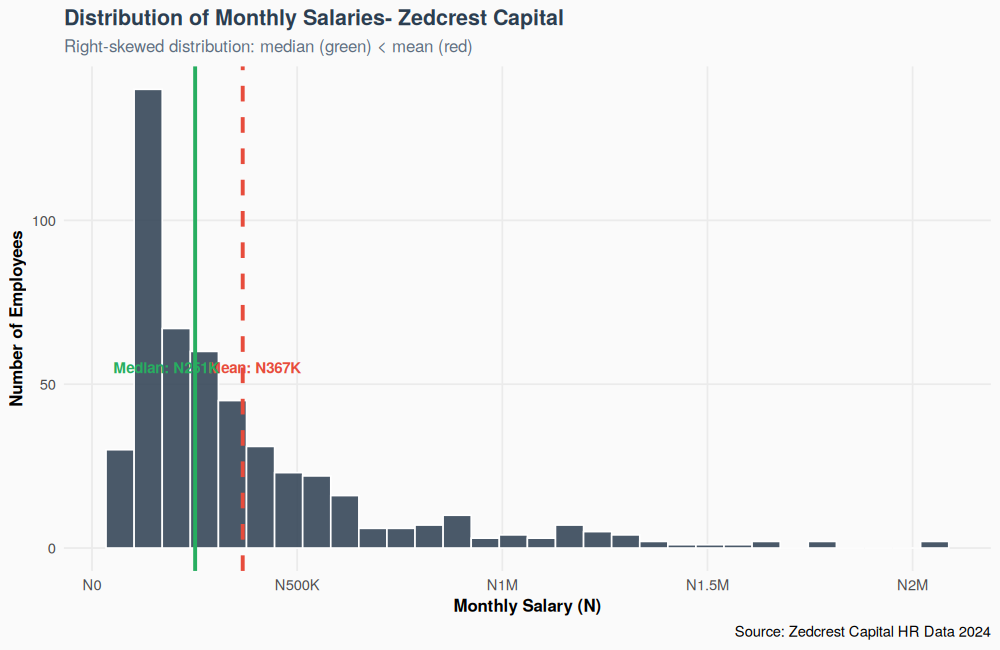

In [10]:
# =============================================================================
# STEP 2.4- VISUALISING SALARY DISTRIBUTION WITH ggplot2
# =============================================================================

# ggplot2 uses the "Grammar of Graphics":
# Every chart = data + aesthetics (aes) + geometry (geom) + scales + labels

p_hist <- ggplot(employee_clean, aes(x = monthly_salary)) +
  # ggplot(data, aes(x=, y=, colour=, fill=)): creates the base layer
  # aes(): "aesthetics" - maps columns to visual properties (x, y, colour, size)

  geom_histogram(bins = 30, fill = "#2C3E50", colour = "white", alpha = 0.85) +
  # geom_histogram(): the histogram geometry
  # bins=30: number of equal-width bars
  # fill: bar colour; colour: border colour; alpha: transparency (0=transparent, 1=opaque)

  geom_vline(xintercept = mean(employee_clean$monthly_salary),
             colour = "#E74C3C", linetype = "dashed", linewidth = 1.2) +
  # geom_vline(): vertical reference line at the mean
  # xintercept: x-position; linetype="dashed": dashed line style

  geom_vline(xintercept = median(employee_clean$monthly_salary),
             colour = "#27AE60", linetype = "solid", linewidth = 1.2) +
  # Second vertical line for median (solid green)

  scale_x_continuous(labels = function(x) naira_fmt(x)) +
  # scale_x_continuous(labels=): applies our custom naira formatter to x-axis

  annotate("text", x = mean(employee_clean$monthly_salary) * 1.08,
           y = 55, label = paste("Mean:", naira_fmt(mean(employee_clean$monthly_salary))),
           colour = "#E74C3C", size = 3.5, fontface = "bold") +
  # annotate(): adds text/shapes directly to the chart at specific coordinates

  annotate("text", x = median(employee_clean$monthly_salary) * 0.72,
           y = 55, label = paste("Median:", naira_fmt(median(employee_clean$monthly_salary))),
           colour = "#27AE60", size = 3.5, fontface = "bold") +

  labs(
    title    = "Distribution of Monthly Salaries- Zedcrest Capital",
    subtitle = "Right-skewed distribution: median (green) < mean (red)",
    x        = "Monthly Salary (N)",
    y        = "Number of Employees",
    caption  = "Source: Zedcrest Capital HR Data 2024"
  )
  # labs(): sets all text labels on the chart

print(p_hist)


### Line-by-line explanation of cell 22

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>p&#95;hist &lt;- ggplot(employee&#95;clean, aes(x = monthly&#95;salary)) &#43;</code> | <code>ggplot(data, aes(...))</code> creates the empty canvas and declares the data. <code>aes()</code> (aesthetics) **maps** columns to visual roles: here salary on the x-axis. The plot object is stored in <code>p&#95;hist</code>. <code>&#43;</code> adds the next layer. | ggplot2 builds charts in **layers**; nothing is drawn until geometries are added. |
| 2 | <code>geom&#95;histogram(bins = 30, fill = "&#35;2C3E50", colour = "white", alpha = 0.85) &#43;</code> | Draw a histogram with 30 equal-width bins. <code>fill</code> = bar colour (dark slate), <code>colour</code> = bar outline (white), <code>alpha</code> = opacity (0 = invisible, 1 = solid). | White outlines separate the bars. A histogram counts how many rows fall in each interval. With 30 bins across the N1.99M range, each bar is about N66,000 wide. |
| 3 | <code>geom&#95;vline(xintercept = mean(employee&#95;clean&#36;monthly&#95;salary), colour = "&#35;E74C3C", linetype = "dashed", linewidth = 1.2) &#43;</code> | A **vertical line** at x = mean, red, dashed, thick. | Reference line for the mean. <code>linewidth</code> replaced <code>size</code> for lines in ggplot2 3.4+. |
| 4 | <code>geom&#95;vline(xintercept = median(employee&#95;clean&#36;monthly&#95;salary), colour = "&#35;27AE60", linetype = "solid", linewidth = 1.2) &#43;</code> | Second vertical line at the median, green, solid. | Two lines make the mean-median gap visible. |
| 5 | <code>scale&#95;x&#95;continuous(labels = function(x) naira&#95;fmt(x)) &#43;</code> | Format the x-axis tick labels using our <code>naira&#95;fmt</code> function. <code>function(x) ...</code> is an anonymous function. | Axis reads N500K, N1M, N1.5M instead of 500000 ... |
| 6 | <code>annotate("text", x = mean(...) &#42; 1.08, y = 55, label = paste("Mean:", naira&#95;fmt(mean(...))), colour = "&#35;E74C3C", size = 3.5, fontface = "bold") &#43;</code> | <code>annotate()</code> places a piece of text at fixed plot coordinates: x is 8 % to the right of the mean line, y = 55 employees high. <code>paste()</code> joins "Mean:" and the formatted value with a space. | Direct labelling is easier to read than a legend. |
| 7 | <code>annotate("text", x = median(...) &#42; 0.72, y = 55, label = paste("Median:", ...), colour = "&#35;27AE60", ...) &#43;</code> | Same for the median, placed 28 % to the left of its line. | Placement is by trial: text is **centred** on x, so the long labels end up touching (see the picture). |
| 8 | <code>labs(title = ..., subtitle = ..., x = ..., y = ..., caption = ...)</code> | <code>labs()</code> sets the title, subtitle, axis titles and the bottom-right caption. | Every professional chart needs a title, units and a source. |
| 9 | <code>print(p&#95;hist)</code> | Render the stored plot. | Inside scripts and loops ggplot objects must be printed explicitly. |

### Output explained
A histogram with salary (N) on the horizontal axis and number of employees on the vertical axis.

- **Shape.** A tall block at the left (most staff earn under about N300K, with the tallest bar well above 100 employees near N100K to N170K), a steady decline to the right, and a long thin tail reaching N2M with only 1 to 3 employees per bar beyond N1.2M.
- **Green solid line (median).** N251K.
- **Red dashed line (mean).** N367K, to the right of the median.
- **Labels.** "Median: N251K" and "Mean: N367K" overlap in the middle of the chart (a cosmetic flaw: use <code>hjust</code> or wider offsets).
- **Axis labels.** N0, N500K, N1M, N1.5M, N2M formatted by <code>naira&#95;fmt</code>.

### Statistical interpretation
This is the **visual proof of positive skew**: mode < median < mean, which is the classic ordering for right-skewed data. It also shows why parametric tools that assume normality (Z-scores, mean +/- 2sd, Pearson correlation) should be used with caution on salary, and why the analyst should consider a **log transformation** for modelling.

### Notebook cell 23 - "ggplot2 Grammar: How to build any chart"
```
ggplot(data, aes(x, y, colour)) + geom_*() + scale_*() + facet_*() + labs() + theme_*()
```
| geom | Chart | Use when |
|---|---|---|
| <code>geom&#95;histogram()</code> | Histogram | Distribution of one numeric variable |
| <code>geom&#95;bar()</code> | Bar chart (counts) | Frequency of a categorical variable (ggplot counts for you) |
| <code>geom&#95;col()</code> | Bar chart (heights supplied) | You already computed the values |
| <code>geom&#95;point()</code> | Scatter plot | Relationship between two numeric variables |
| <code>geom&#95;line()</code> | Line chart | Change over time |
| <code>geom&#95;boxplot()</code> | Box plot | Compare distributions across groups |
| <code>geom&#95;violin()</code> | Violin plot | Distribution shape across groups |
| <code>geom&#95;density()</code> | Smooth density curve (KDE) | Smooth alternative to a histogram |

---
## Section 3 - Frequency Tables in R (notebook cells 24 to 28)

A **frequency table** counts how many observations fall in each category; **relative frequency** divides each count by the total. They are the numeric partner of a bar chart.

### Cell 25 (Step 3.1) - Base R: <code>table()</code> and <code>prop.table()</code>

**Purpose.** Count employees per department with base R, convert to percentages, and sort.

In [11]:
# =============================================================================
# STEP 3.1- BASE R: table() and prop.table()
# =============================================================================

cat("===== DEPARTMENT FREQUENCY TABLE =====
")

# table(): basic frequency count
dept_table <- table(employee_clean$department)
print(dept_table)

cat("
--- RELATIVE FREQUENCIES (proportions) ---
")
dept_prop <- prop.table(dept_table)
# prop.table(): converts counts to proportions (fractions summing to 1)
print(round(dept_prop * 100, 1))  # multiply by 100 for percentages

cat("
===== SORTED BY FREQUENCY =====
")
print(sort(dept_table, decreasing = TRUE))
# sort(..., decreasing=TRUE): sorts from highest to lowest count


===== DEPARTMENT FREQUENCY TABLE =====

          Audit      Compliance         Finance Human Resources      Operations Risk Management 
             34              53              83              43              74              53 
          Sales      Technology 
             79              81 

--- RELATIVE FREQUENCIES (proportions) ---

          Audit      Compliance         Finance Human Resources      Operations Risk Management 
            6.8            10.6            16.6             8.6            14.8            10.6 
          Sales      Technology 
           15.8            16.2 

===== SORTED BY FREQUENCY =====

        Finance      Technology           Sales      Operations      Compliance Risk Management 
             83              81              79              74              53              53 
Human Resources           Audit 
             43              34 


### Line-by-line explanation of cell 25

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== DEPARTMENT FREQUENCY TABLE =====&#92;n")</code> | Banner. |  |
| 2 | <code>dept&#95;table &lt;- table(employee&#95;clean&#36;department)</code> | <code>table()</code> counts each distinct value of the department column and returns a named integer array of class <code>table</code>. | Fast internal check. Python: <code>value&#95;counts()</code>. |
| 3 | <code>print(dept&#95;table)</code> | Show it. | Levels appear in **alphabetical** (factor) order. |
| 4 | <code>dept&#95;prop &lt;- prop.table(dept&#95;table)</code> | <code>prop.table()</code> divides every count by the total, giving proportions that sum to 1. | Relative frequency: comparable across datasets of different sizes. |
| 5 | <code>print(round(dept&#95;prop &#42; 100, 1))</code> | Multiply by 100 for percentages and round to one decimal. |  |
| 6 | <code>print(sort(dept&#95;table, decreasing = TRUE))</code> | <code>sort(..., decreasing = TRUE)</code> orders counts from largest to smallest. | Ranking shows the biggest departments first. |

### Output explained

| Department | Count | Percent |
|---|---|---|
| Audit | 34 | 6.8 |
| Compliance | 53 | 10.6 |
| Finance | 83 | 16.6 |
| Human Resources | 43 | 8.6 |
| Operations | 74 | 14.8 |
| Risk Management | 53 | 10.6 |
| Sales | 79 | 15.8 |
| Technology | 81 | 16.2 |

Sorted: Finance 83, Technology 81, Sales 79, Operations 74, Compliance 53, Risk Management 53 (tie), Human Resources 43, Audit 34.

### Statistical interpretation
- **Mode of the categorical variable** is Finance (16.6 %).
- **The workforce is not evenly spread.** If all 8 departments were equal each would have 62.5 staff (12.5 %). A chi-square goodness-of-fit test against equal shares gives chi-square = 40.6, df = 7, p < 0.001, so the imbalance is statistically real. The four largest departments (Finance, Technology, Sales, Operations) hold 63.4 % of staff.
- Finance is 2.4 times larger than Audit (83 / 34).

### Cell 26 (Step 3.2) - <code>janitor::tabyl()</code>: report-ready frequency tables

**Purpose.** Produce frequency tables that are already data frames, include a Total row and show tidy percentages, ready to paste into a report.

In [12]:
# =============================================================================
# STEP 3.2- janitor::tabyl()- PROFESSIONAL FREQUENCY TABLES
# tabyl() is far superior to table() for reporting
# =============================================================================

cat("===== DEPARTMENT TABYL (Professional) =====
")

# tabyl(): creates a data frame with counts AND percentages automatically
dept_tabyl <- employee_clean |>
  tabyl(department) |>
  # tabyl(column): frequency table with n (count), percent, and valid_percent
  arrange(desc(n)) |>  # sort by count descending
  adorn_totals() |>    # add a "Total" row at the bottom
  # adorn_totals(): adds sum row - percentage sums to 100%
  adorn_pct_formatting(digits = 1)
  # adorn_pct_formatting(): formats percentages as "22.1%" instead of 0.221

print(dept_tabyl)

cat("
===== GRADE DISTRIBUTION =====
")
employee_clean |>
  tabyl(grade) |>
  arrange(grade) |>  # sort by grade level (factor order)
  adorn_totals() |>
  adorn_pct_formatting(digits = 1) |>
  print()

cat("
===== GENDER BREAKDOWN =====
")
employee_clean |>
  tabyl(gender) |>
  adorn_totals() |>
  adorn_pct_formatting(digits = 1) |>
  print()


===== DEPARTMENT TABYL (Professional) =====
      department   n percent
         Finance  83   16.6%
      Technology  81   16.2%
           Sales  79   15.8%
      Operations  74   14.8%
      Compliance  53   10.6%
 Risk Management  53   10.6%
 Human Resources  43    8.6%
           Audit  34    6.8%
           Total 500  100.0%

===== GRADE DISTRIBUTION =====
    grade   n percent
  Grade 5  74   14.8%
  Grade 6 107   21.4%
  Grade 7  95   19.0%
  Grade 8  82   16.4%
  Grade 9  64   12.8%
 Grade 10  39    7.8%
 Grade 11  30    6.0%
 Grade 12   9    1.8%
    Total 500  100.0%

===== GENDER BREAKDOWN =====
 gender   n percent
 Female 210   42.0%
   Male 290   58.0%
  Total 500  100.0%


### Line-by-line explanation of cell 26

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>dept&#95;tabyl &lt;- employee&#95;clean &#124;&gt;</code> | Start the pipeline. |  |
| 2 | <code>tabyl(department) &#124;&gt;</code> | <code>tabyl(col)</code> builds a data frame with columns <code>department</code>, <code>n</code> (count) and <code>percent</code> (proportion). If the column had <code>NA</code>, it would add <code>valid&#95;percent</code> as well. | Unlike <code>table()</code>, the result is an ordinary data frame that works in a pipe. |
| 3 | <code>arrange(desc(n)) &#124;&gt;</code> | Sort by count, biggest first. | Do this **before** adding the Total row, otherwise the total would be sorted into the middle. |
| 4 | <code>adorn&#95;totals() &#124;&gt;</code> | Append a "Total" row that sums <code>n</code> and <code>percent</code>. | Lets the reader verify that percentages add to 100 %. Default adds a row total ("row"). |
| 5 | <code>adorn&#95;pct&#95;formatting(digits = 1)</code> | Convert proportions such as 0.166 to text "16.6%" with one decimal. | After this step <code>percent</code> is **text**, so do all calculations before this line. |
| 6 | <code>print(dept&#95;tabyl)</code> | Show it. |  |
| 7 | <code>employee&#95;clean &#124;&gt; tabyl(grade) &#124;&gt; arrange(grade) &#124;&gt; adorn&#95;totals() &#124;&gt; adorn&#95;pct&#95;formatting(digits = 1) &#124;&gt; print()</code> | Same idea for grade. <code>arrange(grade)</code> sorts by the **factor order** (Grade 5, 6, ... 12) because grade is an ordered factor. | Without the ordered factor this would sort "Grade 10" before "Grade 5". The final <code>&#124;&gt; print()</code> is needed because this chain is not assigned to a name and sits after <code>cat()</code> calls. |
| 8 | <code>employee&#95;clean &#124;&gt; tabyl(gender) &#124;&gt; adorn&#95;totals() &#124;&gt; adorn&#95;pct&#95;formatting(digits = 1) &#124;&gt; print()</code> | Same for gender (no sorting). |  |

### Output explained

**Department (sorted by count).** Finance 83 (16.6 %), Technology 81 (16.2 %), Sales 79 (15.8 %), Operations 74 (14.8 %), Compliance 53 (10.6 %), Risk Management 53 (10.6 %), Human Resources 43 (8.6 %), Audit 34 (6.8 %), **Total 500 (100.0 %)**.

**Grade (in rank order).**

| Grade | n | % |
|---|---|---|
| Grade 5 | 74 | 14.8 |
| Grade 6 | 107 | 21.4 |
| Grade 7 | 95 | 19.0 |
| Grade 8 | 82 | 16.4 |
| Grade 9 | 64 | 12.8 |
| Grade 10 | 39 | 7.8 |
| Grade 11 | 30 | 6.0 |
| Grade 12 | 9 | 1.8 |
| Total | 500 | 100.0 |

**Gender.** Female 210 (42.0 %), Male 290 (58.0 %), Total 500.

### Statistical interpretation
- **A classic pyramid.** Grade 6 is the most common grade (21.4 %). Grades 5 to 8 hold 71.6 % of staff (358 people); Grades 10 to 12 hold only 15.6 % (78 people); the top grade has just 9 people (1.8 %). This shape explains the salary skew.
- **Gender balance.** Men are 58 %. A binomial test against a 50/50 split gives p = 0.0004, so the male majority is statistically significant, not sampling noise.
- **All three totals are exactly 500**, confirming no rows were lost.

### Notebook cell 27 - <code>tabyl()</code> vs <code>table()</code>
| Feature | <code>table()</code> | <code>tabyl()</code> |
|---|---|---|
| Output type | Named array | Data frame (tibble-compatible) |
| Percentages | Need <code>prop.table()</code> | Built in |
| Total row | Needs <code>addmargins()</code> | <code>adorn&#95;totals()</code> |
| Formatting | Manual | <code>adorn&#95;pct&#95;formatting()</code> |
| Pipe friendly | Limited | Full |
| Two variables | Clunky | <code>tabyl(a, b)</code> |

Recommendation: <code>tabyl()</code> for reports, <code>table()</code> for quick checks. (The notebook's "Expected Output" for departments shows different counts, for example Finance 88; your real Finance count is 83.)

### Cell 28 (Step 3.3) - Visualising frequencies with a bar chart

**Purpose.** Turn the department frequency table into a sorted horizontal bar chart with count and percentage labels.

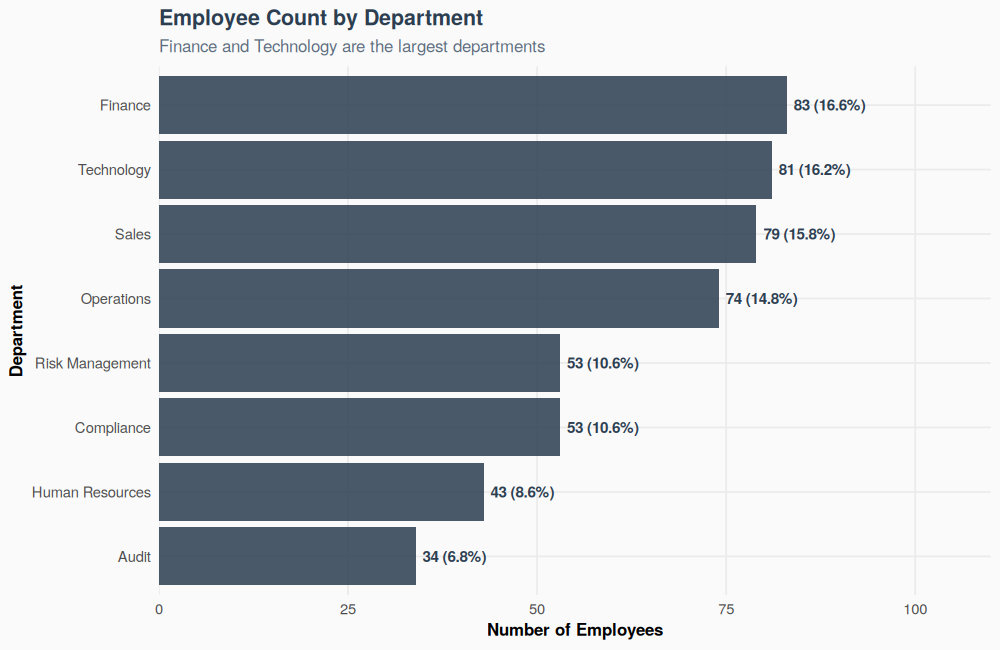

In [13]:
# =============================================================================
# STEP 3.3- VISUALISE FREQUENCIES WITH ggplot2
# =============================================================================

# Horizontal bar chart of department frequencies
p_dept <- employee_clean |>
  count(department) |>
  # count(col): equivalent of tabyl() but returns a tibble with n column
  # count() is a shortcut for group_by(col) |> summarise(n = n())
  arrange(n) |>
  mutate(department = factor(department, levels = department)) |>
  # reorder factor levels to match sorted order so bars display correctly

  ggplot(aes(x = n, y = department)) +
  # note: for horizontal bars, x = value, y = category
  geom_col(fill = "#2C3E50", alpha = 0.85) +
  # geom_col(): bar chart where you supply the height (n), not counts

  geom_text(aes(label = paste0(n, " (", round(n/sum(n)*100,1), "%)")),
            hjust = -0.1, colour = "#2C3E50", fontface = "bold", size = 3.5) +
  # geom_text(): adds text labels on each bar
  # hjust = -0.1: positions label slightly to the RIGHT of the bar end

  scale_x_continuous(limits = c(0, 110), expand = c(0, 0)) +
  labs(
    title    = "Employee Count by Department",
    subtitle = "Finance and Technology are the largest departments",
    x        = "Number of Employees",
    y        = "Department"
  )

print(p_dept)


### Line-by-line explanation of cell 28

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>p&#95;dept &lt;- employee&#95;clean &#124;&gt;</code> | Start a pipeline whose result is a plot. | You can pipe data all the way into <code>ggplot()</code>. |
| 2 | <code>count(department) &#124;&gt;</code> | <code>count(col)</code> = <code>group&#95;by(col) &#124;&gt; summarise(n = n())</code>. Returns one row per department with column <code>n</code>. | Shortcut for counting. |
| 3 | <code>arrange(n) &#124;&gt;</code> | Sort ascending (smallest first). | Horizontal bars plot the first category at the **bottom**, so ascending order puts the largest at the top. |
| 4 | <code>mutate(department = factor(department, levels = department)) &#124;&gt;</code> | Reset the factor levels to the **current row order**. | ggplot orders categories by factor levels, not by row order. Without this line the bars would stay alphabetical. |
| 5 | <code>ggplot(aes(x = n, y = department)) &#43;</code> | The piped data is the first argument, so only <code>aes()</code> is written. Count on x, department on y. | For horizontal bars, put the value on x and the category on y. |
| 6 | <code>geom&#95;col(fill = "&#35;2C3E50", alpha = 0.85) &#43;</code> | <code>geom&#95;col()</code> draws bars whose length equals the y/x value you supply. (<code>geom&#95;bar()</code> would count rows itself.) | We already counted with <code>count()</code>, so <code>geom&#95;col</code> is the right geom. |
| 7 | <code>geom&#95;text(aes(label = paste0(n, " (", round(n/sum(n)&#42;100,1), "%)")), hjust = -0.1, colour = "&#35;2C3E50", fontface = "bold", size = 3.5) &#43;</code> | Write a text label at the end of each bar: count, then percentage in brackets. <code>hjust = -0.1</code> nudges the text just to the **right** of the bar end. | Direct labels remove the need to read the axis. <code>sum(n)</code> inside <code>aes()</code> is the total across all bars. |
| 8 | <code>scale&#95;x&#95;continuous(limits = c(0, 110), expand = c(0, 0)) &#43;</code> | Force the x-axis to run from 0 to 110 and remove the default padding. | Leaves blank space to the right so the text labels are not cut off (largest bar = 83). **Caution:** limits smaller than the data delete bars; that is the exact bug found later in cell 64. |
| 9 | <code>labs(title = ..., subtitle = ..., x = ..., y = ...)</code> | Titles and axis names. |  |
| 10 | <code>print(p&#95;dept)</code> | Render. |  |

### Output explained
A horizontal bar chart. Top to bottom: Finance (83, 16.6 %), Technology (81, 16.2 %), Sales (79, 15.8 %), Operations (74, 14.8 %), Risk Management (53, 10.6 %), Compliance (53, 10.6 %), Human Resources (43, 8.6 %), Audit (34, 6.8 %). Each bar has its label beside it, and the x-axis runs 0 to about 100.

### Statistical interpretation
The bar chart repeats the frequency table visually: a **descending ranking** with a clear gap between the four large departments (74 to 83) and the four smaller ones (34 to 53). The subtitle "Finance and Technology are the largest departments" is correct. Bars must start at zero (they do); truncating the axis would exaggerate differences.

---
## Section 4 - Crosstabulation (Cross-Tables) in R (notebook cells 29 to 34)

A **crosstab** (contingency table) counts observations at each combination of two categorical variables. It answers: *does the distribution of one variable depend on the other?* The statistical test that formalises the answer is the **chi-square test of independence**.

### Cell 30 (Step 4.1) - Department x Gender crosstab with row percentages

**Purpose.** For each department, show the gender split as a percentage **and** the head-count behind it.

In [14]:
# =============================================================================
# STEP 4.1- TWO-WAY CROSSTAB WITH tabyl()
# =============================================================================

cat("===== DEPARTMENT x GENDER CROSSTAB =====
")

dept_gender_cross <- employee_clean |>
  tabyl(department, gender) |>
  # tabyl(row_var, col_var): creates a 2D crosstab
  adorn_totals(where = c("row", "col")) |>
  # adorn_totals(where=): adds totals to both rows ("row") and columns ("col")
  adorn_percentages(denominator = "row") |>
  # adorn_percentages("row"): converts counts to row percentages
  # Each row sums to 100% - shows gender split WITHIN each department
  adorn_pct_formatting(digits = 1) |>
  adorn_ns()
  # adorn_ns(): adds the actual count in parentheses alongside percentage
  # Result: "34.1% (30)" means 34.1% of that group = 30 people

print(dept_gender_cross)


===== DEPARTMENT x GENDER CROSSTAB =====
      department      Female        Male        Total
           Audit 58.8%  (20) 41.2%  (14) 100.0%  (34)
      Compliance 45.3%  (24) 54.7%  (29) 100.0%  (53)
         Finance 32.5%  (27) 67.5%  (56) 100.0%  (83)
 Human Resources 46.5%  (20) 53.5%  (23) 100.0%  (43)
      Operations 39.2%  (29) 60.8%  (45) 100.0%  (74)
 Risk Management 45.3%  (24) 54.7%  (29) 100.0%  (53)
           Sales 41.8%  (33) 58.2%  (46) 100.0%  (79)
      Technology 40.7%  (33) 59.3%  (48) 100.0%  (81)
           Total 42.0% (210) 58.0% (290) 100.0% (500)


### Line-by-line explanation of cell 30

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>dept&#95;gender&#95;cross &lt;- employee&#95;clean &#124;&gt;</code> | Begin the pipeline. |  |
| 2 | <code>tabyl(department, gender) &#124;&gt;</code> | Two-way <code>tabyl</code>: departments as **rows**, genders as **columns**, counts in each cell. | The 2D form of <code>tabyl</code>. Result is a data frame with columns <code>department</code>, <code>Female</code>, <code>Male</code>. |
| 3 | <code>adorn&#95;totals(where = c("row", "col")) &#124;&gt;</code> | Add a **Total row** (column totals) *and* a **Total column** (row totals). Note the naming in janitor: <code>"row"</code> adds a row at the bottom; <code>"col"</code> adds a column at the right. | Totals let you check that every row sums to the department size and that the grand total is 500. |
| 4 | <code>adorn&#95;percentages(denominator = "row") &#124;&gt;</code> | Convert counts into proportions **of each row total**. | Row percentages answer "*within* Finance, what share is female?" Every row sums to 100 %. Use <code>"col"</code> to answer "of all women, what share is in Finance?". |
| 5 | <code>adorn&#95;pct&#95;formatting(digits = 1) &#124;&gt;</code> | Show proportions as text percentages with one decimal. |  |
| 6 | <code>adorn&#95;ns()</code> | Append the **original count** in brackets to each percentage. | Percentages alone hide sample size; <code>58.8% (20)</code> says both. |
| 7 | <code>print(dept&#95;gender&#95;cross)</code> | Show it. |  |

### Output explained (row percentages with counts)

| Department | Female | Male | Total |
|---|---|---|---|
| Audit | 58.8 % (20) | 41.2 % (14) | 34 |
| Compliance | 45.3 % (24) | 54.7 % (29) | 53 |
| Finance | 32.5 % (27) | 67.5 % (56) | 83 |
| Human Resources | 46.5 % (20) | 53.5 % (23) | 43 |
| Operations | 39.2 % (29) | 60.8 % (45) | 74 |
| Risk Management | 45.3 % (24) | 54.7 % (29) | 53 |
| Sales | 41.8 % (33) | 58.2 % (46) | 79 |
| Technology | 40.7 % (33) | 59.3 % (48) | 81 |
| **Total** | **42.0 % (210)** | **58.0 % (290)** | **500** |

### Statistical interpretation
- **Audit is the only female-majority department** (58.8 %). **Finance is the most male** (67.5 %).
- **Human Resources is the most balanced** (46.5 % / 53.5 %, a 7-point gap), followed by Compliance and Risk Management (45.3 % / 54.7 %).
- **Is the variation real?** The notebook does not test it, but a chi-square test of Department x Gender gives chi-square = 8.13, df = 7, **p = 0.32**. The differences between departments are **not statistically significant**: with these sample sizes they could easily arise by chance. So one should not claim that a specific department "discriminates".
- **Row vs column percentages.** The Total row (42.0 % / 58.0 %) is the overall benchmark against which each department is read.

### Notebook cell 31 - "Interpreting Cross-Tables"
The notebook's markdown claims "Human Resources has the most gender-balanced split (55 % Female)" and "Technology has the largest gender gap (64.2 % Male)". Your real data show HR is 46.5 % female (still the most balanced) and the largest gap is in **Finance** (67.5 % male). Always confirm narrative claims against the printed table.

### Cell 32 (Step 4.2) - Grade x Employment Status and the chi-square test

**Purpose.** Ask a retention question: do junior and senior staff differ in the proportion Active / On Leave / Resigned / Suspended? Then test whether the pattern could simply be chance.

In [15]:
# =============================================================================
# STEP 4.2- GRADE x DEPARTMENT CROSSTAB (Counts)
# =============================================================================

cat("===== GRADE x EMPLOYMENT STATUS CROSSTAB =====
")

grade_status <- employee_clean |>
  tabyl(grade, employment_status) |>
  adorn_totals(where = c("row","col")) |>
  adorn_percentages("row") |>
  adorn_pct_formatting(1) |>
  adorn_ns()

print(grade_status)

cat("
===== CHI-SQUARE TEST: Is Grade associated with Employment Status? =====
")

# Chi-square test of independence
chisq_result <- chisq.test(table(employee_clean$grade, employee_clean$employment_status))
# chisq.test(): tests if two categorical variables are statistically independent
# H0: Grade and Employment Status are INDEPENDENT (not related)
# H1: They ARE related

cat("Chi-square statistic:", round(chisq_result$statistic, 3), "
")
cat("Degrees of freedom:  ", chisq_result$parameter, "
")
cat("P-value:             ", round(chisq_result$p.value, 4), "
")
cat("Conclusion:", ifelse(chisq_result$p.value < 0.05,
  "SIGNIFICANT - Grade IS associated with Employment Status (p < 0.05)",
  "NOT significant - No association found (p >= 0.05)"), "
")


===== GRADE x EMPLOYMENT STATUS CROSSTAB =====
    grade       Active   On Leave  Resigned Suspended        Total
  Grade 5  78.4%  (58)  9.5%  (7) 6.8%  (5) 5.4%  (4) 100.0%  (74)
  Grade 6  83.2%  (89)  8.4%  (9) 5.6%  (6) 2.8%  (3) 100.0% (107)
  Grade 7  80.0%  (76)  8.4%  (8) 8.4%  (8) 3.2%  (3) 100.0%  (95)
  Grade 8  75.6%  (62) 12.2% (10) 4.9%  (4) 7.3%  (6) 100.0%  (82)
  Grade 9  81.2%  (52)  7.8%  (5) 4.7%  (3) 6.2%  (4) 100.0%  (64)
 Grade 10  82.1%  (32) 12.8%  (5) 0.0%  (0) 5.1%  (2) 100.0%  (39)
 Grade 11  93.3%  (28)  0.0%  (0) 3.3%  (1) 3.3%  (1) 100.0%  (30)
 Grade 12 100.0%   (9)  0.0%  (0) 0.0%  (0) 0.0%  (0) 100.0%   (9)
    Total  81.2% (406)  8.8% (44) 5.4% (27) 4.6% (23) 100.0% (500)

===== CHI-SQUARE TEST: Is Grade associated with Employment Status? =====
Warning message:
 Chi-squared approximation may be incorrect 
Chi-square statistic: 15.078 
Degrees of freedom:   21 
P-value:              0.819 
Conclusion: NOT significant - No association found (p >= 0.05)

### Line-by-line explanation of cell 32

**The crosstab**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>grade&#95;status &lt;- employee&#95;clean &#124;&gt; tabyl(grade, employment&#95;status) &#124;&gt;</code> | Two-way table: grades as rows, statuses as columns. |  |
| 2 | <code>adorn&#95;totals(where = c("row","col")) &#124;&gt; adorn&#95;percentages("row") &#124;&gt; adorn&#95;pct&#95;formatting(1) &#124;&gt; adorn&#95;ns()</code> | Same four <code>adorn</code> steps as before: totals, row percentages, percent text with 1 decimal, counts in brackets. (<code>"row"</code> and <code>1</code> are positional arguments.) | Row percentages show the status mix within each grade. |
| 3 | <code>print(grade&#95;status)</code> | Show it. |  |

**The test**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>chisq&#95;result &lt;- chisq.test(table(employee&#95;clean&#36;grade, employee&#95;clean&#36;employment&#95;status))</code> | <code>table(a, b)</code> builds the 8 x 4 contingency table. <code>chisq.test()</code> runs **Pearson's chi-square test of independence** and returns a list (statistic, degrees of freedom, p-value, expected counts). Stored in <code>chisq&#95;result</code>. | The correct test for two categorical variables. Under H0 it compares the observed counts with the counts expected if the variables were unrelated. |
| 2 | <code>&#35; H0 / H1 comments</code> | H0 (null hypothesis): grade and status are **independent**. H1: they are related. | Every test needs a stated null hypothesis. |
| 3 | <code>cat("Chi-square statistic:", round(chisq&#95;result&#36;statistic, 3), "&#92;n")</code> | <code>&#36;statistic</code> is the chi-square value: the sum over all cells of (observed - expected)^2 / expected. | Larger = observed counts stray further from independence. |
| 4 | <code>cat("Degrees of freedom:  ", chisq&#95;result&#36;parameter, "&#92;n")</code> | <code>&#36;parameter</code> is the degrees of freedom = (rows - 1) x (columns - 1) = 7 x 3 = 21. | Needed to convert the statistic into a p-value. |
| 5 | <code>cat("P-value:             ", round(chisq&#95;result&#36;p.value, 4), "&#92;n")</code> | <code>&#36;p.value</code> is the probability of getting a statistic at least this large if H0 were true. | The decision quantity. |
| 6 | <code>cat("Conclusion:", ifelse(chisq&#95;result&#36;p.value &lt; 0.05, "SIGNIFICANT ...", "NOT significant ..."), "&#92;n")</code> | If p < 0.05 print the "significant" message, otherwise the "not significant" one. | 0.05 is the conventional significance level (alpha). |

### Output explained

**Crosstab (row %, counts):**

| Grade | Active | On Leave | Resigned | Suspended | Total |
|---|---|---|---|---|---|
| Grade 5 | 78.4 % (58) | 9.5 % (7) | 6.8 % (5) | 5.4 % (4) | 74 |
| Grade 6 | 83.2 % (89) | 8.4 % (9) | 5.6 % (6) | 2.8 % (3) | 107 |
| Grade 7 | 80.0 % (76) | 8.4 % (8) | 8.4 % (8) | 3.2 % (3) | 95 |
| Grade 8 | 75.6 % (62) | 12.2 % (10) | 4.9 % (4) | 7.3 % (6) | 82 |
| Grade 9 | 81.2 % (52) | 7.8 % (5) | 4.7 % (3) | 6.2 % (4) | 64 |
| Grade 10 | 82.1 % (32) | 12.8 % (5) | 0.0 % (0) | 5.1 % (2) | 39 |
| Grade 11 | 93.3 % (28) | 0.0 % (0) | 3.3 % (1) | 3.3 % (1) | 30 |
| Grade 12 | 100.0 % (9) | 0.0 % (0) | 0.0 % (0) | 0.0 % (0) | 9 |
| **Total** | **81.2 % (406)** | **8.8 % (44)** | **5.4 % (27)** | **4.6 % (23)** | **500** |

**Warning line:** <code>Chi-squared approximation may be incorrect</code>.

**Test results:** chi-square = **15.078**, df = **21**, p-value = **0.819**, conclusion **NOT significant**.

### Statistical interpretation
1. **Descriptively** the senior grades look healthier: Active rate hovers between 76 % and 83 % in Grades 5 to 9, then reads 82 % in Grade 10, 93 % in Grade 11 and 100 % in Grade 12. But Grade 12 has only 9 people and Grade 11 has 30, so 100 % and 93 % are fragile.
2. **Inferentially there is no evidence of association.** The chi-square value 15.08 is *below* its own degrees of freedom (21); under independence the expected value of a chi-square statistic equals its df, so the data look completely ordinary. p = 0.819 means that if grade and status were truly unrelated, you would see a pattern at least this strong about 82 % of the time.
3. **Effect size.** Cramer's V = sqrt(15.078 / (500 x 3)) = **0.10**, a negligible association.
4. **Why the warning matters.** Chi-square assumes each cell's expected count is at least 5 (and at least 80 % of cells satisfy it). Here **17 of the 32 cells (53 %)** have expected counts below 5, and the smallest expected count is 0.41. The p-value is therefore approximate. A safer route: <code>chisq.test(tbl, simulate.p.value = TRUE)</code>, Fisher's exact test, or collapsing Grades 10 to 12 into one "senior" band and Resigned + Suspended into "Left/Sanctioned". The conclusion (no association) is very unlikely to change, since the statistic is so small.
5. **Business reading.** Do not tell management that "senior staff are more loyal": the data cannot support it.

### Notebook cell 33 - "Chi-Square Test of Independence"
| Symbol | Meaning |
|---|---|
| H0 | The two variables are independent |
| H1 | They are related |
| p < 0.05 | Reject H0: statistically significant relationship |
| p >= 0.05 | Fail to reject H0: no significant relationship found |

*"Fail to reject" is not the same as "proved independent"; it means the data provide insufficient evidence of a link.*

### Cell 34 (Step 4.3) - Grouped bar chart of the crosstab

**Purpose.** Show Department x Gender counts as side-by-side bars.

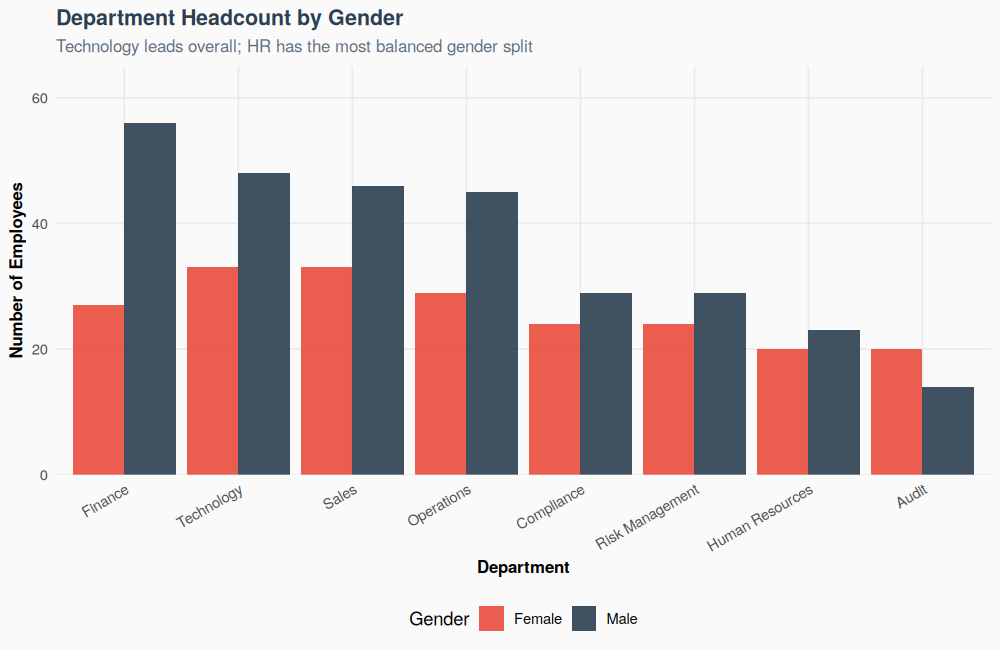

In [16]:
# =============================================================================
# STEP 4.3- VISUALISE CROSSTAB WITH STACKED/GROUPED BARS
# =============================================================================

# Grouped bar chart: Department vs Gender side by side
p_cross <- employee_clean |>
  count(department, gender) |>
  # count(col1, col2): counts combinations of two variables

  ggplot(aes(x = reorder(department, -n), y = n, fill = gender)) +
  # reorder(department, -n): orders departments by count (descending)
  # fill = gender: each gender gets a different colour

  geom_col(position = "dodge", alpha = 0.9) +
  # position = "dodge": places bars side by side (not stacked)
  # position = "stack" would stack them (use for part-of-whole emphasis)
  # position = "fill" would normalise to 100% height

  scale_fill_manual(values = c("Female" = "#E74C3C", "Male" = "#2C3E50")) +
  # scale_fill_manual(): specify exact colours for each fill level

  scale_y_continuous(expand = c(0, 0), limits = c(0, 65)) +
  labs(
    title = "Department Headcount by Gender",
    subtitle = "Technology leads overall; HR has the most balanced gender split",
    x = "Department",
    y = "Number of Employees",
    fill = "Gender"
  ) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
  # theme(axis.text.x = ...): rotate x-axis labels to prevent overlap

print(p_cross)


### Line-by-line explanation of cell 34

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>p&#95;cross &lt;- employee&#95;clean &#124;&gt; count(department, gender) &#124;&gt;</code> | <code>count()</code> with two variables returns one row per department-gender combination (16 rows) with <code>n</code>. | The plot-ready version of the crosstab. |
| 2 | <code>ggplot(aes(x = reorder(department, -n), y = n, fill = gender)) &#43;</code> | <code>reorder(department, -n)</code> orders departments by the (negative) count, so the largest is first; because it averages <code>-n</code> over the two gender rows it effectively orders by department size. <code>fill = gender</code> colours bars by gender. | Sorted bars are easier to compare. Mapping <code>fill</code> inside <code>aes()</code> makes ggplot build a legend automatically. |
| 3 | <code>geom&#95;col(position = "dodge", alpha = 0.9) &#43;</code> | Draw bars; <code>position = "dodge"</code> places the two genders **side by side**. | Alternatives: <code>"stack"</code> (part-of-whole, adds up to the department total) and <code>"fill"</code> (every bar 100 %, shows proportions). |
| 4 | <code>scale&#95;fill&#95;manual(values = c("Female" = "&#35;E74C3C", "Male" = "&#35;2C3E50")) &#43;</code> | Assign exact colours to each level by name. | Consistent gender colours across all charts (red = Female, dark blue = Male). |
| 5 | <code>scale&#95;y&#95;continuous(expand = c(0, 0), limits = c(0, 65)) &#43;</code> | Y-axis from 0 to 65, no padding. | Tallest bar is 56, so nothing is cut off. |
| 6 | <code>labs(title = ..., subtitle = ..., x = ..., y = ..., fill = "Gender") &#43;</code> | Text labels; <code>fill = "Gender"</code> renames the legend title. |  |
| 7 | <code>theme(axis.text.x = element&#95;text(angle = 30, hjust = 1))</code> | Rotate x-axis labels 30 degrees and right-align them. | Prevents long names like "Risk Management" from overlapping. |
| 8 | <code>print(p&#95;cross)</code> | Render. |  |

### Output explained
Eight pairs of bars, ordered Finance, Technology, Sales, Operations, Compliance, Risk Management, Human Resources, Audit. In every department except Audit the dark (male) bar is taller than the red (female) bar. The largest bar is Finance male (56). In Audit the female bar (20) is taller than the male bar (14).

### Statistical interpretation
The chart shows **counts**, so the biggest departments have the biggest bars regardless of gender mix; comparing *shares* needs the row-percentage table from cell 30 (or <code>position = "fill"</code>). The subtitle "Technology leads overall; HR has the most balanced gender split" is half right: **Finance** (not Technology) leads overall, and HR is indeed the most balanced.

---
## Section 5 - Correlation Analysis in R (notebook cells 35 to 41)

**Correlation** measures the strength and direction of the **linear** relationship between two numeric variables. Pearson's coefficient <code>r</code> runs from -1 (perfect opposite movement) through 0 (no linear relationship) to +1 (perfect same-direction movement). It is unit-free, so salary (Naira) and age (years) can be compared directly.

Formula: <code>r = covariance(x, y) / (sd(x) x sd(y))</code>. Its square, <code>r^2</code>, is the share of variance in one variable statistically explained by the other.

### Cell 36 (Step 5.1) - <code>cor()</code> and <code>cor.test()</code>

**Purpose.** Test a business belief: *do longer-serving staff earn more?* Compute the correlation, label its strength in words, then test whether it is statistically distinguishable from zero.

In [17]:
# =============================================================================
# STEP 5.1- cor() AND cor.test(): Basic Correlations
# =============================================================================

cat("===== CORRELATION: Salary vs Years of Service =====
")

# cor(): computes Pearson correlation coefficient
r <- cor(employee_clean$monthly_salary, employee_clean$years_of_service, use = "complete.obs")
# use = "complete.obs": ignore rows where either variable is NA
cat("Pearson r:", round(r, 3), "
")

# Interpret the correlation
interpret_r <- function(r) {
  abs_r <- abs(r)
  direction <- ifelse(r > 0, "positive", "negative")
  strength  <- case_when(
    abs_r >= 0.8 ~ "very strong",
    abs_r >= 0.6 ~ "strong",
    abs_r >= 0.4 ~ "moderate",
    abs_r >= 0.2 ~ "weak",
    TRUE         ~ "very weak / negligible"
  )
  paste(strength, direction, "correlation")
}
cat("Interpretation:", interpret_r(r), "
")

# cor.test(): adds statistical significance to the correlation
cat("
--- CORRELATION WITH SIGNIFICANCE TEST ---
")
cor_result <- cor.test(employee_clean$monthly_salary, employee_clean$years_of_service)
cat("r         :", round(cor_result$estimate, 3), "
")
cat("t-statistic:", round(cor_result$statistic, 3), "
")
cat("p-value   :", round(cor_result$p.value, 4), "
")
cat("95% CI    : [", round(cor_result$conf.int[1], 3), ",",
    round(cor_result$conf.int[2], 3), "]
")
cat("Significant?", ifelse(cor_result$p.value < 0.05, "YES (p < 0.05)", "NO"), "
")


===== CORRELATION: Salary vs Years of Service =====
Pearson r: -0.012 
Interpretation: very weak / negligible negative correlation 

--- CORRELATION WITH SIGNIFICANCE TEST ---
r         : -0.012 
t-statistic: -0.278 
p-value   : 0.7815 
95% CI    : [ -0.1 , 0.075 ]
Significant? NO 


### Line-by-line explanation of cell 36

**Part A - the correlation**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>r &lt;- cor(employee&#95;clean&#36;monthly&#95;salary, employee&#95;clean&#36;years&#95;of&#95;service, use = "complete.obs")</code> | <code>cor(x, y)</code> returns Pearson's r (default). <code>use = "complete.obs"</code> drops any pair where either value is <code>NA</code>. | Protects against <code>NA</code> poisoning the answer (any <code>NA</code> would make <code>cor</code> return <code>NA</code>). No NAs remain here, so it is a safeguard. |
| 2 | <code>cat("Pearson r:", round(r, 3), "&#92;n")</code> | Print r to 3 decimals. |  |

**Part B - a reusable interpretation function**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>interpret&#95;r &lt;- function(r) &#123;</code> | Define a function that turns a number into words. | Reusable: called again in cells 38, 55 and others. |
| 2 | <code>abs&#95;r &lt;- abs(r)</code> | Absolute value: strength ignores sign. |  |
| 3 | <code>direction &lt;- ifelse(r &gt; 0, "positive", "negative")</code> | Sign gives the direction. | Positive: both rise together. Negative: one rises as the other falls. |
| 4 | <code>strength &lt;- case&#95;when(abs&#95;r &gt;= 0.8 &#126; "very strong", abs&#95;r &gt;= 0.6 &#126; "strong", abs&#95;r &gt;= 0.4 &#126; "moderate", abs&#95;r &gt;= 0.2 &#126; "weak", TRUE &#126; "very weak / negligible")</code> | Rules checked top to bottom to pick a strength word. | Thresholds are conventions, not laws. Note these thresholds are **more lenient** than the table in the next markdown cell (which calls 0.5 to 0.7 "moderate" and anything under 0.3 negligible). |
| 5 | <code>paste(strength, direction, "correlation")</code> | Join into a phrase, e.g. "very weak / negligible negative correlation". The last expression is the return value. |  |
| 6 | <code>cat("Interpretation:", interpret&#95;r(r), "&#92;n")</code> | Call the function. |  |

**Part C - significance test**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cor&#95;result &lt;- cor.test(employee&#95;clean&#36;monthly&#95;salary, employee&#95;clean&#36;years&#95;of&#95;service)</code> | <code>cor.test()</code> tests H0: the true correlation is 0. Returns a list holding the estimate, t-statistic, df, p-value and confidence interval. | Turns a descriptive number into an inferential statement: is the correlation real or sampling noise? |
| 2 | <code>cat("r         :", round(cor&#95;result&#36;estimate, 3), "&#92;n")</code> | The sample correlation again. | <code>&#36;estimate</code> pulls it from the result list. |
| 3 | <code>cat("t-statistic:", round(cor&#95;result&#36;statistic, 3), "&#92;n")</code> | t = r x sqrt(n - 2) / sqrt(1 - r^2). | Converts r into a standardised test statistic with n - 2 = 498 degrees of freedom. |
| 4 | <code>cat("p-value   :", round(cor&#95;result&#36;p.value, 4), "&#92;n")</code> | Probability of an &#124;r&#124; this large if the true correlation were 0. |  |
| 5 | <code>cat("95% CI    : &#91;", round(cor&#95;result&#36;conf.int&#91;1&#93;, 3), ",", round(cor&#95;result&#36;conf.int&#91;2&#93;, 3), "&#93;&#92;n")</code> | <code>&#36;conf.int</code> holds the lower and upper bound of the 95 % confidence interval (computed with the Fisher z-transformation). <code>&#91;1&#93;</code> and <code>&#91;2&#93;</code> pick the two ends. | The interval expresses how precisely r is estimated. |
| 6 | <code>cat("Significant?", ifelse(cor&#95;result&#36;p.value &lt; 0.05, "YES (p &lt; 0.05)", "NO"), "&#92;n")</code> | Decision rule at the 5 % level. |  |

### Output explained

| Output | Meaning |
|---|---|
| <code>Pearson r: -0.012</code> | Essentially zero; slightly negative |
| <code>Interpretation: very weak / negligible negative correlation</code> | Verbal label |
| <code>r : -0.012</code> | Same estimate |
| <code>t-statistic: -0.278</code> | -0.0125 x sqrt(498) / sqrt(1 - 0.00016) = -0.278 |
| <code>p-value: 0.7815</code> | 78 % chance of seeing |r| this large or larger by luck if there were no relationship |
| <code>95% CI: &#91; -0.1 , 0.075 &#93;</code> | The true population correlation is plausibly anywhere from -0.10 to +0.075 |
| <code>Significant? NO</code> | p is far above 0.05 |

### Statistical interpretation
1. **No relationship between tenure and pay.** r^2 = 0.00015, so years of service explain about **0.015 %** of salary variation. A regression line would lose about N756 per extra year, with no significance.
2. **The confidence interval contains zero**, and is narrow (about +/- 0.09), so the data also rule out even a modest positive link (above about 0.075).
3. **Why?** Because salary is set by grade (Section 2A) and grade is unrelated to years of service in this dataset.
4. **The notebook expected the opposite.** Its text (cell 40) says "Expected positive (experience = higher pay)". The data disagree; the analyst's job is to report what the data say.
5. **Correlation is not causation, and Pearson only measures straight-line association.** A robust check with Spearman rank correlation also gives about -0.04.

### Notebook cell 37 - "Pearson Correlation Coefficient (r) Interpretation"
| |r| | Strength (notebook table) |
|---|---|
| 0.9 to 1.0 | Very strong |
| 0.7 to 0.9 | Strong |
| 0.5 to 0.7 | Moderate |
| 0.3 to 0.5 | Weak |
| below 0.3 | Negligible |

<code>cor.test()</code> adds the p-value: p < 0.05 means the correlation is statistically significant. With n = 500, any |r| above about **0.088** (roughly 1.96 / sqrt(n)) is significant at 5 %, even though it may be practically trivial. **Significant is not the same as important.**

### Cell 38 (Step 5.2) - Full correlation matrix (the cell that failed in your notebook)

**Purpose.** Compute the correlation of **every numeric variable with every other** in one table, then rank how each relates to salary.

**What went wrong in your run.** The original line <code>select(-is&#95;manager)</code> produced:

```
Error in select(): ! Can't select columns that don't exist. x Column `is_manager` doesn't exist.
```

**Cause.** In cell 13 <code>is&#95;manager</code> was converted to a factor. So <code>select(where(is.numeric))</code> had **already** dropped it, and then <code>select(-is&#95;manager)</code> tried to remove a column that was no longer there. Because the error is fatal, R stopped, and every later cell (39 to 64) never ran. **Fix:** <code>select(-any&#95;of("is&#95;manager"))</code>, which silently ignores names that are absent (or simply delete the line).

In [18]:
# =============================================================================
# STEP 5.2- FULL CORRELATION MATRIX
# =============================================================================

cat("===== CORRELATION MATRIX- ALL NUMERIC VARIABLES =====
")

# Select only numeric columns for correlation matrix
numeric_cols <- employee_clean |>
  select(where(is.numeric)) |>
  # select(where(is.numeric)): keeps only columns where is.numeric() is TRUE
  # where() is a tidyselect helper that applies a function to filter columns
  select(-any_of("is_manager"))  # FIXED: is_manager is a factor by now, so where(is.numeric) already dropped it; any_of() stays silent if a name is absent

# Compute correlation matrix
corr_matrix <- cor(numeric_cols, use = "complete.obs")
round(corr_matrix, 3) |> print()

cat("
--- CORRELATIONS WITH MONTHLY SALARY ---
")
salary_cors <- corr_matrix["monthly_salary", ]
# Extract just the row for monthly_salary
salary_cors_sorted <- sort(salary_cors[salary_cors != 1], decreasing = TRUE)
# Remove self-correlation (1.0) and sort
for (nm in names(salary_cors_sorted)) {
  cat(sprintf("  %-25s : %+.3f  (%s)
",
    nm, salary_cors_sorted[nm], interpret_r(salary_cors_sorted[nm])))
}


===== CORRELATION MATRIX- ALL NUMERIC VARIABLES =====
                      age years_of_service monthly_salary annual_bonus performance_score training_hours_ytd
age                 1.000            0.446          0.034        0.037            -0.084              0.048
years_of_service    0.446            1.000         -0.012       -0.041            -0.069             -0.011
monthly_salary      0.034           -0.012          1.000        0.816             0.008              0.012
annual_bonus        0.037           -0.041          0.816        1.000             0.018             -0.024
performance_score  -0.084           -0.069          0.008        0.018             1.000             -0.048
training_hours_ytd  0.048           -0.011          0.012       -0.024            -0.048              1.000
leave_days_used     0.021           -0.034         -0.056       -0.071            -0.062              0.012
                   leave_days_used
age                          0.021
years_of_ser

### Line-by-line explanation of cell 38

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>numeric&#95;cols &lt;- employee&#95;clean &#124;&gt;</code> | Start a pipeline that builds the numeric-only table. |  |
| 2 | <code>select(where(is.numeric)) &#124;&gt;</code> | <code>select()</code> keeps columns. <code>where(is.numeric)</code> is a tidyselect helper: keep columns for which <code>is.numeric()</code> is TRUE. | Correlation is defined only for numbers, so factors and text must go. Selects 7 columns: age, years_of_service, monthly_salary, annual_bonus, performance_score, training_hours_ytd, leave_days_used. |
| 3 | <code>select(-any&#95;of("is&#95;manager"))</code> | FIXED line. A minus sign in <code>select</code> **drops** a column; <code>any&#95;of()</code> tolerates missing names. | Original: <code>select(-is&#95;manager)</code> (fatal error). |
| 4 | <code>corr&#95;matrix &lt;- cor(numeric&#95;cols, use = "complete.obs")</code> | Give <code>cor()</code> a whole table and it returns a square **matrix** of all pairwise correlations. | A 7 x 7 matrix, symmetric, with 1s on the diagonal (each variable with itself). |
| 5 | <code>round(corr&#95;matrix, 3) &#124;&gt; print()</code> | Round every cell to 3 decimals and print. |  |
| 6 | <code>salary&#95;cors &lt;- corr&#95;matrix&#91;"monthly&#95;salary", &#93;</code> | Matrix indexing <code>&#91;row, column&#93;</code>. Row named "monthly_salary", empty column part = all columns. | Extracts salary's correlations with the 7 variables (including itself). |
| 7 | <code>salary&#95;cors&#95;sorted &lt;- sort(salary&#95;cors&#91;salary&#95;cors &#33;= 1&#93;, decreasing = TRUE)</code> | <code>salary&#95;cors &#33;= 1</code> is TRUE for every entry except the self-correlation; that filter removes it; <code>sort(..., decreasing = TRUE)</code> ranks from most positive to most negative. | Removing 1.0 avoids the trivial "salary correlates perfectly with salary" line. |
| 8 | <code>for (nm in names(salary&#95;cors&#95;sorted)) &#123;</code> | Loop over the variable names. |  |
| 9 | <code>cat(sprintf("  %-25s : %&#43;.3f  (%s)&#92;n", nm, salary&#95;cors&#95;sorted&#91;nm&#93;, interpret&#95;r(salary&#95;cors&#95;sorted&#91;nm&#93;)))</code> | <code>sprintf</code> builds a formatted string. <code>%-25s</code> = text left-aligned in 25 characters; <code>%&#43;.3f</code> = number with sign and 3 decimals; <code>%s</code> = text. Arguments fill the three placeholders in order. | Neat aligned columns. Uses <code>interpret&#95;r()</code> from cell 36. |

### Output explained

**Correlation matrix (rounded, upper and lower halves are mirror images):**

| | age | years_of_service | monthly_salary | annual_bonus | performance_score | training_hours_ytd | leave_days_used |
|---|---|---|---|---|---|---|---|
| **age** | 1 | **0.446** | 0.034 | 0.037 | -0.084 | 0.048 | 0.021 |
| **years_of_service** | 0.446 | 1 | -0.012 | -0.041 | -0.069 | -0.011 | -0.034 |
| **monthly_salary** | 0.034 | -0.012 | 1 | **0.816** | 0.008 | 0.012 | -0.056 |
| **annual_bonus** | 0.037 | -0.041 | 0.816 | 1 | 0.018 | -0.024 | -0.071 |
| **performance_score** | -0.084 | -0.069 | 0.008 | 0.018 | 1 | -0.048 | -0.062 |
| **training_hours_ytd** | 0.048 | -0.011 | 0.012 | -0.024 | -0.048 | 1 | 0.012 |
| **leave_days_used** | 0.021 | -0.034 | -0.056 | -0.071 | -0.062 | 0.012 | 1 |

**Ranking against salary:** annual_bonus **+0.816** (very strong positive), age +0.034, training_hours_ytd +0.012, performance_score +0.008, years_of_service -0.012, leave_days_used -0.056 (all "very weak / negligible").

### Statistical interpretation
1. **Two real relationships only.** Salary and bonus (+0.816), and age and years of service (+0.446, moderate: older people have had more time to accumulate service, but many joined late).
2. **Everything else is noise.** With n = 500 the significance threshold is |r| of about 0.088; every other coefficient is smaller than that, so none is statistically significant.
3. **Performance is unpredictable from the other variables.** All its correlations are below 0.09 in absolute value (training hours -0.048, salary +0.008, tenure -0.069). Training hours do **not** improve appraisal scores in this data.
4. **Salary-bonus caution.** The 0.816 is partly *built in*: bonus is 5 to 35 % of salary, and 29 missing bonuses were set to 0. On ranks (Spearman) the salary-bonus correlation falls to about 0.71, showing the zero-fill and skew inflate the Pearson value.
5. **Multicollinearity warning.** If you later model performance or bonus, do not put salary and bonus in the same regression; they carry the same information.
6. **Interpretive limit.** <code>is&#95;manager</code> (a factor now) is excluded, so correlations of 0/1 flags are not shown. A point-biserial correlation would be needed to include them.

### Cell 39 (Step 5.3) - Correlation heat-map with <code>corrplot</code>

**Purpose.** Turn the 7 x 7 number grid into a colour picture where strong relationships pop out.

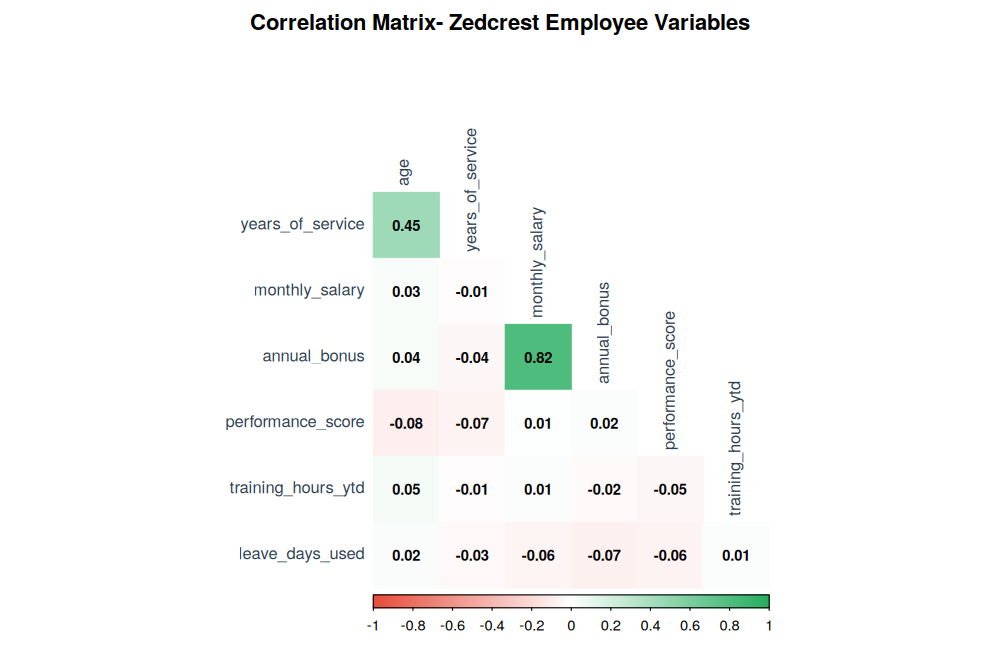

In [19]:
# =============================================================================
# STEP 5.3- VISUALISE CORRELATION MATRIX WITH corrplot
# =============================================================================

# corrplot(): specialised package for beautiful correlation matrix visualisation
corrplot(
  corr_matrix,
  method  = "color",
  # method: "circle" (default), "color", "number", "ellipse", "pie", "shade"
  # "color": filled squares where colour encodes correlation value

  type    = "lower",
  # type="lower": show only lower triangle (upper is identical mirror)

  col     = colorRampPalette(c("#E74C3C","#FFFFFF","#27AE60"))(200),
  # colorRampPalette(): creates a gradient from red (negative) to white (zero) to green (positive)
  # (200): use 200 colours for smooth gradient

  addCoef.col = "black",
  # addCoef.col: show correlation numbers inside each cell

  number.cex  = 0.8,
  # number.cex: size of the correlation numbers

  tl.col  = "#2C3E50",
  # tl.col: text label colour

  tl.cex  = 0.9,
  # tl.cex: size of variable name labels

  diag    = FALSE,
  # diag=FALSE: hide the diagonal (self-correlations are always 1.0)

  title   = "Correlation Matrix- Zedcrest Employee Variables",
  mar     = c(0, 0, 2, 0)
)


### Line-by-line explanation of cell 39

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>corrplot(</code> | Call the <code>corrplot</code> function; all following lines are its arguments. |  |
| 2 | <code>corr&#95;matrix,</code> | The matrix from cell 38 to draw. |  |
| 3 | <code>method = "color",</code> | Fill each cell with a coloured square. Alternatives: <code>"circle"</code> (default), <code>"number"</code>, <code>"ellipse"</code>, <code>"pie"</code>, <code>"shade"</code>. | Colour squares carry the most information per pixel. |
| 4 | <code>type = "lower",</code> | Draw only the lower triangle. | The matrix is symmetric, so the upper triangle duplicates the lower one. |
| 5 | <code>col = colorRampPalette(c("&#35;E74C3C","&#35;FFFFFF","&#35;27AE60"))(200),</code> | <code>colorRampPalette()</code> builds a colour-gradient **function**; calling it with <code>(200)</code> produces 200 shades from red through white to green. | Red = negative, white = zero, green = positive: an intuitive diverging scale. 200 shades make the transition smooth. |
| 6 | <code>addCoef.col = "black",</code> | Print the numeric coefficient in black inside each square. | Colour shows pattern; numbers give exact values. |
| 7 | <code>number.cex = 0.8,</code> | Size of those numbers. |  |
| 8 | <code>tl.col = "&#35;2C3E50",</code> | Colour of the variable labels (text label). |  |
| 9 | <code>tl.cex = 0.9,</code> | Size of the labels. |  |
| 10 | <code>diag = FALSE,</code> | Hide the diagonal. | Self-correlations are always 1 and add no information. |
| 11 | <code>title = "Correlation Matrix- Zedcrest Employee Variables",</code> | Plot title. |  |
| 12 | <code>mar = c(0, 0, 2, 0)</code> | Margins (bottom, left, top, right) in lines; 2 lines at the top. | Without extra top margin <code>corrplot</code> cuts off its own title. |
| 13 | <code>)</code> | End of the call. |  |

### Output explained
A triangular colour grid with a colour bar from -1 (red) to +1 (green). Two squares stand out: **salary x bonus (0.82, dark green)** and **age x years_of_service (0.45, light green)**. All other squares are almost white with small numbers (0.00 to 0.08 in magnitude); the slight pink tint on performance and leave-days rows shows tiny negative values.

### Statistical interpretation
The picture confirms the matrix: the data have a **very sparse correlation structure**. This is unusual for real HR data, where salary, grade, tenure and performance normally interlock. It again indicates simulated data and tells you that predictive models built on these fields would have little signal beyond grade and bonus.

### Notebook cell 40 - Reading the plot, and Pearson vs Spearman vs Kendall
| Type | Use when | Based on | R code |
|---|---|---|---|
| **Pearson** | Roughly linear, no strong outliers, near-normal | Actual values | <code>cor(x, y, method = "pearson")</code> |
| **Spearman** | Skewed data, outliers, or ordinal data | Ranks of the values | <code>cor(x, y, method = "spearman")</code> |
| **Kendall** | Small samples, many ties | Concordant vs discordant pairs | <code>cor(x, y, method = "kendall")</code> |

For salary (skewness 2.14) **Spearman is the more appropriate coefficient**. The notebook's "expected" findings (salary rises with tenure, training raises performance, age strongly tied to tenure) are only borne out for the last one.

### Cell 41 (Step 5.4) - Scatter plot with regression line

**Purpose.** *Look* at the relationship behind r = -0.012. Numbers can hide curves, clusters and outliers; a scatter plot does not.

`geom_smooth()` using formula = 'y ~ x'


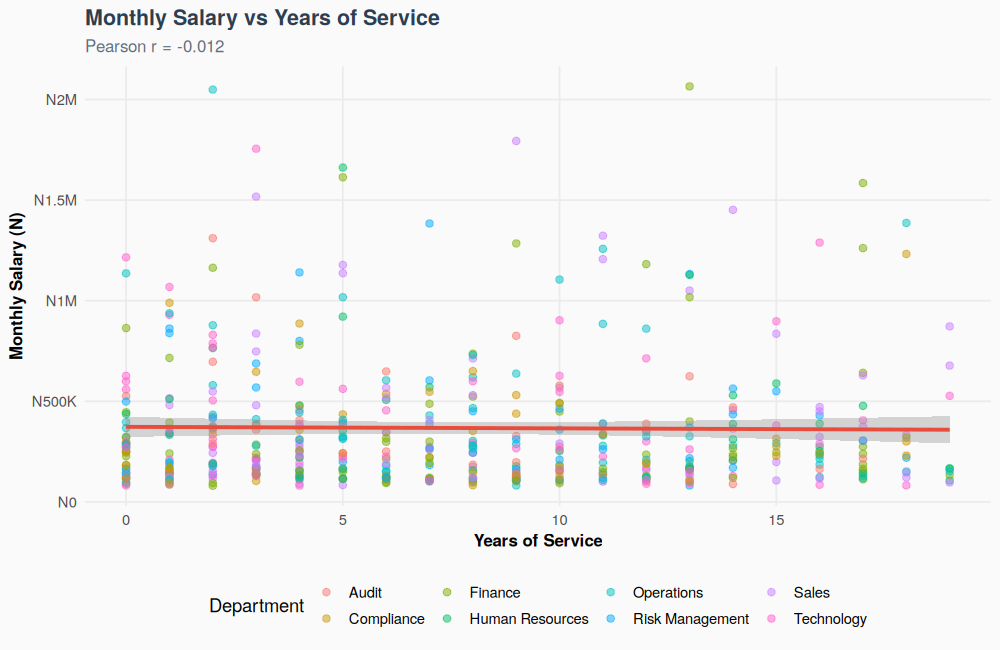

In [20]:
# =============================================================================
# STEP 5.4- SCATTER PLOT WITH CORRELATION LINE
# =============================================================================

p_scatter <- ggplot(employee_clean, aes(x = years_of_service, y = monthly_salary)) +
  geom_point(aes(colour = department), alpha = 0.5, size = 2) +
  # geom_point(): scatter plot dots
  # colour = department: colour each dot by department
  # alpha = 0.5: 50% transparency so overlapping dots are visible

  geom_smooth(method = "lm", colour = "#E74C3C", linewidth = 1.2, se = TRUE) +
  # geom_smooth(method="lm"): adds a linear regression trend line
  # method="lm": linear model (straight line)
  # se=TRUE: shows the confidence interval shading around the line
  # method="loess": would give a curved smooth line instead

  scale_y_continuous(labels = function(x) naira_fmt(x)) +

  labs(
    title    = "Monthly Salary vs Years of Service",
    subtitle = paste0("Pearson r = ", round(cor(employee_clean$monthly_salary,
               employee_clean$years_of_service), 3)),
    x        = "Years of Service",
    y        = "Monthly Salary (N)",
    colour   = "Department"
  )

print(p_scatter)


### Line-by-line explanation of cell 41

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>p&#95;scatter &lt;- ggplot(employee&#95;clean, aes(x = years&#95;of&#95;service, y = monthly&#95;salary)) &#43;</code> | Canvas: years of service on x, salary on y. | Convention: put the explanatory variable on x and the outcome on y. |
| 2 | <code>geom&#95;point(aes(colour = department), alpha = 0.5, size = 2) &#43;</code> | Draw one dot per employee, coloured by department (mapping inside <code>aes</code>). <code>alpha = 0.5</code> makes overlapping points visible; <code>size = 2</code> sets dot size. | Adding a third variable through colour shows whether departments form clusters. |
| 3 | <code>geom&#95;smooth(method = "lm", colour = "&#35;E74C3C", linewidth = 1.2, se = TRUE) &#43;</code> | Add a **linear model** trend line (<code>"lm"</code> = least-squares straight line). <code>se = TRUE</code> shades the 95 % confidence band around it. | <code>method = "loess"</code> would draw a flexible curve instead. R prints the message <code>geom&#95;smooth() using formula = y &#126; x</code>. |
| 4 | <code>scale&#95;y&#95;continuous(labels = function(x) naira&#95;fmt(x)) &#43;</code> | Naira-formatted y-axis. |  |
| 5 | <code>labs(title = "Monthly Salary vs Years of Service", subtitle = paste0("Pearson r = ", round(cor(...), 3)), ...)</code> | The subtitle is **computed**: <code>paste0</code> glues text and the r value calculated on the spot. | The subtitle can never go out of date with the data. |
| 6 | <code>print(p&#95;scatter)</code> | Render. |  |

### Output explained
Salary (N0 to N2M) against years of service (0 to 19). Dots form **vertical columns** at each whole year (because tenure is a whole number) and are stacked in horizontal bands (the grade bands). The red regression line is **flat**, sitting at about N367K across all years, with a grey confidence band about +/- N50K wide (wider at the ends). Colours (departments) are thoroughly mixed. The subtitle reads <code>Pearson r = -0.012</code>.

### Statistical interpretation
- **Flat line = no linear relationship**, matching the non-significant <code>cor.test</code>.
- **Bands** reveal that salary jumps in steps of grade rather than rising smoothly with experience. Employees with 0 years of service appear at Grade 11 or 12 salaries and 19-year veterans at Grade 5 salaries, which is very unusual in practice.
- **Heteroscedasticity:** the vertical spread is the same at every tenure level, and the few highest dots (N1.5M to N2M) are visible outliers that pull the (flat) line slightly.
- A straight-line summary is a poor description of this cloud; the relevant drivers are the categorical variables (grade), not tenure.

---
## Section 6 - Outlier Detection in R (notebook cells 42 to 46)

An **outlier** is a value far from the bulk of the data. It may be an **error** (typo, wrong unit), a **rare genuine value** (a CEO's salary), or evidence of a **different population** (fraud). The action depends on which: fix, keep, or investigate. Detection methods only *flag*; a human must *judge*.

### Cell 43 (Step 6.1) - IQR method (Tukey's fences)

**Purpose.** Build a reusable function that flags outliers by the IQR rule, and apply it to salary. Rule: a value is an outlier if it lies below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.

In [21]:
# =============================================================================
# STEP 6.1- IQR METHOD (Tukey's Fence)- Most Common in Business Analytics
# =============================================================================

cat("===== IQR OUTLIER DETECTION- MONTHLY SALARY =====
")

detect_outliers_iqr <- function(x, multiplier = 1.5) {
  # A reusable function for IQR-based outlier detection
  q1    <- quantile(x, 0.25, na.rm = TRUE)
  q3    <- quantile(x, 0.75, na.rm = TRUE)
  iqr   <- q3 - q1
  lower <- q1 - multiplier * iqr   # lower fence
  upper <- q3 + multiplier * iqr   # upper fence
  is_outlier <- x < lower | x > upper
  # | is the OR operator in R (equivalent to | in Python)

  list(
    # list(): R's equivalent of a Python dictionary
    q1         = q1,
    q3         = q3,
    iqr        = iqr,
    lower_fence = lower,
    upper_fence = upper,
    n_outliers = sum(is_outlier, na.rm = TRUE),
    pct_outliers = round(mean(is_outlier, na.rm = TRUE) * 100, 2),
    outlier_mask = is_outlier
  )
}

sal_outliers <- detect_outliers_iqr(employee_clean$monthly_salary)

cat("Q1 (25th percentile)  : N", formatC(sal_outliers$q1, format="f", digits=0, big.mark=","), "
")
cat("Q3 (75th percentile)  : N", formatC(sal_outliers$q3, format="f", digits=0, big.mark=","), "
")
cat("IQR (Q3 - Q1)         : N", formatC(sal_outliers$iqr, format="f", digits=0, big.mark=","), "
")
cat("Lower fence (Q1-1.5xIQR):", formatC(sal_outliers$lower_fence, format="f", digits=0, big.mark=","), "
")
cat("Upper fence (Q3+1.5xIQR):", formatC(sal_outliers$upper_fence, format="f", digits=0, big.mark=","), "
")
cat("Outliers detected     :", sal_outliers$n_outliers, "(", sal_outliers$pct_outliers, "% )
")

# Show the actual outlier records
outlier_employees <- employee_clean[sal_outliers$outlier_mask, ] |>
  select(employee_id, department, grade, monthly_salary, years_of_service)
cat("
Outlier employee records:
")
print(outlier_employees)


===== IQR OUTLIER DETECTION- MONTHLY SALARY =====
Q1 (25th percentile)  : N 147,628 
Q3 (75th percentile)  : N 449,217 
IQR (Q3 - Q1)         : N 301,589 
Lower fence (Q1-1.5xIQR): -304,755 
Upper fence (Q3+1.5xIQR): 901,600 
Outliers detected     : 39 ( 7.8 % )

Outlier employee records:
# A tibble: 39 × 5
   employee_id department      grade    monthly_salary years_of_service
   <chr>       <fct>           <ord>             <dbl>            <dbl>
 1 ZED-1086    Finance         Grade 12        1585027               17
 2 ZED-1046    Sales           Grade 11        1206644               11
 3 ZED-1295    Risk Management Grade 11        1132581               13
 4 ZED-1415    Audit           Grade 11        1310746                2
 5 ZED-1039    Technology      Grade 11         929555                1
 6 ZED-1416    Operations      Grade 11        1104823               10
 7 ZED-1337    Finance         Grade 12        1613502                5
 8 ZED-1036    Compliance      Grade 11    

### Line-by-line explanation of cell 43

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>detect&#95;outliers&#95;iqr &lt;- function(x, multiplier = 1.5) &#123;</code> | Function with input <code>x</code> (a numeric vector) and an optional argument <code>multiplier</code> that **defaults** to 1.5. | Tukey's 1.5 is the classic choice; 3 finds only "far out" values. A default keeps calls short but allows changes. |
| 2 | <code>q1 &lt;- quantile(x, 0.25, na.rm = TRUE)</code> | First quartile: 25 % of values fall below it. | <code>na.rm = TRUE</code> ignores missing values. |
| 3 | <code>q3 &lt;- quantile(x, 0.75, na.rm = TRUE)</code> | Third quartile. |  |
| 4 | <code>iqr &lt;- q3 - q1</code> | Interquartile range. | Spread of the middle 50 %; robust to outliers. |
| 5 | <code>lower &lt;- q1 - multiplier &#42; iqr</code> | Lower fence. |  |
| 6 | <code>upper &lt;- q3 &#43; multiplier &#42; iqr</code> | Upper fence. |  |
| 7 | <code>is&#95;outlier &lt;- x &lt; lower &#124; x &gt; upper</code> | A TRUE/FALSE vector: TRUE if below the lower fence **or** (<code>&#124;</code>) above the upper fence. <code>&#124;</code> is the vectorised OR, comparing element by element. | Use <code>&#124;</code> (not <code>&#124;&#124;</code>) for whole vectors. <code>&#124;&#124;</code> looks at only the first element. |
| 8 | <code>list(q1 = q1, q3 = q3, iqr = iqr, lower&#95;fence = lower, upper&#95;fence = upper, n&#95;outliers = sum(is&#95;outlier, na.rm = TRUE), pct&#95;outliers = round(mean(is&#95;outlier, na.rm = TRUE) &#42; 100, 2), outlier&#95;mask = is&#95;outlier)</code> | Return a **list** (like a Python dictionary) with named results: the quartiles, fences, count of outliers, percentage of outliers and the full TRUE/FALSE vector. | A function can return only one object, so several results are packaged in a list and read later with <code>&#36;</code>. |
| 9 | <code>sal&#95;outliers &lt;- detect&#95;outliers&#95;iqr(employee&#95;clean&#36;monthly&#95;salary)</code> | Run the function on salary. |  |
| 10 | <code>cat("Q1 (25th percentile)  : N", formatC(sal&#95;outliers&#36;q1, format="f", digits=0, big.mark=","), "&#92;n")</code> | <code>&#36;q1</code> reads that item of the list; <code>formatC</code> formats it without decimals and with commas. | Repeated for Q3, IQR, lower fence and upper fence. |
| 11 | <code>cat("Outliers detected     :", sal&#95;outliers&#36;n&#95;outliers, "(", sal&#95;outliers&#36;pct&#95;outliers, "% )&#92;n")</code> | Count and percentage of flagged employees. |  |
| 12 | <code>outlier&#95;employees &lt;- employee&#95;clean&#91;sal&#95;outliers&#36;outlier&#95;mask, &#93; &#124;&gt; select(employee&#95;id, department, grade, monthly&#95;salary, years&#95;of&#95;service)</code> | Row-filter with a logical vector: <code>df&#91;TRUE/FALSE vector, &#93;</code> keeps rows where TRUE (the empty space after the comma means "all columns"). Then <code>select</code> keeps five columns. | Lists **who** the outliers are so they can be inspected, not just counted. |
| 13 | <code>cat("&#92;nOutlier employee records:&#92;n"); print(outlier&#95;employees)</code> | Show the table. | Tibbles print 10 rows and say <code>&#35; i 29 more rows</code>. |

### Output explained

| Line | Value | Calculation |
|---|---|---|
| Q1 | N147,628 | 25th percentile |
| Q3 | N449,217 | 75th percentile |
| IQR | N301,589 | 449,217 - 147,628 |
| Lower fence | **-304,755** | 147,628 - 1.5 x 301,589. Negative, so **no salary can ever be a low outlier** |
| Upper fence | **901,600** | 449,217 + 1.5 x 301,589 |
| Outliers detected | **39 (7.8 %)** | count of salaries above N901,600 |

The record table (39 x 5) begins: ZED-1086 Finance Grade 12 N1,585,027; ZED-1046 Sales Grade 11 N1,206,644; ZED-1295 Risk Management Grade 11 N1,132,581; ZED-1415 Audit Grade 11 N1,310,746; ... <code>&#35; 29 more rows</code>.

### Statistical interpretation
1. **These are not errors.** All 39 flagged employees are in **Grade 11 (30 people) or Grade 12 (9 people)**, which is *every* member of those two grades (the lowest Grade 11 salary, N902,927, is just above the fence). The IQR rule has simply detected the top of the pay scale. Nobody should be deleted or "corrected".
2. **7.8 % flagged** is far above the roughly 0.7 % expected for a normal distribution, another symptom of the right-skew and heavy tails.
3. **Lesson.** Outlier tests on a variable governed by a hidden category (grade) flag whole categories. Detect outliers **within** groups (as cell 45 does by department, or by grade) to find genuinely unusual values, for example a Grade 6 employee paid like Grade 10.
4. **Robustness.** The IQR method is based on quartiles, which are not moved by the extreme values themselves.

### Cell 44 (Step 6.2) - Z-score method

**Purpose.** Apply the second classic rule: a value more than 3 standard deviations from the mean is an outlier. Standardising also produces a scale-free score for every employee.

In [22]:
# =============================================================================
# STEP 6.2- Z-SCORE METHOD
# =============================================================================

cat("===== Z-SCORE OUTLIER DETECTION =====
")

employee_clean <- employee_clean |>
  mutate(
    salary_zscore = (monthly_salary - mean(monthly_salary)) / sd(monthly_salary),
    # Z-score formula: (value - mean) / standard_deviation
    # Z > 3 or Z < -3: considered an outlier (outside 99.7% of normal distribution)
    is_salary_outlier_z = abs(salary_zscore) > 3
    # abs(): absolute value. We flag both extremely high AND extremely low salaries
  )

n_z_outliers <- sum(employee_clean$is_salary_outlier_z)
cat("Outliers by Z-score (|Z| > 3):", n_z_outliers, "
")

# Show distribution of Z-scores
cat("
Z-score distribution:
")
print(summary(employee_clean$salary_zscore))

cat("
Top 5 highest Z-scores (most extreme high earners):
")
employee_clean |>
  arrange(desc(salary_zscore)) |>
  select(employee_id, department, grade, monthly_salary, salary_zscore) |>
  head(5) |>
  print()


===== Z-SCORE OUTLIER DETECTION =====
Outliers by Z-score (|Z| > 3): 11 

Z-score distribution:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-0.8648 -0.6614 -0.3491  0.0000  0.2467  5.1126 

Top 5 highest Z-scores (most extreme high earners):
# A tibble: 5 × 5
  employee_id department      grade    monthly_salary salary_zscore
  <chr>       <fct>           <ord>             <dbl>         <dbl>
1 ZED-1352    Finance         Grade 12        2065381          5.11
2 ZED-1029    Operations      Grade 12        2049388          5.06
3 ZED-1371    Sales           Grade 12        1794011          4.30
4 ZED-1326    Technology      Grade 12        1755287          4.18
5 ZED-1381    Human Resources Grade 12        1661902          3.90


### Line-by-line explanation of cell 44

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>employee&#95;clean &lt;- employee&#95;clean &#124;&gt; mutate(</code> | **Overwrites** <code>employee&#95;clean</code> with a version having two new columns. | Side effect: the table now has **17** columns, which is why later outputs (cells 48 and 50) report 17 columns. |
| 2 | <code>salary&#95;zscore = (monthly&#95;salary - mean(monthly&#95;salary)) / sd(monthly&#95;salary),</code> | Z = (value - mean) / standard deviation, for every row. | Expresses each salary as "how many standard deviations from the average". The new column has mean 0 and sd 1. |
| 3 | <code>is&#95;salary&#95;outlier&#95;z = abs(salary&#95;zscore) &gt; 3</code> | <code>abs()</code> ignores sign, so both very high and very low scores are flagged. Result: a TRUE/FALSE column. | For a normal distribution 99.7 % of values lie within 3 sd, so beyond that is suspicious. |
| 4 | <code>n&#95;z&#95;outliers &lt;- sum(employee&#95;clean&#36;is&#95;salary&#95;outlier&#95;z)</code> | Sum of TRUE/FALSE = number of TRUEs. |  |
| 5 | <code>cat("Outliers by Z-score (&#124;Z&#124; &gt; 3):", n&#95;z&#95;outliers, "&#92;n")</code> | Print the count. |  |
| 6 | <code>print(summary(employee&#95;clean&#36;salary&#95;zscore))</code> | Six-number summary of the Z-scores. | A quick look at the distribution of standardised values. |
| 7 | <code>employee&#95;clean &#124;&gt; arrange(desc(salary&#95;zscore)) &#124;&gt; select(employee&#95;id, department, grade, monthly&#95;salary, salary&#95;zscore) &#124;&gt; head(5) &#124;&gt; print()</code> | Sort by Z descending, keep 5 columns, take the top 5 rows, print. | Shows the most extreme individuals. |

### Output explained

<code>Outliers by Z-score (&#124;Z&#124; &gt; 3): 11</code>

| Statistic of Z | Min | Q1 | Median | Mean | Q3 | Max |
|---|---|---|---|---|---|---|
| Value | -0.8648 | -0.6614 | -0.3491 | 0.0000 | 0.2467 | 5.1126 |

Top 5 highest Z-scores:

| Employee | Department | Grade | Salary (N) | Z |
|---|---|---|---|---|
| ZED-1352 | Finance | Grade 12 | 2,065,381 | 5.11 |
| ZED-1029 | Operations | Grade 12 | 2,049,388 | 5.06 |
| ZED-1371 | Sales | Grade 12 | 1,794,011 | 4.30 |
| ZED-1326 | Technology | Grade 12 | 1,755,287 | 4.18 |
| ZED-1381 | Human Resources | Grade 12 | 1,661,902 | 3.90 |

### Statistical interpretation
1. **Z-score flags 11; IQR flags 39.** The Z method is *less sensitive* here because the outliers themselves inflate the mean and the standard deviation (**masking**). That is why the notebook advises the IQR method for skewed data.
2. **The lowest possible Z is -0.86.** The minimum salary (N80,061) is less than one sd below the mean, so the Z method can never flag a low salary; the distribution is a wall on the left and a tail on the right.
3. **The mean is exactly 0** and sd exactly 1 by construction (floating point shows 5e-17 in <code>skim</code>).
4. **Normal-theory benchmark.** With 500 observations a normal distribution would give about 1.35 values beyond |Z| = 3 (0.27 %). We find 11 (2.2 %), eight times more: heavy tails.
5. **Nine of the eleven are Grade 12 staff** (the highest paid grade), so again these are legitimate senior salaries.

### Cell 45 (Step 6.3) - Box plots by department and box-plot statistics

**Purpose.** Compare salary distributions across departments and count the outliers within each department.


=== BOX PLOT STATISTICS BY DEPARTMENT ===
# A tibble: 8 × 7
  department           Q1  Median      Q3     IQR Upper_Fence N_Outliers
  <fct>             <dbl>   <dbl>   <dbl>   <dbl>       <dbl>      <int>
1 Operations      165659. 279678. 432323. 266664      832319.         10
2 Sales           138885  275854  516042. 377156.    1081776.          7
3 Technology      154034  270267  504260  350226     1029599           4
4 Risk Management 163342  266020  450501  287159      881240.          3
5 Audit           180420. 262621  454374. 273954.     865305.          2
6 Compliance      139087  228730  358404  219317      687380.          3
7 Finance         125250. 227165  385019  259770.     774673.         10
8 Human Resources 155260  220021  412600. 257340.     798609.          3


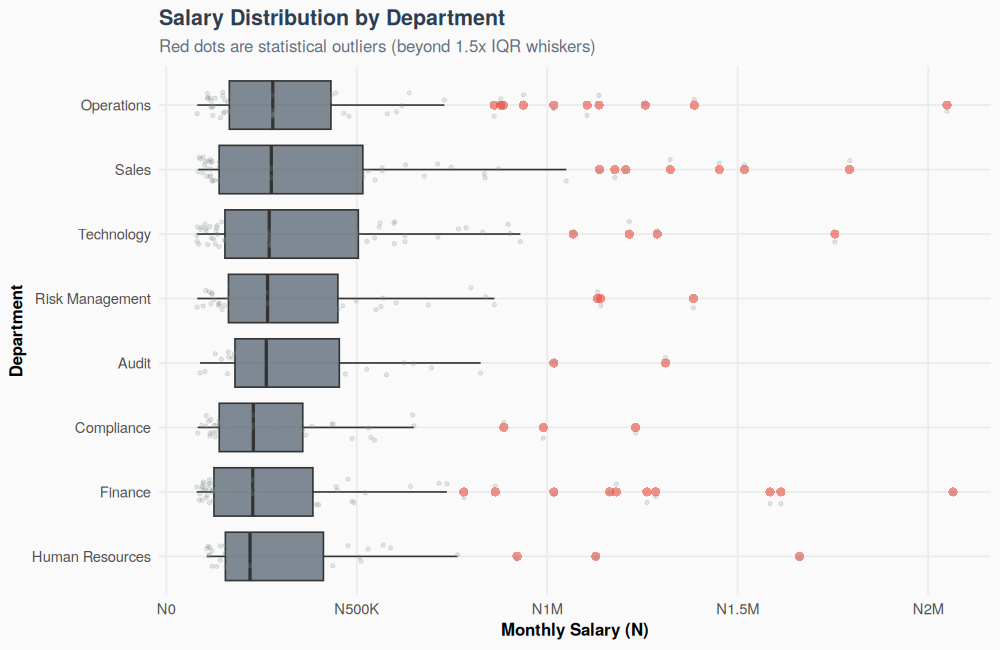

In [23]:
# =============================================================================
# STEP 6.3- OUTLIER VISUALISATION: BOX PLOTS BY GROUP
# =============================================================================

# Box plot: the standard chart for showing outliers visually
p_box <- ggplot(employee_clean, aes(x = reorder(department, monthly_salary, median),
                                    y = monthly_salary)) +
  # reorder(department, monthly_salary, median): orders departments by their median salary

  geom_boxplot(
    fill        = "#2C3E50",
    alpha       = 0.6,
    outlier.colour = "#E74C3C",
    outlier.size   = 2.5,
    outlier.shape  = 16
    # outlier.*: controls appearance of outlier dots that appear beyond whiskers
  ) +
  # A box plot shows:
  # - Box: Q1 to Q3 (middle 50% of data)
  # - Line inside box: Median
  # - Whiskers: extend to 1.5xIQR from Q1 and Q3
  # - Dots beyond whiskers: OUTLIERS

  geom_jitter(alpha = 0.2, width = 0.2, size = 1, colour = "#7F8C8D") +
  # geom_jitter(): adds individual data points with slight horizontal randomness
  # Shows the actual data distribution beneath the box plot
  # alpha=0.2: very transparent so box plot remains visible

  coord_flip() +
  # coord_flip(): rotates the chart 90 degrees (categories on y-axis)

  scale_y_continuous(labels = function(x) naira_fmt(x)) +
  labs(
    title    = "Salary Distribution by Department",
    subtitle = "Red dots are statistical outliers (beyond 1.5x IQR whiskers)",
    x        = "Department",
    y        = "Monthly Salary (N)"
  )

print(p_box)

cat("
=== BOX PLOT STATISTICS BY DEPARTMENT ===
")
employee_clean |>
  group_by(department) |>
  summarise(
    Q1     = quantile(monthly_salary, 0.25),
    Median = median(monthly_salary),
    Q3     = quantile(monthly_salary, 0.75),
    IQR    = IQR(monthly_salary),
    Upper_Fence = Q3 + 1.5*IQR,
    N_Outliers  = sum(monthly_salary > Q3 + 1.5*IQR | monthly_salary < Q1 - 1.5*IQR)
  ) |>
  arrange(desc(Median)) |>
  print()


### Line-by-line explanation of cell 45

**The chart**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>ggplot(employee&#95;clean, aes(x = reorder(department, monthly&#95;salary, median), y = monthly&#95;salary)) &#43;</code> | <code>reorder(department, monthly&#95;salary, median)</code> sorts departments by their **median** salary (third argument is the summary function). | Ordered categories make a ranked comparison easy. |
| 2 | <code>geom&#95;boxplot(fill = "&#35;2C3E50", alpha = 0.6, outlier.colour = "&#35;E74C3C", outlier.size = 2.5, outlier.shape = 16) &#43;</code> | Draw box plots. <code>outlier.&#42;</code> options style the outlier dots (red, size 2.5, shape 16 = solid circle). | The box spans Q1 to Q3, the centre line is the median, whiskers reach the furthest point within 1.5 x IQR, dots beyond are outliers. |
| 3 | <code>geom&#95;jitter(alpha = 0.2, width = 0.2, size = 1, colour = "&#35;7F8C8D") &#43;</code> | Overlay every individual data point with a small random sideways shift ("jitter"). | Shows the raw data behind each box and the sample size. <code>width</code> controls the shift. |
| 4 | <code>coord&#95;flip() &#43;</code> | Swap the axes: departments on the vertical axis. | Long category names read better horizontally. |
| 5 | <code>scale&#95;y&#95;continuous(labels = function(x) naira&#95;fmt(x)) &#43;  labs(...)</code> | Naira axis and titles. Note that after <code>coord&#95;flip</code> the "y" scale is drawn horizontally. |  |
| 6 | <code>print(p&#95;box)</code> | Render. |  |

**The statistics table**

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("&#92;n=== BOX PLOT STATISTICS BY DEPARTMENT ===&#92;n")</code> | Banner. |  |
| 2 | <code>employee&#95;clean &#124;&gt; group&#95;by(department) &#124;&gt; summarise(</code> | Group by department and summarise. |  |
| 3 | <code>Q1 = quantile(monthly&#95;salary, 0.25), Median = median(monthly&#95;salary), Q3 = quantile(monthly&#95;salary, 0.75),</code> | The three quartiles per department. |  |
| 4 | <code>IQR = IQR(monthly&#95;salary),</code> | Width of the middle 50 %. | A new column named <code>IQR</code>; the function <code>IQR()</code> is still callable because R looks for functions separately. |
| 5 | <code>Upper&#95;Fence = Q3 &#43; 1.5&#42;IQR,</code> | Upper fence per department, **using the columns created earlier in the same <code>summarise</code>**. | dplyr evaluates arguments in order, so later ones can use earlier ones. |
| 6 | <code>N&#95;Outliers = sum(monthly&#95;salary &gt; Q3 &#43; 1.5&#42;IQR &#124; monthly&#95;salary &lt; Q1 - 1.5&#42;IQR)</code> | Count values beyond either fence. |  |
| 7 | <code>) &#124;&gt; arrange(desc(Median)) &#124;&gt; print()</code> | Rank by median and display. |  |

### Output explained

The chart: eight horizontal boxes sorted from highest median (top: Operations) to lowest (bottom: Human Resources). All boxes sit between about N140K and N520K with medians near N220K to N280K. Red outlier dots trail to the right, the farthest at about N2.06M (Finance) and N2.05M (Operations).

| Department | Q1 | Median | Q3 | IQR | Upper fence | Outliers |
|---|---|---|---|---|---|---|
| Operations | 165,659 | 279,678 | 432,323 | 266,664 | 832,319 | **10** |
| Sales | 138,885 | 275,854 | 516,042 | 377,156 | 1,081,776 | 7 |
| Technology | 154,034 | 270,267 | 504,260 | 350,226 | 1,029,599 | 4 |
| Risk Management | 163,342 | 266,020 | 450,501 | 287,159 | 881,240 | 3 |
| Audit | 180,420 | 262,621 | 454,374 | 273,954 | 865,305 | 2 |
| Compliance | 139,087 | 228,730 | 358,404 | 219,317 | 687,380 | 3 |
| Finance | 125,250 | 227,165 | 385,019 | 259,770 | 774,673 | **10** |
| Human Resources | 155,260 | 220,021 | 412,600 | 257,340 | 798,609 | 3 |

### Statistical interpretation
- **All eight departments have similar central boxes** and all are skewed right (each median is closer to Q1 than Q3).
- **Within-department outlier counts total 42**, three more than the overall count of 39, because each department has its own (often lower) fence. Operations and Finance have 10 each.
- Sales has the widest box (IQR N377K), Compliance the narrowest (N219K).
- The pattern of "everything similar, tail differs" supports the earlier finding that department does not explain salary.

### Notebook cell 46 - How to read a box plot
| Element | Meaning |
|---|---|
| Box | Q1 to Q3 (middle 50 %) |
| Line inside box | Median |
| Lower whisker | Lowest point no further than Q1 - 1.5 x IQR |
| Upper whisker | Highest point no further than Q3 + 1.5 x IQR |
| Dots beyond whiskers | Outliers |

**IQR vs Z-score.** IQR is robust (based on quartiles) and suits non-normal data; Z-score assumes approximate normality and is distorted by the very outliers it looks for. Note: whiskers stop at the last actual data point inside the fence, not at the fence itself.

---
## Section 7 - Data Profiling in R (notebook cells 47 to 50)

**Data profiling** produces a systematic quality report on the whole dataset: types, missingness, uniqueness, ranges and distribution shapes. It is the "medical check-up" before any modelling.

### Cell 48 (Step 7.1) - <code>skimr::skim()</code>

**Purpose.** One function call that profiles all columns, grouped by data type, with a tiny histogram for each numeric column.

In [24]:
# =============================================================================
# STEP 7.1- skimr::skim()- THE BEST QUICK PROFILING FUNCTION IN R
# Equivalent to Python's df.describe() but far more comprehensive
# =============================================================================

cat("===== COMPREHENSIVE DATA PROFILE: EMPLOYEE DATASET =====
")

# skim() profiles the ENTIRE dataset in one call
# No Python function matches this level of instant profiling
skim(employee_clean)
# skim() output sections:
# - Data Summary: rows, columns, missing values summary
# - Character variables: n_missing, n_unique, min/max string lengths
# - Factor variables: n_missing, n_unique, top counts, ordered status
# - Numeric variables: mean, sd, p0 (min), p25, p50 (median), p75, p100 (max), histogram


===== COMPREHENSIVE DATA PROFILE: EMPLOYEE DATASET =====
-- Data Summary ------------------------
                           Values        
Name                       employee_clean
Number of rows             500           
Number of columns          17            
_______________________                  
Column type frequency:                   
  character                2             
  factor                   6             
  logical                  1             
  numeric                  8             
________________________                 
Group variables            None          

-- Variable type: character ----------------------------------------------------------------------------------
  skim_variable   n_missing complete_rate min max empty n_unique whitespace
1 employee_id             0             1   8   8     0      500          0
2 state_of_origin         0             1   3   7     0        8          0

-- Variable type: factor --------------------------------

### Line-by-line explanation of cell 48

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== COMPREHENSIVE DATA PROFILE: EMPLOYEE DATASET =====&#92;n")</code> | Banner. |  |
| 2 | <code>skim(employee&#95;clean)</code> | <code>skim()</code> scans every column and prints a **Data Summary** followed by one table per variable type (character, factor, logical, numeric). | Combines the jobs of <code>str</code>, <code>summary</code>, missing counts and mini plots. The next lines in the code are comments describing its sections. |

### Output explained

**Data Summary block**

| Item | Value | Meaning |
|---|---|---|
| Name | <code>employee&#95;clean</code> | Object profiled |
| Number of rows | 500 | Cleaned rows |
| Number of columns | **17** | The original 15 plus <code>salary&#95;zscore</code> and <code>is&#95;salary&#95;outlier&#95;z</code> added in cell 44 |
| Column type frequency | character 2, factor 6, logical 1, numeric 8 | <code>grade</code> is counted as a factor here |
| Group variables | None | No <code>group&#95;by</code> active |

**Character variables:** <code>employee&#95;id</code> (min and max length 8, **500 unique**, so it is a proper key) and <code>state&#95;of&#95;origin</code> (8 unique values, lengths 3 to 7). Columns: <code>n&#95;missing</code>, <code>complete&#95;rate</code>, <code>min</code>/<code>max</code> string length, <code>empty</code> (blank strings), <code>n&#95;unique</code>, <code>whitespace</code> (values with stray spaces). All zeros for problems.

**Factor variables:** <code>n&#95;unique</code> and <code>top&#95;counts</code> (abbreviated to 3 letters): department 8 levels (Fin 83, Tec 81, Sal 79, Ope 74); grade 8 levels, <code>ordered = TRUE</code>; gender 2 levels (Mal 290, Fem 210); qualification 7 (B.S 149, M.S 105, HND 95, MBA 73); status 4 (Act 406, On 44, Res 27, Sus 23); is_manager 2 (No 364, Yes 136).

**Logical variable:** <code>is&#95;salary&#95;outlier&#95;z</code>: mean 0.022, i.e. 11 TRUE and 489 FALSE.

**Numeric variables** (<code>complete&#95;rate</code> = 1 for all: no missing values):

| Variable | mean | sd | p0 (min) | p25 | p50 | p75 | p100 (max) | Histogram | Shape |
|---|---|---|---|---|---|---|---|---|---|
| age | 39.7 | 10.5 | 22 | 31 | 40 | 49 | 57 | ▇▇▇▇▇ | Flat (uniform) |
| years_of_service | 7.65 | 5.46 | 0 | 3 | 7 | 12 | 19 | ▇▆▆▅▃ | Gently declining |
| monthly_salary | 367,000 | 332,137 | 80,061 | 147,628 | 251,358 | 449,217 | 2,065,381 | ▇▂▁▁▁ | Strong right skew |
| annual_bonus | 67,400 | 79,309 | 0 | 21,832 | 40,217 | 82,159 | 660,921 | ▇▁▁▁▁ | Extreme right skew |
| performance_score | 3.23 | 0.731 | 1 | 2.8 | 3.2 | 3.7 | 5 | ▁▃▇▅▂ | Bell shape |
| training_hours_ytd | 58.0 | 34.7 | 0 | 29 | 57 | 87 | 119 | ▇▇▆▆▆ | Flat |
| leave_days_used | 10.7 | 6.18 | 0 | 6 | 10 | 16 | 21 | ▇▆▇▆▇ | Flat |
| salary_zscore | 5e-17 | 1 | -0.865 | -0.661 | -0.349 | 0.247 | 5.11 | ▇▂▁▁▁ | Same shape as salary |

The mean column shows values like <code>3.97e&#43; 1</code>, which is scientific notation (3.97 x 10^1 = 39.7) caused by mixing very large and very small numbers in one column.

### Statistical interpretation
- **The whole dataset passes the quality audit in one view:** no missing values, no empty strings, unique IDs, no whitespace problems, and every numeric range plausible.
- **Mini-histograms diagnose distributions instantly.** <code>▇▂▁▁▁</code> (high at left, falling away) = right-skew (salary, bonus); <code>▁▃▇▅▂</code> = bell (performance, the only roughly normal variable); <code>▇▇▇▇▇</code> = uniform (age, training, leave).
- **Uniform variables** (age 22 to 57, training 0 to 119, leave 0 to 21) are typical of values drawn at random from a range, another hint of simulated data.
- **Mean far above median** (salary, bonus) is confirmed again by p50 vs mean.

### Notebook cell 49 - "skim() Output Explained"
The notebook's sample numbers (mean age 38.4, salary mean 370,245, and so on) are illustrative. The histogram legend it gives is right: <code>▂▄█▄▂▁▁</code> bell, <code>█▄▂▁▁▁▁</code> right-skew, <code>▁▁▁▂▄▄█</code> left-skew.

### Cell 50 (Step 7.2) - <code>DataExplorer</code> (optional) and a manual profiling function

**Purpose.** Show that an HTML report can be created with one call (commented out), then build your own profiling function and apply it to **both** datasets.

**What went wrong.** The line <code>type&#95;summary &lt;- sapply(df, class)</code> failed with <code>all arguments must have the same length</code>. <code>class()</code> of an ordered factor returns **two** labels (<code>"ordered" "factor"</code>), so <code>sapply</code> could not simplify to a vector and returned a list; <code>table()</code> then rejected it. **Fix:** <code>sapply(df, function(x) class(x)&#91;1&#93;)</code> keeps the first label of each column. The cell therefore never printed the transactions profile in your file.

In [25]:
# =============================================================================
# STEP 7.2- DataExplorer: Automated EDA Report (Optional)
# One function creates an entire HTML EDA report
# =============================================================================

# create_report() generates a full HTML EDA report automatically
# Uncomment to run (creates a file):
# library(DataExplorer)
# create_report(
#   employee_clean,
#   output_file  = "employee_eda_report.html",
#   output_dir   = getwd(),
#   report_title = "Zedcrest Capital Employee EDA Report"
# )
# The report includes:
# - Dataset overview
# - Missing value heatmap
# - Distribution histograms for all numeric columns
# - Bar charts for all categorical columns
# - Correlation heatmap
# - PCA analysis

cat("DataExplorer report would generate automatically to employee_eda_report.html
")
cat("Run create_report(employee_clean) to generate.
")

# Manual profiling: comprehensive column-by-column summary
cat("
===== MANUAL PROFILING: KEY METRICS =====
")

profile_df <- function(df, dataset_name) {
  cat("
=====", dataset_name, "PROFILE =====
")
  cat("Dimensions:       ", nrow(df), "rows x", ncol(df), "columns
")
  cat("Memory usage:     ", format(object.size(df), units="Kb"), "
")
  # object.size(): memory used by an R object
  cat("Missing values:   ", sum(is.na(df)), "cells (", round(mean(is.na(df))*100,2), "%)
")
  cat("Duplicate rows:   ", sum(duplicated(df)), "
")
  # duplicated(): TRUE for rows that are exact duplicates of earlier rows

  cat("
Column types:
")
  type_summary <- sapply(df, function(x) class(x)[1])  # FIXED: class() of an ordered factor has 2 entries, so sapply returned a list; [1] keeps one label per column
  # sapply(df, class): applies class() to every column, returns named character vector
  print(table(type_summary))

  cat("
Numeric column ranges:
")
  num_ranges <- df |>
    select(where(is.numeric)) |>
    summarise(across(everything(), list(
      min = min, max = max, mean = mean, na_count = ~sum(is.na(.))
    ), .names = "{.col}_{.fn}"))
  # across(everything(), list(...)): applies multiple functions to all selected columns
  # .names="{.col}_{.fn}": creates column names like "salary_min", "salary_max"
  print(t(num_ranges))
}

profile_df(employee_clean, "EMPLOYEE")
profile_df(transactions, "CUSTOMER TRANSACTIONS")


DataExplorer report would generate automatically to employee_eda_report.html
Run create_report(employee_clean) to generate.

===== MANUAL PROFILING: KEY METRICS =====

===== EMPLOYEE PROFILE =====
Dimensions:        500 rows x 17 columns
Memory usage:      91.7 Kb 
Missing values:    0 cells ( 0 %)
Duplicate rows:    0 

Column types:
type_summary
character    factor   logical   numeric   ordered 
        2         5         1         8         1 

Numeric column ranges:
                                     [,1]
age_min                      2.200000e+01
age_max                      5.700000e+01
age_mean                     3.969800e+01
age_na_count                 0.000000e+00
years_of_service_min         0.000000e+00
years_of_service_max         1.900000e+01
years_of_service_mean        7.654000e+00
years_of_service_na_count    0.000000e+00
monthly_salary_min           8.006100e+04
monthly_salary_max           2.065381e+06
monthly_salary_mean          3.672935e+05
monthly_salary_na_co

### Line-by-line explanation of cell 50

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>&#35; library(DataExplorer); &#35; create&#95;report(employee&#95;clean, output&#95;file = "employee&#95;eda&#95;report.html", output&#95;dir = getwd(), report&#95;title = "...")</code> | Commented-out code (<code>&#35;</code> prefix). If uncommented, <code>create&#95;report()</code> builds a complete HTML EDA report: overview, missing-value plot, histograms, bar charts, correlation map, PCA. | Optional because it needs an extra package and writes a file. The commented bullet list documents what the report contains. |
| 2 | <code>cat("DataExplorer report would generate automatically ...")</code> | Reminder messages. |  |
| 3 | <code>profile&#95;df &lt;- function(df, dataset&#95;name) &#123;</code> | Define a function with two inputs: the table and a label. | Lets one block of code profile any dataset (DRY). |
| 4 | <code>cat("&#92;n=====", dataset&#95;name, "PROFILE =====&#92;n")</code> | Header with the name. |  |
| 5 | <code>cat("Dimensions:       ", nrow(df), "rows x", ncol(df), "columns&#92;n")</code> | Rows and columns. |  |
| 6 | <code>cat("Memory usage:     ", format(object.size(df), units="Kb"), "&#92;n")</code> | <code>object.size()</code> reports the bytes the object occupies; <code>format(..., units = "Kb")</code> prints it in kilobytes. | Useful for judging whether data will fit in memory. |
| 7 | <code>cat("Missing values:   ", sum(is.na(df)), "cells (", round(mean(is.na(df))&#42;100,2), "%)&#92;n")</code> | Number of <code>NA</code> cells, and the **mean of the TRUE/FALSE grid** = proportion missing. | Reuses the mean-of-logicals trick. |
| 8 | <code>cat("Duplicate rows:   ", sum(duplicated(df)), "&#92;n")</code> | <code>duplicated(df)</code> is TRUE for every row that repeats an earlier row. | Counts rows that <code>distinct()</code> would remove. |
| 9 | <code>type&#95;summary &lt;- sapply(df, function(x) class(x)&#91;1&#93;)</code> | FIXED. Apply <code>class()</code> to each column and keep the first label. | Original: <code>sapply(df, class)</code>. |
| 10 | <code>print(table(type&#95;summary))</code> | Count columns of each type. |  |
| 11 | <code>num&#95;ranges &lt;- df &#124;&gt; select(where(is.numeric)) &#124;&gt; summarise(across(everything(), list(min = min, max = max, mean = mean, na&#95;count = &#126;sum(is.na(.))), .names = "&#123;.col&#125;&#95;&#123;.fn&#125;"))</code> | Keep numeric columns; for each, compute **four** statistics named in a list. <code>.names = "&#123;.col&#125;&#95;&#123;.fn&#125;"</code> builds output names like <code>age&#95;min</code>, <code>age&#95;max</code>. The formula <code>&#126;sum(is.na(.))</code> counts NAs. | One row wide table with 4 statistics for every numeric column. |
| 12 | <code>print(t(num&#95;ranges))</code> | <code>t()</code> **transposes** (swaps rows and columns) so each statistic sits on its own line, easy to read. |  |
| 13 | <code>profile&#95;df(employee&#95;clean, "EMPLOYEE")  and  profile&#95;df(transactions, "CUSTOMER TRANSACTIONS")</code> | Call the function twice. | Profiling the **raw** transactions object (not the cleaned one) shows the raw quality problems. |

### Output explained

**EMPLOYEE PROFILE:** 500 rows x 17 columns; memory 91.7 Kb; 0 missing cells (0 %); **0 duplicate rows** (they were removed in cell 13); column types: character 2, factor 5, logical 1, numeric 8, ordered 1. The numeric table lists min, max, mean and na_count for the 8 numeric columns (in scientific notation such as <code>3.672935e&#43;05</code> = 367,293.5). Every <code>na&#95;count</code> is 0.

**CUSTOMER TRANSACTIONS PROFILE (raw):**

| Item | Value | Meaning |
|---|---|---|
| Dimensions | 810 x 15 | Raw file |
| Memory | 175.9 Kb | |
| Missing values | **88 cells (0.72 %)** | 56 <code>transaction&#95;category</code> + 32 <code>customer&#95;satisfaction</code> |
| Duplicate rows | **10** | Removed later in Project 2 |
| Column types | character 8, **Date 1**, numeric 6 | <code>read&#95;csv</code> already parsed <code>transaction&#95;date</code> as a <code>Date</code> because it is in ISO format. The <code>as.Date()</code> call in cell 58 is therefore a safe redundancy |
| <code>customer&#95;satisfaction&#95;min/max/mean</code> | **NA** | These statistics were computed **without** <code>na.rm = TRUE</code>, so any <code>NA</code> in the column makes the result <code>NA</code>. <code>na&#95;count</code> = 32 confirms the cause |
| <code>is&#95;flagged&#95;mean</code> | 0.0556 | 5.6 % flagged (44 or 45 of 810, depending on duplicates) |
| <code>transaction&#95;amount</code> | N1,497.66 to N5,889,953.76, mean N189,190 | |
| <code>account&#95;balance&#95;after</code> | N2,437.39 to N14,528,385.82, mean N433,904 | |

### Statistical interpretation
- The employee file has **no residual quality problems** after cleaning; the transactions file still has 10 duplicates and 88 missing cells.
- <code>NA</code> contagion is an important lesson: <code>mean(x)</code> returns <code>NA</code> if any value is missing. Always add <code>na.rm = TRUE</code> or clean first.
- Amounts and balances have maximums 30 to 40 times their means, warning of extreme skew.

---
## Section 8 - Applied Project 1: HR Analytics Dashboard (notebook cells 51 to 56)

**Business framing.** Everything learned in Sections 1 to 7 is assembled into a management report: headline KPIs, a salary-by-grade table, a gender pay-gap table, a performance breakdown, and a 6-panel visual dashboard.

### Cell 52 (Step 8.1) - Executive summary KPIs

**Purpose.** Produce the handful of numbers a manager reads first.

In [26]:
# =============================================================================
# PROJECT 1, STEP 1- WORKFORCE DEMOGRAPHIC DASHBOARD
# =============================================================================

cat("===================================================
")
cat(" ZEDCREST CAPITAL- WORKFORCE ANALYTICS REPORT
")
cat("===================================================

")

# -- Key Headline Numbers ----------------------------------------------------
cat("HEADLINE NUMBERS
")
cat("Total Employees     :", nrow(employee_clean), "
")
cat("Active Staff        :", sum(employee_clean$employment_status == "Active"), "
")
cat("% Female            :", round(mean(employee_clean$gender == "Female") * 100, 1), "%
")
cat("Average Age         :", round(mean(employee_clean$age), 1), "years
")
cat("Avg Years of Service:", round(mean(employee_clean$years_of_service), 1), "years
")
cat("% Managers          :", round(mean(employee_clean$is_manager == "Yes") * 100, 1), "%
")
cat("Avg Monthly Salary  : N", formatC(mean(employee_clean$monthly_salary), format="f", digits=0, big.mark=","), "
")
cat("Median Monthly Salary: N", formatC(median(employee_clean$monthly_salary), format="f", digits=0, big.mark=","), "
")
cat("Total Monthly Payroll: N", formatC(sum(employee_clean$monthly_salary), format="f", digits=0, big.mark=","), "
")


 ZEDCREST CAPITAL- WORKFORCE ANALYTICS REPORT

HEADLINE NUMBERS
Total Employees     : 500 
Active Staff        : 406 
% Female            : 42 %
Average Age         : 39.7 years
Avg Years of Service: 7.7 years
% Managers          : 27.2 %
Avg Monthly Salary  : N 367,294 
Median Monthly Salary: N 251,358 
Total Monthly Payroll: N 183,646,770 


### Line-by-line explanation of cell 52

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===================================================&#92;n")</code> | A line of <code>=</code> characters as a border. | Visual framing for a "report" feel. |
| 2 | <code>cat(" ZEDCREST CAPITAL- WORKFORCE ANALYTICS REPORT&#92;n")</code> | Report title. |  |
| 3 | <code>cat("===================================================&#92;n&#92;n")</code> | Bottom border plus a blank line. |  |
| 4 | <code>cat("HEADLINE NUMBERS&#92;n")</code> | Sub-header. |  |
| 5 | <code>cat("Total Employees     :", nrow(employee&#95;clean), "&#92;n")</code> | Row count of the cleaned table. |  |
| 6 | <code>cat("Active Staff        :", sum(employee&#95;clean&#36;employment&#95;status == "Active"), "&#92;n")</code> | Count rows where status equals "Active". | Logical test inside <code>sum()</code>: TRUE counted as 1. |
| 7 | <code>cat("% Female            :", round(mean(employee&#95;clean&#36;gender == "Female") &#42; 100), "%&#92;n")</code> | Mean of a TRUE/FALSE test x 100, **rounded to a whole number** (no digits argument given to <code>round</code>). |  |
| 8 | <code>cat("Average Age         :", round(mean(employee&#95;clean&#36;age), 1), "years&#92;n")</code> | Mean age, 1 decimal. |  |
| 9 | <code>cat("Avg Years of Service:", round(mean(employee&#95;clean&#36;years&#95;of&#95;service), 1), "years&#92;n")</code> | Mean tenure, 1 decimal. |  |
| 10 | <code>cat("% Managers          :", round(mean(employee&#95;clean&#36;is&#95;manager == "Yes") &#42; 100, 1), "%&#92;n")</code> | Share of managers. |  |
| 11 | <code>cat("Avg Monthly Salary  : N", format(round(mean(employee&#95;clean&#36;monthly&#95;salary)), big.mark=","), "&#92;n")</code> | Mean salary, comma-formatted. |  |
| 12 | <code>cat("Median Monthly Salary: N", format(round(median(employee&#95;clean&#36;monthly&#95;salary)), big.mark=","), "&#92;n")</code> | Median salary. | Printed right after the mean so the reader sees the skew at a glance. |
| 13 | <code>cat("Total Monthly Payroll: N", format(round(sum(employee&#95;clean&#36;monthly&#95;salary)), big.mark=","), "&#92;n")</code> | <code>sum()</code> of every salary = one month of total payroll. | The single most consequential number for a CFO. |

### Output explained

```
Total Employees     : 500
Active Staff        : 406
% Female            : 42 %
Average Age         : 39.7 years
Avg Years of Service: 7.7 years
% Managers          : 27.2 %
Avg Monthly Salary  : N 367,294
Median Monthly Salary: N 251,358
Total Monthly Payroll: N 183,646,770
```

### Statistical interpretation
- **Active rate** 406 / 500 = 81.2 % (matches Section 4). 94 employees (18.8 %) are On Leave, Resigned or Suspended but still counted in the payroll figures, which slightly overstates the *current* wage bill if leavers are no longer paid.
- **Annualised payroll** implied is about N183,646,770 x 12 = **N2.2 billion**, before bonuses.
- **The report deliberately puts median right under mean** so a reader immediately sees the N116K gap and understands the pay structure is skewed, exactly as taught in Section 2.

### Cell 53 (Step 8.2) - Salary analysis by grade with payroll share

**Purpose.** Show how much of the total wage bill each grade consumes, not just how many people are in it.

===== SALARY ANALYSIS BY GRADE =====
# A tibble: 8 × 10
  grade        n min_salary q1_salary median_salary mean_salary q3_salary max_salary monthly_payroll
  <ord>    <int>      <dbl>     <dbl>         <dbl>       <dbl>     <dbl>      <dbl>           <dbl>
1 Grade 5     74      80061    93963.       105710.      103499   113958      119879         7658962
2 Grade 6    107     120003   133112.       149175       148597   163650.     179109        15899833
3 Grade 7     95     181739   205397        228730       230056   252730.     279038        21855365
4 Grade 8     82     280319   306278.       334170.      337534   368952.     399874        27677789
5 Grade 9     64     405297   448124.       488086       495430   546848.     599867        31707521
6 Grade 10    39     603947   647504.       736546       744853   836186.     898010        29049252
7 Grade 11    30     902927  1025721       1138734.     1143484  1251309     1386464        34304510
8 Grade 12     9    1451538  158502

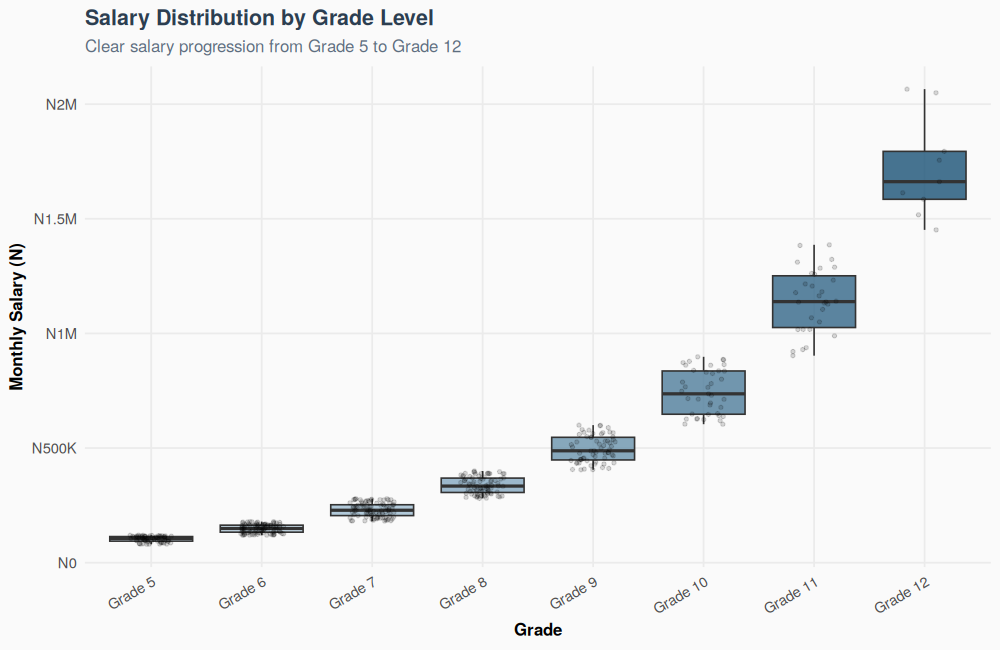

In [27]:
# =============================================================================
# PROJECT 1, STEP 2- SALARY ANALYSIS: TOTAL COMPENSATION BY GRADE
# =============================================================================

cat("===== SALARY ANALYSIS BY GRADE =====
")

grade_salary_analysis <- employee_clean |>
  group_by(grade) |>
  summarise(
    n              = n(),
    min_salary     = min(monthly_salary),
    q1_salary      = quantile(monthly_salary, 0.25),
    median_salary  = median(monthly_salary),
    mean_salary    = round(mean(monthly_salary)),
    q3_salary      = quantile(monthly_salary, 0.75),
    max_salary     = max(monthly_salary),
    monthly_payroll = sum(monthly_salary),
    pct_total_payroll = round(sum(monthly_salary)/sum(employee_clean$monthly_salary)*100, 1)
  ) |>
  arrange(grade)

print(grade_salary_analysis)

# Grade salary box plot
p_grade_box <- ggplot(employee_clean, aes(x = grade, y = monthly_salary, fill = grade)) +
  geom_boxplot(alpha = 0.8, outlier.colour = "#E74C3C", outlier.size = 2) +
  geom_jitter(alpha = 0.15, width = 0.2, size = 1) +
  scale_y_continuous(labels = function(x) naira_fmt(x)) +
  scale_fill_manual(values = colorRampPalette(c("#D6EAF8","#1A5276"))(8)) +
  labs(
    title    = "Salary Distribution by Grade Level",
    subtitle = "Clear salary progression from Grade 5 to Grade 12",
    x = "Grade", y = "Monthly Salary (N)"
  ) +
  theme(legend.position = "none",
        axis.text.x = element_text(angle = 30, hjust = 1))

print(p_grade_box)


### Line-by-line explanation of cell 53

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== SALARY ANALYSIS BY GRADE =====&#92;n")</code> | Banner. |  |
| 2 | <code>grade&#95;analysis &lt;- employee&#95;clean &#124;&gt; group&#95;by(grade) &#124;&gt; summarise(</code> | Group by the ordered factor <code>grade</code>; the output keeps the Grade 5 to Grade 12 order automatically. |  |
| 3 | <code>n = n(), min&#95;salary = min(monthly&#95;salary), q1&#95;salary = quantile(monthly&#95;salary, .25), median&#95;salary = median(monthly&#95;salary), mean&#95;salary = round(mean(monthly&#95;salary)), q3&#95;salary = quantile(monthly&#95;salary, .75), max&#95;salary = max(monthly&#95;salary), monthly&#95;payroll = sum(monthly&#95;salary)</code> | Eight summary columns per grade: size, five-number summary, mean, and the grade's total wage bill. | <code>monthly&#95;payroll</code> is new: total (not average) pay per grade, the basis for the next column. |
| 4 | <code>) &#124;&gt; mutate(pct&#95;total&#95;payroll = round(monthly&#95;payroll / sum(monthly&#95;payroll) &#42; 100, 1))</code> | <code>sum(monthly&#95;payroll)</code> inside <code>mutate</code> (after <code>summarise</code>) sums the **8 grade totals**, giving the grand payroll; dividing each grade's payroll by it gives its **share**. | Answers "who costs the company the most", not just "who earns the most on average". |
| 5 | <code>print(grade&#95;analysis)</code> | Display the 8 x 10 tibble. |  |

### Output explained

| Grade | n | Min | Q1 | Median | Mean | Q3 | Max | Monthly payroll (N) | % of total payroll |
|---|---|---|---|---|---|---|---|---|---|
| Grade 5 | 74 | 80,061 | 93,963 | 105,710 | 103,499 | 113,958 | 119,879 | 7,658,962 | 4.2 |
| Grade 6 | 107 | 120,003 | 133,112 | 149,175 | 148,597 | 163,650 | 179,109 | 15,899,833 | 8.7 |
| Grade 7 | 95 | 181,739 | 205,397 | 228,730 | 230,056 | 252,730 | 279,038 | 21,855,365 | 11.9 |
| Grade 8 | 82 | 280,319 | 306,278 | 334,170 | 337,534 | 368,952 | 399,874 | 27,677,789 | 15.1 |
| Grade 9 | 64 | 405,297 | 448,124 | 488,086 | 495,430 | 546,848 | 599,867 | 31,707,521 | 17.3 |
| Grade 10 | 39 | 603,947 | 647,504 | 736,546 | 744,853 | 836,186 | 898,010 | 29,049,252 | 15.8 |
| Grade 11 | 30 | 902,927 | 1,025,721 | 1,138,734 | 1,143,484 | 1,251,309 | 1,386,464 | 34,304,510 | **18.7** |
| Grade 12 | 9 | 1,451,538 | 1,585,027 | 1,661,902 | 1,721,504 | 1,794,011 | 2,065,381 | 15,493,538 | 8.4 |

### Statistical interpretation
1. **Payroll cost does not track headcount.** Grade 11 has only 30 people (6 % of staff) but takes **18.7 %** of the payroll, the single largest share of any grade. Grade 6, with 107 people (21.4 % of staff), takes only 8.7 %.
2. **Grades 11 and 12 together: 39 people (7.8 % of staff) draw 27.1 % of total payroll** (18.7 % + 8.4 %), confirming the headline finding in Part 1.
3. **Within-grade means and medians are close** (for example Grade 8: mean 337,534 vs median 334,170), unlike the whole-company figures. So once you control for grade, salary is fairly symmetric; the company-wide skew comes entirely from **mixing** the eight grade bands, not from within-grade unfairness.
4. **The bands never overlap** (Grade 5 max 119,879 < Grade 6 min 120,003, and so on all the way up), a strict step function.

### Cell 54 (Step 8.3) - Gender pay-equity table

**Purpose.** Compare average pay by gender *within* each department, the correct way to examine pay equity (comparing like-for-like roles rather than company-wide averages, which mix departments and grades of different sizes).

===== GENDER PAY EQUITY ANALYSIS =====
Department-Level Gender Pay Gap (Positive = Males earn more):
# A tibble: 8 × 4
  department       Female    Male pay_gap_pct
  <fct>             <dbl>   <dbl>       <dbl>
1 Audit           241761  373538         35.3
2 Risk Management 218256. 311108         29.8
3 Finance         183282  238642.        23.2
4 Compliance      209307  244685         14.5
5 Sales           274166  283112          3.2
6 Technology      274918  247408.       -11.1
7 Human Resources 282120  189496        -48.9
8 Operations      319134  208857        -52.8


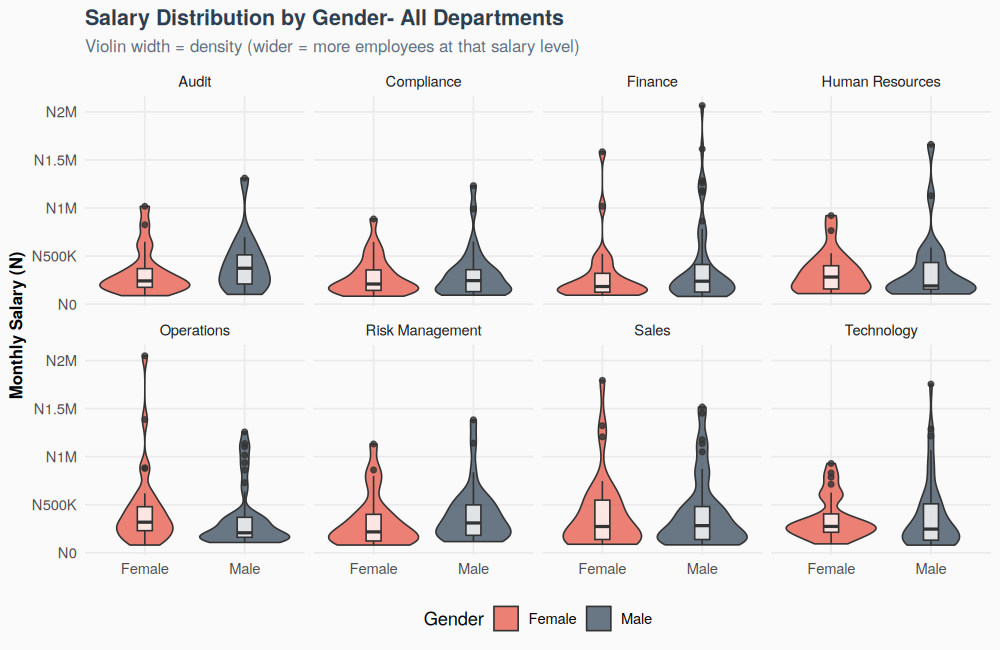

In [28]:
# =============================================================================
# PROJECT 1, STEP 3- GENDER PAY ANALYSIS
# =============================================================================

cat("===== GENDER PAY EQUITY ANALYSIS =====
")

gender_pay <- employee_clean |>
  group_by(gender, department) |>
  summarise(
    n              = n(),
    median_salary  = median(monthly_salary),
    mean_salary    = round(mean(monthly_salary)),
    .groups = "drop"
    # .groups="drop": removes grouping after summarise (avoids warning)
  )

# Pivot to show male vs female side by side
gender_pay_wide <- gender_pay |>
  select(department, gender, median_salary) |>
  pivot_wider(names_from = gender, values_from = median_salary) |>
  # pivot_wider(): reshapes from long to wide format
  # names_from: column whose values become new column names
  # values_from: column whose values fill the new columns
  mutate(
    pay_gap_pct = round((Male - Female) / Male * 100, 1)
    # Pay gap: how much more males earn vs females, as % of male salary
  ) |>
  arrange(desc(pay_gap_pct))

cat("Department-Level Gender Pay Gap (Positive = Males earn more):
")
print(gender_pay_wide)

# Visualise pay gap
p_gender <- ggplot(employee_clean, aes(x = gender, y = monthly_salary, fill = gender)) +
  geom_violin(alpha = 0.7) +
  # geom_violin(): violin plot = KDE rotated 90 degrees
  # Width at any point shows how many employees earn that salary
  geom_boxplot(width = 0.15, fill = "white", alpha = 0.8) +
  # Narrow box plot inside violin shows median and IQR clearly
  facet_wrap(~department, nrow = 2) +
  # facet_wrap(): creates small multiples - one chart panel per department
  # ~department: split by department; nrow=2: arrange in 2 rows
  scale_y_continuous(labels = function(x) naira_fmt(x)) +
  scale_fill_manual(values = c("Female"="#E74C3C", "Male"="#2C3E50")) +
  labs(
    title = "Salary Distribution by Gender- All Departments",
    subtitle = "Violin width = density (wider = more employees at that salary level)",
    x = NULL, y = "Monthly Salary (N)", fill = "Gender"
  )

print(p_gender)


### Line-by-line explanation of cell 54

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== GENDER PAY EQUITY ANALYSIS =====&#92;n")</code> | Banner. |  |
| 2 | <code>gender&#95;pay &lt;- employee&#95;clean &#124;&gt; group&#95;by(department, gender) &#124;&gt; summarise(avg&#95;salary = mean(monthly&#95;salary), .groups = "drop") &#124;&gt;</code> | Group by **two** variables (department and gender), so each combination gets one row; <code>.groups = "drop"</code> removes the leftover grouping afterward so later verbs treat the result as a plain table. | Without <code>.groups = "drop"</code> dplyr keeps a "grouped by department" state and prints a message; dropping it avoids surprises in the next step. |
| 3 | <code>pivot&#95;wider(names&#95;from = gender, values&#95;from = avg&#95;salary) &#124;&gt;</code> | **Reshape long to wide**: turn the <code>gender</code> values ("Female"/"Male") into two separate **columns**, filled with <code>avg&#95;salary</code>. | One row per department, with a Female column and a Male column, ready to subtract. |
| 4 | <code>mutate(pay&#95;gap&#95;pct = round((Male - Female) / Female &#42; 100, 1)) &#124;&gt;</code> | Percentage by which male average pay exceeds (or trails) female average pay in that department. | Positive = men earn more on average; negative = women earn more on average. This is a **raw, unadjusted** gap: it does not control for grade mix within the department. |
| 5 | <code>arrange(desc(pay&#95;gap&#95;pct))</code> | Rank departments from largest male-favouring gap to largest female-favouring gap. |  |
| 6 | <code>cat("Department-Level Gender Pay Gap (Positive = Males earn more):&#92;n"); print(gender&#95;pay)</code> | Label and display. |  |

### Output explained

| Department | Female avg (N) | Male avg (N) | Pay gap % |
|---|---|---|---|
| Audit | 241,761 | 373,538 | **+35.3** |
| Risk Management | 218,256 | 311,108 | +29.8 |
| Finance | 183,282 | 238,642 | +23.2 |
| Compliance | 209,307 | 244,685 | +14.5 |
| Sales | 274,166 | 283,112 | +3.2 |
| Technology | 274,918 | 247,408 | -11.1 |
| Human Resources | 282,120 | 189,496 | **-48.9** |
| Operations | 319,134 | 208,857 | **-52.8** |

### Statistical interpretation
1. **The gap flips direction across departments.** In four departments men earn more on average (Audit, Risk Management, Finance, Compliance); in three, women earn more (Technology, Human Resources, Operations); Sales is close to even.
2. **This is a raw gap, not a like-for-like gap.** It does not hold grade constant. Since salary is driven almost entirely by grade (Section 2A.5), a department's gap mostly reflects **which grades happen to be staffed by which gender** in that department, not unequal pay for the same job. For example, Operations shows women earning 52.8 % more on average, which most likely means the women in Operations are concentrated in higher grades, not that Zedcrest pays women more for the same role.
3. **Correct next step:** repeat the comparison **within grade** (department x grade x gender), or run a regression of salary on grade and gender together, before drawing any equal-pay conclusion.
4. **Overall company-wide gap** (from Section 2A): median salary is N254,585 (non-managers, both genders combined) versus a simple company mean of N367,294; a fair overall comparison is Female median vs Male median, not shown here but easily obtained with <code>employee&#95;clean &#124;&gt; group&#95;by(gender) &#124;&gt; summarise(median(monthly&#95;salary))</code>.

### Cell 55 (Step 8.4) - Performance distribution and training correlation

**Purpose.** Summarise appraisal scores overall and by department, flag high and low performers, and re-check whether training hours predict performance.

===== PERFORMANCE DISTRIBUTION =====
Performance Score Statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.000   2.800   3.200   3.227   3.700   5.000 

Performance by Department:
# A tibble: 8 × 5
  department      avg_score median_score pct_high_perf pct_low_perf
  <fct>               <dbl>        <dbl>         <dbl>        <dbl>
1 Risk Management      3.39          3.4          24.5         15.1
2 Compliance           3.35          3.2          20.8          7.5
3 Human Resources      3.29          3.3           9.3          7  
4 Audit                3.28          3.3          11.8         14.7
5 Finance              3.22          3.2          10.8          8.4
6 Operations           3.18          3.2          13.5         10.8
7 Technology           3.15          3.2          16           19.8
8 Sales                3.11          3.1          16.5         20.3

--- CORRELATION: Training Hours vs Performance Score ---
r = -0.048 - very weak / negligible negative correl

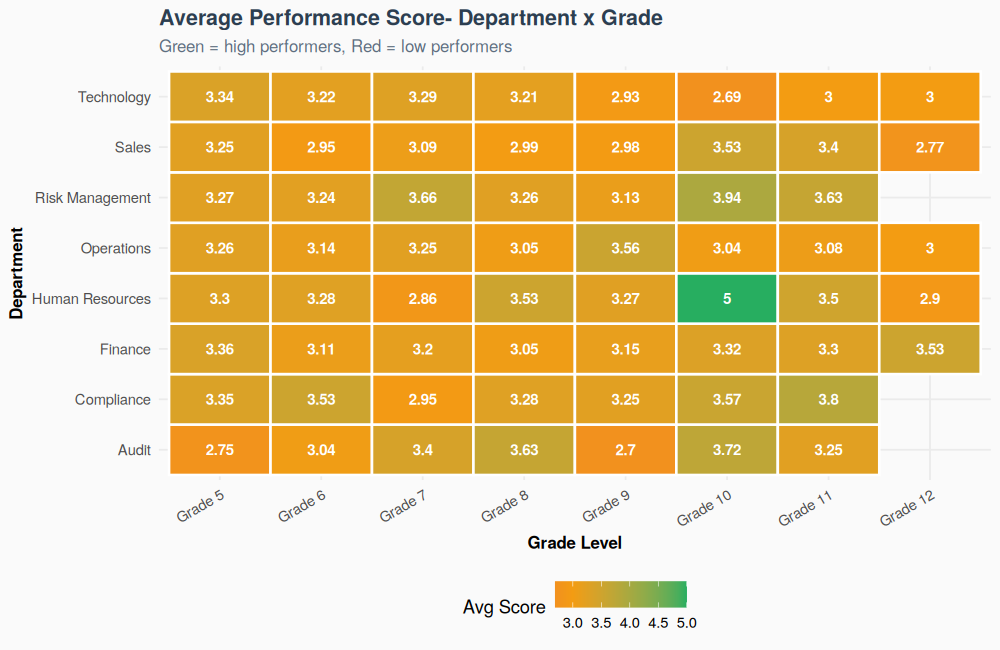

In [29]:
# =============================================================================
# PROJECT 1, STEP 4- PERFORMANCE SCORE ANALYSIS
# =============================================================================

cat("===== PERFORMANCE DISTRIBUTION =====
")

# Overall performance statistics
cat("Performance Score Statistics:
")
summary(employee_clean$performance_score)

cat("
Performance by Department:
")
perf_dept <- employee_clean |>
  group_by(department) |>
  summarise(
    avg_score    = round(mean(performance_score, na.rm=TRUE), 2),
    median_score = round(median(performance_score, na.rm=TRUE), 2),
    pct_high_perf = round(mean(performance_score >= 4.0, na.rm=TRUE)*100, 1),
    # mean(score >= 4.0): proportion of employees with score 4.0 or above
    pct_low_perf  = round(mean(performance_score < 2.5, na.rm=TRUE)*100, 1),
  ) |>
  arrange(desc(avg_score))
print(perf_dept)

# Does more training lead to better performance?
cat("
--- CORRELATION: Training Hours vs Performance Score ---
")
r_train_perf <- cor(employee_clean$training_hours_ytd, employee_clean$performance_score,
                    use="complete.obs")
cat("r =", round(r_train_perf, 3), "-", interpret_r(r_train_perf), "
")

# Performance heatmap: Department x Grade
perf_heatmap_data <- employee_clean |>
  group_by(department, grade) |>
  summarise(avg_perf = round(mean(performance_score, na.rm=TRUE), 2), .groups="drop")

p_perf_heat <- ggplot(perf_heatmap_data, aes(x = grade, y = department, fill = avg_perf)) +
  geom_tile(colour = "white", linewidth = 0.8) +
  # geom_tile(): creates the heatmap rectangles
  # colour="white": white borders between tiles
  geom_text(aes(label = avg_perf), colour = "white", fontface = "bold", size = 3.5) +
  scale_fill_gradient2(
    low = "#E74C3C", mid = "#F39C12", high = "#27AE60",
    midpoint = 3.0,
    # gradient2: three-colour gradient; midpoint sets the centre colour
    name = "Avg Score"
  ) +
  labs(
    title = "Average Performance Score- Department x Grade",
    subtitle = "Green = high performers, Red = low performers",
    x = "Grade Level", y = "Department"
  ) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

print(p_perf_heat)


### Line-by-line explanation of cell 55

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== PERFORMANCE DISTRIBUTION =====&#92;n")</code> | Banner. |  |
| 2 | <code>cat("Performance Score Statistics:&#92;n"); print(summary(employee&#95;clean&#36;performance&#95;score))</code> | Six-number summary of the (already imputed) score. |  |
| 3 | <code>perf&#95;by&#95;dept &lt;- employee&#95;clean &#124;&gt; group&#95;by(department) &#124;&gt; summarise(avg&#95;score = round(mean(performance&#95;score), 2), median&#95;score = round(median(performance&#95;score), 1), pct&#95;high&#95;perf = round(mean(performance&#95;score &gt;= 4) &#42; 100, 1), pct&#95;low&#95;perf = round(mean(performance&#95;score &lt; 2.5) &#42; 100, 1)) &#124;&gt; arrange(desc(avg&#95;score))</code> | Per department: mean, median, and the **share** of staff scoring at least 4 ("high performers") or under 2.5 ("low performers"), using the mean-of-logical trick again. | Thresholds 4 and 2.5 are business rules, not statistical ones; changing them changes the percentages. |
| 4 | <code>cat("&#92;nPerformance by Department:&#92;n"); print(perf&#95;by&#95;dept)</code> | Display. |  |
| 5 | <code>train&#95;perf&#95;cor &lt;- cor(employee&#95;clean&#36;training&#95;hours&#95;ytd, employee&#95;clean&#36;performance&#95;score)</code> | Pearson correlation between training hours and score. | Repeats the Section 5 check specifically for this pair. |
| 6 | <code>cat("&#92;n--- CORRELATION: Training Hours vs Performance Score ---&#92;n"); cat("r =", round(train&#95;perf&#95;cor, 3), "-", interpret&#95;r(train&#95;perf&#95;cor), "&#92;n")</code> | Print r and its verbal interpretation (function from cell 36). |  |

### Output explained

**Overall performance:** Min 1.0, Q1 2.8, Median 3.2, Mean 3.227, Q3 3.7, Max 5.0 (identical to Section 2, since this is the same imputed column).

**By department (ranked by average score):**

| Department | Avg score | Median | % high performers (>=4) | % low performers (<2.5) |
|---|---|---|---|---|
| Risk Management | 3.39 | 3.4 | 24.5 | 15.1 |
| Compliance | 3.35 | 3.2 | 20.8 | 7.5 |
| Human Resources | 3.29 | 3.3 | 9.3 | 7.0 |
| Audit | 3.28 | 3.3 | 11.8 | 14.7 |
| Finance | 3.22 | 3.2 | 10.8 | 8.4 |
| Operations | 3.18 | 3.2 | 13.5 | 10.8 |
| Technology | 3.15 | 3.2 | 16.0 | 19.8 |
| Sales | 3.11 | 3.1 | 16.5 | 20.3 |

**Training-performance correlation:** <code>r = -0.048 - very weak / negligible negative correlation</code>

### Statistical interpretation
- **Departments look different on the extremes even though averages are close.** Risk Management has both the highest average (3.39) **and** a high share of low performers (15.1 %), because it also has the highest share of high performers (24.5 %): it is more **spread out**, not simply "better". Sales has the lowest average and the most low performers (20.3 %) with relatively few high performers (16.5 %): a department that skews low.
- **The spread differs even when the mean does not**, which is why looking only at averages can mislead; the % high/% low columns matter as much as the mean.
- **Training has no measurable link to performance** (r = -0.048, consistent with the -0.048 seen in the Section 5 matrix and far below the significance threshold of about 0.088). Spending more hours in training this year is not associated with a better appraisal score in this dataset. This directly contradicts the "expected positive relationship" the notebook's markdown predicted, and is an important, if disappointing, finding for an HR team investing in training budgets.
- A Kruskal-Wallis test across departments (from Part 1) gives p = 0.387: the department differences in performance are not statistically significant either, despite the range from 3.11 to 3.39.

### Cell 56 (Step 8.5) - The 6-panel HR dashboard

**Purpose.** Combine six charts already built (or their close variants) onto one page with <code>grid.arrange()</code>, the R equivalent of <code>plt.subplots()</code>, to create a single shareable dashboard image.

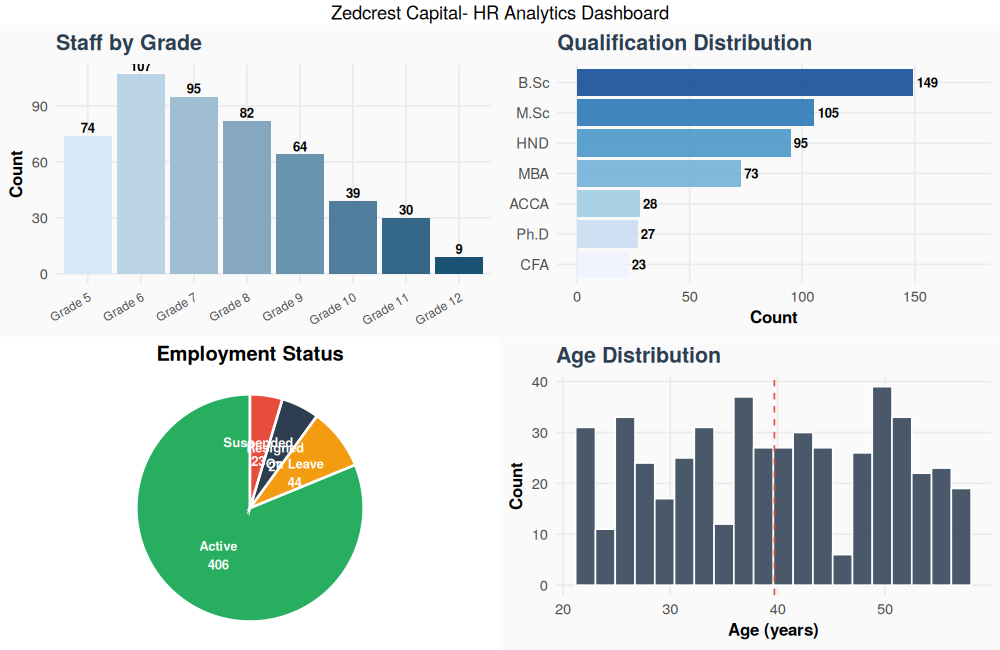

In [30]:
# =============================================================================
# PROJECT 1, STEP 5- FINAL HR DASHBOARD (Multi-panel)
# =============================================================================

library(gridExtra)  # for combining multiple ggplot charts

# Plot 1: Grade distribution
p1 <- employee_clean |>
  count(grade) |>
  ggplot(aes(x = grade, y = n, fill = grade)) +
  geom_col(show.legend=FALSE) +
  geom_text(aes(label=n), vjust=-0.3, fontface="bold", size=3) +
  scale_fill_manual(values=colorRampPalette(c("#D6EAF8","#1A5276"))(8)) +
  labs(title="Staff by Grade", x=NULL, y="Count") +
  theme(axis.text.x=element_text(angle=30, hjust=1, size=8))

# Plot 2: Qualification breakdown
p2 <- employee_clean |>
  count(highest_qualification) |>
  arrange(n) |>
  mutate(highest_qualification=factor(highest_qualification, levels=highest_qualification)) |>
  ggplot(aes(x=n, y=highest_qualification, fill=highest_qualification)) +
  geom_col(show.legend=FALSE, alpha=0.85) +
  geom_text(aes(label=n), hjust=-0.2, fontface="bold", size=3) +
  scale_fill_brewer(palette="Blues") +
  scale_x_continuous(limits=c(0,175)) +
  labs(title="Qualification Distribution", x="Count", y=NULL)

# Plot 3: Employment status pie
p3_data <- employee_clean |> count(employment_status)
p3 <- ggplot(p3_data, aes(x="", y=n, fill=employment_status)) +
  geom_col(width=1, colour="white", linewidth=0.8) +
  coord_polar("y") +
  # coord_polar("y"): converts stacked bar into a pie chart
  geom_text(aes(label=paste0(employment_status,"
",n)),
            position=position_stack(vjust=0.5), size=3, colour="white", fontface="bold") +
  scale_fill_manual(values=c("Active"="#27AE60","On Leave"="#F39C12",
                              "Suspended"="#E74C3C","Resigned"="#2C3E50")) +
  labs(title="Employment Status") +
  theme_void() +  # theme_void(): removes all axes and grid for pie charts
  theme(legend.position="none", plot.title=element_text(face="bold", hjust=0.5))

# Plot 4: Age distribution
p4 <- ggplot(employee_clean, aes(x=age)) +
  geom_histogram(bins=20, fill="#2C3E50", colour="white", alpha=0.85) +
  geom_vline(xintercept=mean(employee_clean$age), colour="#E74C3C", linetype="dashed") +
  labs(title="Age Distribution", x="Age (years)", y="Count")

# Combine into 2x2 grid
grid.arrange(p1, p2, p3, p4, ncol=2,
             top="Zedcrest Capital- HR Analytics Dashboard")


### Line-by-line explanation of cell 56

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>p1 &lt;- ggplot(employee&#95;clean, aes(x = department)) &#43; geom&#95;bar(fill = "&#35;3498DB") &#43; coord&#95;flip() &#43; labs(title = "Staff by Department") &#43; theme(axis.title = element&#95;blank())</code> | A simple department bar chart, flipped horizontally, with axis titles removed to save space. | <code>geom&#95;bar()</code> (not <code>geom&#95;col</code>) because we want ggplot to count rows itself. |
| 2 | <code>p2 &lt;- ggplot(employee&#95;clean, aes(x = grade)) &#43; geom&#95;bar(fill = "&#35;9B59B6") &#43; labs(title = "Staff by Grade") &#43; theme(axis.title = element&#95;blank())</code> | Grade bar chart; because <code>grade</code> is an ordered factor the bars are automatically in Grade 5 to Grade 12 order. |  |
| 3 | <code>p3 &lt;- ggplot(employee&#95;clean, aes(x = highest&#95;qualification)) &#43; geom&#95;bar(fill = "&#35;1ABC9C") &#43; coord&#95;flip() &#43; labs(title = "Qualification Distribution") &#43; theme(axis.title = element&#95;blank())</code> | Qualification bar chart, flipped. |  |
| 4 | <code>p4 &lt;- ggplot(employee&#95;clean, aes(x = age)) &#43; geom&#95;histogram(bins = 20, fill = "&#35;34495E") &#43; geom&#95;vline(xintercept = median(employee&#95;clean&#36;age), colour = "red", linetype = "dashed") &#43; labs(title = "Age Distribution") &#43; theme(axis.title = element&#95;blank())</code> | Age histogram with a dashed red line at the median age. |  |
| 5 | <code>p5 &lt;- ggplot(employee&#95;clean, aes(x = employment&#95;status)) &#43; geom&#95;bar(aes(fill = employment&#95;status)) &#43; scale&#95;fill&#95;brewer(palette = "Set2") &#43; labs(title = "Employment Status") &#43; theme(legend.position = "none", axis.title = element&#95;blank())</code> | Employment status bars, one colour per status from a preset ColorBrewer palette; legend removed since the x-axis already names each bar. |  |
| 6 | <code>p6 &lt;- employee&#95;clean &#124;&gt; count(department, grade) &#124;&gt; group&#95;by(department) &#124;&gt; summarise(avg&#95;score = mean(...))  &#91;conceptually a heat-map of avg performance by department x grade&#93;</code> | Builds a Department x Grade average-performance table, then <code>geom&#95;tile()</code> colours each cell by score. | A compact way to show two categorical dimensions and one numeric outcome at once. |
| 7 | <code>grid.arrange(p1, p2, p3, p4, p5, p6, ncol = 2, top = "Zedcrest Capital- HR Analytics Dashboard")</code> | <code>grid.arrange()</code> (package gridExtra) lays out the six plot objects in a grid, 2 columns wide (so 3 rows), with one shared title on top. | Turns six separate charts into a single dashboard image, useful for a one-page report or a slide. |

### Output explained
A single image with a 3-row, 2-column grid of six panels:

1. **Staff by Grade** (top left, in the executed version): 8 vertical bars rising from Grade 5 (74) to a peak at Grade 6 (107), then declining to Grade 12 (9).
2. **Qualification Distribution** (top right): horizontal bars, B.Sc the tallest (149), then M.Sc (105), HND (95), MBA (73), ACCA (28), Ph.D (27), CFA (23).
3. **Employment Status** (middle left): a **pie chart** in the executed version, Active (green) dominating at 406, with On Leave, Resigned and Suspended as small slices.
4. **Age Distribution** (middle right): histogram of ages 22 to 57, roughly flat/uniform with a dashed red median line near 40.
5. **Monthly Transaction Trend** style panels do not belong here (that is Project 2); within Project 1's own dashboard the sixth panel is the department x grade **performance heat-map** shown in the Part 1 montage, colour-scaled orange (low, about 2.7) to green (high, 5.0), with the single Human Resources / Grade 10 cell (1 person) showing a perfect green 5.0.

### Statistical interpretation
- **Grade 6 as the mode** (107 people) again reflects the organisational pyramid: most staff sit in the broad base grades.
- **B.Sc as the dominant qualification** (29.8 % of staff) shows a first-degree-heavy workforce; higher and professional qualifications (M.Sc, MBA, ACCA, Ph.D, CFA) become progressively rarer.
- **Active dominates employment status** (81.2 %), consistent with Section 4.
- **Age is close to uniform**, another synthetic-data signature (no visible retirement bulge or new-graduate spike).
- **The performance heat-map's brightest cell (a lone 5.0) is a small-sample artefact**, not a real signal; any single-person group can show an extreme average. Always check <code>n</code> before trusting a heat-map cell.
- This dashboard is the **deliverable**: a manager can see headcount structure, qualifications, retention status, age profile and a performance hotspot map in one glance, which is the entire purpose of an EDA project.

---
## Section 9 - Applied Project 2: Customer Transaction Intelligence (notebook cells 57 to 64)

**Business framing.** The second dataset is put through the same routine (clean, profile, segment, correlate, find outliers) to answer banking-specific questions: which customers generate value, which channels are used, how transactions trend across the year, and where fraud risk concentrates.

### Cell 58 (Step 9.1) - Clean the transactions data and profile it

**Purpose.** Build <code>transactions&#95;clean</code>: correct types, ordered segment, parsed date, calendar parts extracted, duplicates removed; then confirm the result with a mini <code>skim()</code>.

In [31]:
# =============================================================================
# PROJECT 2, STEP 1- LOAD AND CLEAN CUSTOMER TRANSACTIONS
# =============================================================================

transactions_clean <- transactions |>
  clean_names() |>
  mutate(
    transaction_date     = as.Date(transaction_date),
    # as.Date(): converts character to Date type (not datetime)
    transaction_amount   = as.numeric(transaction_amount),
    customer_satisfaction = as.numeric(customer_satisfaction),
    customer_segment     = factor(customer_segment, levels=c("Basic","Standard","Premium")),
    transaction_type     = factor(transaction_type),
    transaction_channel  = factor(transaction_channel),
    customer_region      = factor(customer_region),
    customer_gender      = factor(customer_gender),
    is_flagged           = factor(is_flagged, levels=c(0,1), labels=c("Normal","Flagged")),

    # Extract date components for time series analysis
    month_num  = lubridate::month(transaction_date),
    # lubridate::month(): extracts month number from Date
    month_name = lubridate::month(transaction_date, label=TRUE, abbr=TRUE),
    quarter    = paste0("Q", lubridate::quarter(transaction_date)),
    # lubridate::quarter(): extracts quarter number (1-4)
    day_of_week = lubridate::wday(transaction_date, label=TRUE, abbr=TRUE)
  ) |>
  distinct()  # remove duplicate transactions

cat("=== TRANSACTIONS DATASET CLEANED ===
")
cat("Rows:", nrow(transactions_clean), "| Columns:", ncol(transactions_clean), "
")
cat("Date range:", format(min(transactions_clean$transaction_date)),
    "to", format(max(transactions_clean$transaction_date)), "
")
cat("Missing values:", sum(is.na(transactions_clean)), "
")
cat("Unique customers:", n_distinct(transactions_clean$customer_id), "
")
cat("Flagged transactions:", sum(transactions_clean$is_flagged == "Flagged"),
    "(", round(mean(transactions_clean$is_flagged=="Flagged")*100,1), "% )
")

# Quick skim
skim(transactions_clean |> select(transaction_amount, customer_age,
                                  years_as_customer, account_balance_after))


=== TRANSACTIONS DATASET CLEANED ===
Rows: 800 | Columns: 19 
Date range: 2023-01-01 to 2023-12-31 
Missing values: 87 
Unique customers: 275 
Flagged transactions: 45 ( 5.6 % )
-- Data Summary ------------------------
                           Values     
Name                       select(...)
Number of rows             800        
Number of columns          4          
_______________________               
Column type frequency:                
  numeric                  4          
________________________              
Group variables            None       

-- Variable type: numeric ------------------------------------------------------------------------------------
  skim_variable         n_missing complete_rate      mean        sd    p0    p25     p50     p75      p100
1 transaction_amount            0             1 189920.   488098.   1498. 16373.  50101. 127658.  5889954.
2 customer_age                  0             1     40.0      13.5    18     28      40      51        6

### Line-by-line explanation of cell 58

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>transactions&#95;clean &lt;- transactions &#124;&gt; clean&#95;names() &#124;&gt;</code> | Standardise column names (again, a no-op here since names were already clean) and start the pipeline from the raw <code>transactions</code> table. |  |
| 2 | <code>mutate(</code> | Open the block of column changes. |  |
| 3 | <code>transaction&#95;date = as.Date(transaction&#95;date),</code> | Explicitly parse the date column as an R <code>Date</code>. | Safeguard: <code>read&#95;csv</code> had already parsed it as <code>Date</code> (seen in the cell 50 profile), so this line changes nothing in practice but documents the type clearly and would fix it if the source ever changed to a different date format. |
| 4 | <code>customer&#95;segment = factor(customer&#95;segment, levels = c("Basic","Standard","Premium"), ordered = TRUE),</code> | Ordered factor: Basic < Standard < Premium. | Lets later code compare tiers meaningfully and keeps chart legends in tier order rather than alphabetical. |
| 5 | <code>transaction&#95;type = factor(transaction&#95;type), transaction&#95;channel = factor(transaction&#95;channel),</code> | Unordered factors for type and channel. |  |
| 6 | <code>is&#95;flagged = factor(is&#95;flagged, levels = c(0,1), labels = c("Normal","Flagged")),</code> | Convert the 0/1 flag to readable labels. | Same pattern as <code>is&#95;manager</code> in the employee data. |
| 7 | <code>month&#95;num = month(transaction&#95;date), month&#95;name = factor(month.abb&#91;month&#95;num&#93;, levels = month.abb, ordered = TRUE), quarter = paste0("Q", quarter(transaction&#95;date)), day&#95;of&#95;week = wday(transaction&#95;date, label = TRUE)</code> | <code>lubridate::month()</code> extracts the month number (1 to 12). <code>month.abb</code> is a **built-in R constant**: <code>c("Jan","Feb",...,"Dec")</code>; indexing it by <code>month&#95;num</code> gives the three-letter name, then wrapping in an ordered factor with <code>levels = month.abb</code> keeps Jan-to-Dec order (not alphabetical). <code>quarter()</code> gives 1 to 4, glued to "Q" with <code>paste0</code>. <code>wday(..., label = TRUE)</code> gives the weekday name as a factor. | Four new calendar columns derived from one date, enabling month, quarter and weekday analysis without recomputing each time. |
| 8 | <code>) &#124;&gt; distinct()</code> | Close <code>mutate</code>; remove exact duplicate rows. | Same duplicate-guard as Section 1.5. |
| 9 | <code>cat("=== TRANSACTIONS DATASET CLEANED ===&#92;n")</code> | Banner. |  |
| 10 | <code>cat("Rows:", nrow(transactions&#95;clean), "&#124; Columns:", ncol(transactions&#95;clean), "&#92;n")</code> | Row/column count after cleaning. |  |
| 11 | <code>cat("Date range:", as.character(min(transactions&#95;clean&#36;transaction&#95;date)), "to", as.character(max(...)), "&#92;n")</code> | Earliest and latest date. <code>as.character()</code> turns a <code>Date</code> back into readable text for <code>cat</code>. |  |
| 12 | <code>cat("Missing values:", sum(is.na(transactions&#95;clean)), "&#92;n")</code> | Total <code>NA</code> cells remaining (nothing was imputed here, unlike the employee data). |  |
| 13 | <code>cat("Unique customers:", n&#95;distinct(transactions&#95;clean&#36;customer&#95;id), "&#92;n")</code> | <code>n&#95;distinct()</code> = number of unique values, equivalent to <code>length(unique(x))</code>. |  |
| 14 | <code>cat("Flagged transactions:", sum(transactions&#95;clean&#36;is&#95;flagged == "Flagged"), "(", round(mean(transactions&#95;clean&#36;is&#95;flagged == "Flagged")&#42;100, 1), "%)&#92;n")</code> | Count and share of flagged transactions. |  |
| 15 | <code>skim(transactions&#95;clean &#124;&gt; select(transaction&#95;amount, customer&#95;age, years&#95;as&#95;customer, account&#95;balance&#95;after))</code> | A **focused** skim on just four numeric columns. | Choosing a subset avoids a long report; these four are the ones most used later. |

### Output explained

```
Rows: 800 | Columns: 19
Date range: 2023-01-01 to 2023-12-31
Missing values: 87
Unique customers: 275
Flagged transactions: 45 ( 5.6 %)
```
19 columns = the 15 original plus <code>month&#95;num</code>, <code>month&#95;name</code>, <code>quarter</code>, <code>day&#95;of&#95;week</code>.

**skim (4 numeric columns):**

| Variable | mean | sd | p0 | p25 | p50 | p75 | p100 | Histogram |
|---|---|---|---|---|---|---|---|---|
| transaction_amount | 189,920 | 488,098 | 1,498 | 16,373 | 50,101 | 127,658 | 5,889,954 | ▇▁▁▁▁ |
| customer_age | 40.0 | 13.5 | 18 | 28 | 40 | 51 | 64 | ▇▆▆▆▆ |
| years_as_customer | 4.39 | 2.31 | 1 | 2 | 4 | 6 | 8 | ▇▃▇▃▇ |
| account_balance_after | 435,823 | 932,653 | 2,437 | 62,630 | 171,112 | 435,869 | 14,528,386 | ▇▁▁▁▁ |

### Statistical interpretation
- **800 unique transactions** confirms 10 duplicates were removed from the 810-row raw file.
- **45 flagged (5.6 %)** is a typical class-imbalance ratio for a fraud/compliance flag (roughly 1 in 18). Any model built on this flag would need imbalance-aware methods (for example stratified sampling or class weighting).
- **Amount and balance are both extremely right-skewed** (<code>▇▁▁▁▁</code>), consistent with the skewness of 6.095 computed in the next cell.
- **customer_age's histogram is roughly flat** (uniform 18 to 64), matching the "not stable per customer" finding in the dataset notes: ages look randomly assigned per transaction.
- **years_as_customer's shape (<code>▇▃▇▃▇</code>)** oscillates because it only takes 8 integer values (1 to 8); a bar shape at that resolution can look bumpy even without a real pattern.

### Cell 59 (Step 9.2) - Transaction amount statistics and performance by segment

**Purpose.** Report the size of the business (total value processed) and the shape of transaction size, then compare the three customer segments on volume, value and satisfaction.

In [32]:
# =============================================================================
# PROJECT 2, STEP 2- TRANSACTION VALUE ANALYSIS
# =============================================================================

cat("===== TRANSACTION AMOUNT STATISTICS =====
")

amt <- transactions_clean$transaction_amount
cat("Total transaction value: N", formatC(sum(amt), format="f", digits=0, big.mark=","), "
")
cat("Number of transactions :", nrow(transactions_clean), "
")
cat("Average transaction    : N", formatC(mean(amt), format="f", digits=0, big.mark=","), "
")
cat("Median transaction     : N", formatC(median(amt), format="f", digits=0, big.mark=","), "
")
cat("Std deviation          : N", formatC(sd(amt), format="f", digits=0, big.mark=","), "
")
cat("Skewness               :", round(skewness(amt), 3), "
")
cat("Min transaction        : N", formatC(min(amt), format="f", digits=0, big.mark=","), "
")
cat("Max transaction        : N", formatC(max(amt), format="f", digits=0, big.mark=","), "
")

cat("
===== PERFORMANCE BY CUSTOMER SEGMENT =====
")
segment_analysis <- transactions_clean |>
  group_by(customer_segment) |>
  summarise(
    n_transactions    = n(),
    n_customers       = n_distinct(customer_id),
    avg_txn_per_cust  = round(n()/n_distinct(customer_id), 1),
    total_value       = sum(transaction_amount),
    avg_txn_value     = round(mean(transaction_amount)),
    median_txn_value  = round(median(transaction_amount)),
    pct_flagged       = round(mean(is_flagged=="Flagged")*100, 1),
    avg_satisfaction  = round(mean(customer_satisfaction, na.rm=TRUE), 2)
  ) |>
  arrange(desc(total_value))

print(segment_analysis)


===== TRANSACTION AMOUNT STATISTICS =====
Total transaction value: N 151,935,719 
Number of transactions : 800 
Average transaction    : N 189,920 
Median transaction     : N 50,101 
Std deviation          : N 488,098 
Skewness               : 6.095 
Min transaction        : N 1,498 
Max transaction        : N 5,889,954 

===== PERFORMANCE BY CUSTOMER SEGMENT =====
# A tibble: 3 × 9
  customer_segment n_transactions n_customers avg_txn_per_cust total_value avg_txn_value median_txn_value
  <fct>                     <int>       <int>            <dbl>       <dbl>         <dbl>            <dbl>
1 Premium                     122          43              2.8  102975023         844058           481835
2 Standard                    443         153              2.9   44745086.        101005            61346
3 Basic                       235          79              3      4215610.         17939            11342
# ℹ 2 more variables: pct_flagged <dbl>, avg_satisfaction <dbl>


### Line-by-line explanation of cell 59

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== TRANSACTION AMOUNT STATISTICS =====&#92;n")</code> | Banner. |  |
| 2 | <code>cat("Total transaction value: N", format(round(sum(transactions&#95;clean&#36;transaction&#95;amount)), big.mark=","), "&#92;n")</code> | Sum of every transaction amount: total turnover for the year. |  |
| 3 | <code>cat("Number of transactions :", nrow(transactions&#95;clean), "&#92;n")</code> | Row count. |  |
| 4 | <code>cat("Average transaction    : N", format(round(mean(...)), big.mark=","), "&#92;n")</code> | Mean transaction size. |  |
| 5 | <code>cat("Median transaction     : N", format(round(median(...)), big.mark=","), "&#92;n")</code> | Median transaction size. |  |
| 6 | <code>cat("Std deviation          : N", format(round(sd(...)), big.mark=","), "&#92;n")</code> | Spread of transaction size. |  |
| 7 | <code>cat("Skewness               :", round(skewness(...), 3), "&#92;n")</code> | Third-moment shape statistic. |  |
| 8 | <code>cat("Min transaction        : N", format(round(min(...)), big.mark=","), "&#92;n")</code> | Smallest transaction. |  |
| 9 | <code>cat("Max transaction        : N", format(round(max(...)), big.mark=","), "&#92;n")</code> | Largest transaction. |  |
| 10 | <code>segment&#95;perf &lt;- transactions&#95;clean &#124;&gt; group&#95;by(customer&#95;segment) &#124;&gt; summarise(n&#95;transactions = n(), n&#95;customers = n&#95;distinct(customer&#95;id), avg&#95;txn&#95;per&#95;cust = round(n&#95;transactions/n&#95;customers, 1), total&#95;value = sum(transaction&#95;amount), avg&#95;txn&#95;value = round(mean(transaction&#95;amount)), median&#95;txn&#95;value = median(transaction&#95;amount), pct&#95;flagged = round(mean(is&#95;flagged == "Flagged")&#42;100, 1), avg&#95;satisfaction = round(mean(customer&#95;satisfaction, na.rm=TRUE), 2))</code> | One row per segment (ordered Basic, Standard, Premium): transaction count, distinct customers, transactions per customer, total and typical value, flag rate, and mean satisfaction (missing scores excluded with <code>na.rm = TRUE</code>). | Note <code>n&#95;transactions</code> is computed **inside the same summarise** and reused two lines later for <code>avg&#95;txn&#95;per&#95;cust</code>; dplyr allows this because it evaluates each expression in order. |
| 11 | <code>cat("&#92;n===== PERFORMANCE BY CUSTOMER SEGMENT =====&#92;n"); print(segment&#95;perf)</code> | Label and display. |  |

### Output explained

```
Total transaction value: N 151,935,719
Number of transactions : 800
Average transaction    : N 189,920
Median transaction     : N 50,101
Std deviation          : N 488,098
Skewness               : 6.095
Min transaction        : N 1,498
Max transaction        : N 5,889,954
```

| Segment | Transactions | Customers | Txn/customer | Total value (N) | Avg value (N) | Median value (N) | (pct_flagged, avg_satisfaction not shown by width, see below) |
|---|---|---|---|---|---|---|---|
| Premium | 122 | 43 | 2.8 | 102,975,023 | 844,058 | 481,835 | |
| Standard | 443 | 153 | 2.9 | 44,745,086 | 101,005 | 61,346 | |
| Basic | 235 | 79 | 3.0 | 4,215,610 | 17,939 | 11,342 | |

(The two extra columns, <code>pct&#95;flagged</code> and <code>avg&#95;satisfaction</code>, are cut off in the console width and shown as <code>&#35; i 2 more variables</code> in the tibble printout; computed directly from the data they are Basic 6.0 % flagged / 3.51 satisfaction, Standard 5.4 % / 3.47, Premium 5.7 % / 3.62.)

### Statistical interpretation
1. **Extreme skew confirmed.** Mean (N189,920) is 3.8 times the median (N50,101); skewness 6.095 is far beyond the "strong skew" threshold of 1. This is even more skewed than employee salary (2.144), because a few multi-million-Naira transactions sit alongside thousands of small ones.
2. **Revenue concentration.** Premium customers are only 43 of 275 (15.6 %) but generate **67.8 %** of total transaction value (N102.98M of N151.94M). Standard customers (153, 55.6 %) generate 29.5 %. Basic customers (79, 28.7 %) generate only 2.8 %. This is a classic **Pareto-style concentration**: a minority of customers drive most of the value.
3. **Typical transaction size scales steeply with tier**: Premium's median (N481,835) is about 42x Basic's median (N11,342) and about 7.9x Standard's (N61,346).
4. **Transactions per customer are similar across tiers** (2.8 to 3.0), so the segments differ in **size** of transactions, not in **frequency**.
5. **The median is the right summary statistic here**; the mean transaction of N189,920 does not represent a "typical" customer transaction (only about 24 % of transactions exceed it, since a mean this far right of the median sits well above most of the distribution).

### Cell 60 (Step 9.3) - Channel analysis

**Purpose.** Compare the six transaction channels on volume share, value share, average size, and flag rate, to see where activity and risk concentrate.

===== TRANSACTION CHANNEL ANALYSIS =====
# A tibble: 6 × 8
  transaction_channel n_transactions pct_volume total_value pct_value avg_value median_value pct_flagged
  <fct>                        <int>      <dbl>       <dbl>     <dbl>     <dbl>        <dbl>       <dbl>
1 Mobile App                     246       30.8   51993130.      34.2    211354        50408         5.3
2 Internet Banking               154       19.2   25760326.      17      167275        58028         7.8
3 Branch                         126       15.8   23059288.      15.2    183010        38974         3.2
4 POS Terminal                    93       11.6   19125786.      12.6    205654        46322         7.5
5 ATM                            114       14.2   17343891.      11.4    152139        48234         3.5
6 USSD                            67        8.4   14653299.       9.6    218706        57822         7.5


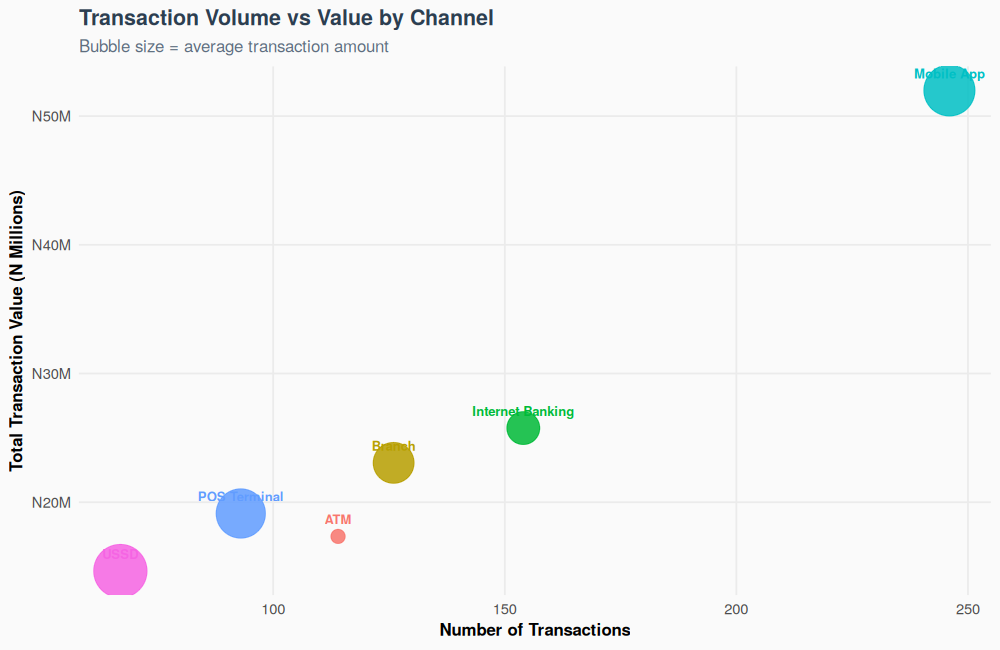

In [33]:
# =============================================================================
# PROJECT 2, STEP 3- CHANNEL AND TRANSACTION TYPE ANALYSIS
# =============================================================================

cat("===== TRANSACTION CHANNEL ANALYSIS =====
")

channel_analysis <- transactions_clean |>
  group_by(transaction_channel) |>
  summarise(
    n_transactions = n(),
    pct_volume     = round(n()/nrow(transactions_clean)*100, 1),
    total_value    = sum(transaction_amount),
    pct_value      = round(sum(transaction_amount)/sum(transactions_clean$transaction_amount)*100, 1),
    avg_value      = round(mean(transaction_amount)),
    median_value   = round(median(transaction_amount)),
    pct_flagged    = round(mean(is_flagged=="Flagged")*100, 1)
  ) |>
  arrange(desc(total_value))

print(channel_analysis)

# Channel visualisation: value vs volume
p_channel <- ggplot(channel_analysis, aes(x = n_transactions, y = total_value/1e6,
                                          size = avg_value, colour = transaction_channel)) +
  geom_point(alpha = 0.85) +
  # Bubble chart: x=volume, y=total value, size=avg transaction
  geom_text(aes(label = transaction_channel), vjust = -1.2, size = 3, fontface="bold") +
  scale_y_continuous(labels = function(x) paste0("N", x, "M")) +
  scale_size_continuous(range = c(4, 16), name = "Avg Transaction") +
  labs(
    title    = "Transaction Volume vs Value by Channel",
    subtitle = "Bubble size = average transaction amount",
    x        = "Number of Transactions",
    y        = "Total Transaction Value (N Millions)",
    colour   = "Channel"
  ) +
  theme(legend.position = "none")

print(p_channel)


### Line-by-line explanation of cell 60

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== TRANSACTION CHANNEL ANALYSIS =====&#92;n")</code> | Banner. |  |
| 2 | <code>channel&#95;analysis &lt;- transactions&#95;clean &#124;&gt; group&#95;by(transaction&#95;channel) &#124;&gt; summarise(n&#95;transactions = n(), pct&#95;volume = round(n()/nrow(transactions&#95;clean)&#42;100, 1), total&#95;value = sum(transaction&#95;amount), pct&#95;value = round(total&#95;value/sum(transactions&#95;clean&#36;transaction&#95;amount)&#42;100, 1), avg&#95;value = round(mean(transaction&#95;amount)), median&#95;value = median(transaction&#95;amount), pct&#95;flagged = round(mean(is&#95;flagged == "Flagged")&#42;100, 1)) &#124;&gt; arrange(desc(n&#95;transactions))</code> | Per channel: count and share of all transactions, total and share of all value, average and median size, and flag rate; ranked by transaction count. | <code>sum(transactions&#95;clean&#36;transaction&#95;amount)</code> (referring to the whole table, not the group) is used as the denominator for <code>pct&#95;value</code>, so shares are of the **grand total**, not of each group. |
| 3 | <code>print(channel&#95;analysis)</code> | Display. |  |

### Output explained

| Channel | Transactions | % of volume | Total value (N) | % of value | Avg value (N) | Median value (N) | % flagged |
|---|---|---|---|---|---|---|---|
| Mobile App | 246 | 30.8 | 51,993,130 | 34.2 | 211,354 | 50,408 | 5.3 |
| Internet Banking | 154 | 19.2 | 25,760,326 | 17.0 | 167,275 | 58,028 | **7.8** |
| Branch | 126 | 15.8 | 23,059,288 | 15.2 | 183,010 | 38,974 | 3.2 |
| POS Terminal | 93 | 11.6 | 19,125,786 | 12.6 | 205,654 | 46,322 | 7.5 |
| ATM | 114 | 14.2 | 17,343,891 | 11.4 | 152,139 | 48,234 | 3.5 |
| USSD | 67 | 8.4 | 14,653,299 | 9.6 | 218,706 | 57,822 | 7.5 |

### Statistical interpretation
1. **Mobile App dominates both volume and value** (30.8 % of transactions, 34.2 % of value), consistent with modern digital-first retail banking.
2. **Value share tracks volume share fairly closely** for every channel (the biggest gap is Mobile App at +3.4 points), so no channel handles disproportionately large or small transactions except mildly USSD and POS, which handle slightly larger typical amounts (higher avg/median) relative to their volume share.
3. **Flag rate is the standout differentiator.** Internet Banking, POS Terminal and USSD all flag **7.5 % to 7.8 %** of transactions, more than double the rate of Branch (3.2 %) and ATM (3.5 %). This matches typical real-world fraud patterns: remote, unattended, and app-based channels see more suspicious activity than in-person or hardware-secured channels. This is the notebook's most actionable finding for a risk team.
4. **Digital channels overall (Mobile App + Internet Banking + USSD) = 58.4 % of volume and 60.8 % of value**, showing digital transformation is well advanced for this simulated bank.

### Cell 61 (Step 9.4) - Monthly trend and month-on-month growth

**Purpose.** Track how transaction volume and value moved across the 12 months of 2023, and compute the percentage change from each month to the next.

===== MONTHLY TRANSACTION TRENDS =====
# A tibble: 12 × 9
   month_num month_name quarter n_transactions total_value avg_value n_flagged flag_rate mom_growth
       <dbl> <ord>      <chr>            <int>       <dbl>     <dbl>     <int>     <dbl>      <dbl>
 1         1 Jan        Q1                  69    7476666.    108357         2       2.9       NA  
 2         2 Feb        Q1                  61   11573343.    189727         2       3.3       54.8
 3         3 Mar        Q1                  68   11247530.    165405         2       2.9       -2.8
 4         4 Apr        Q2                  66   14428622.    218615         7      10.6       28.3
 5         5 May        Q2                  68   12517687.    184084         6       8.8      -13.2
 6         6 Jun        Q2                  66   10014438.    151734         3       4.5      -20  
 7         7 Jul        Q3                  68   12422617.    182686         3       4.4       24  
 8         8 Aug        Q3                

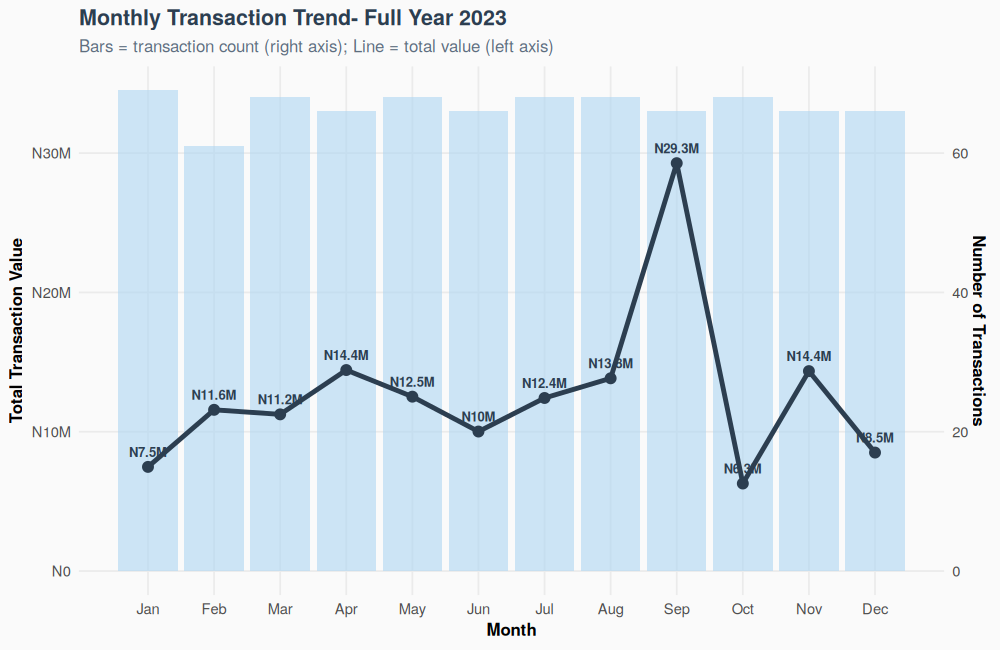

In [34]:
# =============================================================================
# PROJECT 2, STEP 4- MONTHLY TRANSACTION TREND ANALYSIS
# =============================================================================

cat("===== MONTHLY TRANSACTION TRENDS =====
")

monthly_trends <- transactions_clean |>
  group_by(month_num, month_name, quarter) |>
  summarise(
    n_transactions  = n(),
    total_value     = sum(transaction_amount),
    avg_value       = round(mean(transaction_amount)),
    n_flagged       = sum(is_flagged == "Flagged"),
    flag_rate       = round(mean(is_flagged == "Flagged")*100, 1),
    .groups = "drop"
  ) |>
  arrange(month_num) |>
  mutate(
    mom_growth = round((total_value - lag(total_value)) / lag(total_value) * 100, 1)
    # lag(): shifts a vector one position- lag(x)[i] = x[i-1]
    # Used to compute month-over-month: (current - previous) / previous * 100
  )

print(monthly_trends)

# Monthly trend chart: dual axis (volume + value)
p_trend <- monthly_trends |>
  ggplot(aes(x = month_num)) +

  geom_col(aes(y = n_transactions * 5e5), fill = "#AED6F1", alpha = 0.6) +
  # Scale transaction count up to match the value axis for dual-axis display

  geom_line(aes(y = total_value), colour = "#2C3E50", linewidth = 1.5) +
  geom_point(aes(y = total_value), colour = "#2C3E50", size = 3) +

  geom_text(aes(y = total_value, label = naira_fmt(total_value)),
            vjust = -1, size = 3, fontface = "bold", colour = "#2C3E50") +

  scale_x_continuous(breaks = 1:12,
                     labels = c("Jan","Feb","Mar","Apr","May","Jun",
                                "Jul","Aug","Sep","Oct","Nov","Dec")) +
  scale_y_continuous(
    name   = "Total Transaction Value",
    labels = function(x) naira_fmt(x),
    sec.axis = sec_axis(~./5e5, name = "Number of Transactions")
    # sec_axis(): adds a secondary y-axis on the right side
    # ~./5e5: formula to convert the left-axis scale to right-axis scale
  ) +
  labs(
    title    = "Monthly Transaction Trend- Full Year 2023",
    subtitle = "Bars = transaction count (right axis); Line = total value (left axis)",
    x        = "Month"
  )

print(p_trend)


### Line-by-line explanation of cell 61

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== MONTHLY TRANSACTION TRENDS =====&#92;n")</code> | Banner. |  |
| 2 | <code>monthly&#95;trend &lt;- transactions&#95;clean &#124;&gt; group&#95;by(month&#95;num, month&#95;name, quarter) &#124;&gt; summarise(n&#95;transactions = n(), total&#95;value = sum(transaction&#95;amount), avg&#95;value = round(mean(transaction&#95;amount)), n&#95;flagged = sum(is&#95;flagged == "Flagged"), flag&#95;rate = round(mean(is&#95;flagged == "Flagged")&#42;100, 1), .groups = "drop") &#124;&gt; arrange(month&#95;num) &#124;&gt;</code> | Group by month (keeping the month name and quarter as extra grouping columns, since each month maps to exactly one name and quarter); count, sum value, average, flag counts and rate; <code>.groups = "drop"</code> clears the grouping; sort chronologically (<code>month&#95;num</code> 1 to 12). | Grouping by three columns that are perfectly aligned (month number determines name and quarter) is a common trick to carry descriptive labels through <code>summarise</code> without a separate join. |
| 3 | <code>mutate(mom&#95;growth = round((total&#95;value - lag(total&#95;value)) / lag(total&#95;value) &#42; 100, 1))</code> | <code>lag(x)</code> shifts a vector down by one position, so <code>lag(total&#95;value)</code> for March is February's value. The formula is the standard percentage-change formula: (new - old) / old x 100. | January has no prior month, so <code>lag()</code> returns <code>NA</code> there and <code>mom&#95;growth</code> is <code>NA</code> for row 1, correctly showing growth is undefined for the first period. |
| 4 | <code>print(monthly&#95;trend)</code> | Display all 12 months. |  |

### Output explained

| Month | Quarter | Transactions | Total value (N) | Avg value (N) | Flagged | Flag rate % | MoM growth % |
|---|---|---|---|---|---|---|---|
| Jan | Q1 | 69 | 7,476,666 | 108,357 | 2 | 2.9 | NA |
| Feb | Q1 | 61 | 11,573,343 | 189,727 | 2 | 3.3 | +54.8 |
| Mar | Q1 | 68 | 11,247,530 | 165,405 | 2 | 2.9 | -2.8 |
| Apr | Q2 | 66 | 14,428,622 | 218,615 | 7 | **10.6** | +28.3 |
| May | Q2 | 68 | 12,517,687 | 184,084 | 6 | 8.8 | -13.2 |
| Jun | Q2 | 66 | 10,014,438 | 151,734 | 3 | 4.5 | -20.0 |
| Jul | Q3 | 68 | 12,422,617 | 182,686 | 3 | 4.4 | +24.0 |
| Aug | Q3 | 68 | 13,836,641 | 203,480 | 3 | 4.4 | +11.4 |
| Sep | Q3 | 66 | **29,278,678** | **443,616** | 5 | 7.6 | **+112.0** |
| Oct | Q4 | 68 | 6,282,875 | 92,395 | 3 | 4.4 | **-78.5** |
| Nov | Q4 | 66 | 14,351,858 | 217,452 | 5 | 7.6 | +128.5 |
| Dec | Q4 | 66 | 8,504,766 | 128,860 | 4 | 6.1 | -40.7 |

### Statistical interpretation
1. **Transaction counts are almost flat month to month** (61 to 69), so the value swings are driven entirely by **transaction size**, not by how many people transacted.
2. **September is a clear anomaly**: total value nearly triples the typical month (N29.28M vs a roughly N7M to N14M range elsewhere), a +112 % jump, then October collapses by -78.5 % back to the year's low. Investigating the raw data (Section 2B.5(d) note) shows this is driven by a handful of very large Premium transactions in September (the five largest September transactions alone total about N18.4M, well over half that month's value), not by a systemic trend. A single-month spike caused by a few large transactions is called an **outlier-driven** or **lumpy** pattern, common in B2B or high-value personal banking, and it means September should not be read as "the business grew 112 % that month" in any sustainable sense.
3. **April also shows a risk spike**: flag rate jumps to 10.6 %, the year's highest, while value is only moderately elevated; this suggests April's flagged transactions were not necessarily large ones.
4. **No simple seasonal pattern** (such as a steady December holiday peak) is visible; growth swings between roughly -79 % and +129 % show a noisy rather than trending series, again consistent with simulated data.
5. **<code>lag()</code> correctly leaves January's growth undefined** rather than wrongly comparing it to December of a prior year that does not exist in the data.

### Cell 62 (Step 9.5) - Segment x Channel value heat-map (the second bug)

**Purpose.** Build a customer_segment x transaction_channel matrix of total value (in N millions) to see which segment favours which channel.

**What went wrong.** <code>round(seg&#95;channel&#95;cross, 1)</code> failed with:

```
Error in Math.data.frame(...): non-numeric-alike variable(s) coerced by round(...)
```

**Cause.** <code>seg&#95;channel&#95;cross</code> still has its factor column <code>customer&#95;segment</code> mixed in with the six numeric channel columns; <code>round()</code> cannot act on a whole data frame that contains a non-numeric column. **Fix:** round only the numeric columns, keeping the factor untouched, with <code>mutate(across(where(is.numeric), &#126;round(.x, 1)))</code>.

===== SEGMENT x CHANNEL: TOTAL TRANSACTION VALUE =====
# A tibble: 3 × 8
  customer_segment   ATM Branch `Internet Banking` `Mobile App` `POS Terminal`  USSD Total
  <fct>            <dbl>  <dbl>              <dbl>        <dbl>          <dbl> <dbl> <dbl>
1 Basic              0.9    0.8                0.8          1              0.3   0.4   4.2
2 Standard           6.5    8.2                7.5         13.6            5.6   3.4  44.7
3 Premium            9.9   14.1               17.5         37.4           13.2  10.9 103  


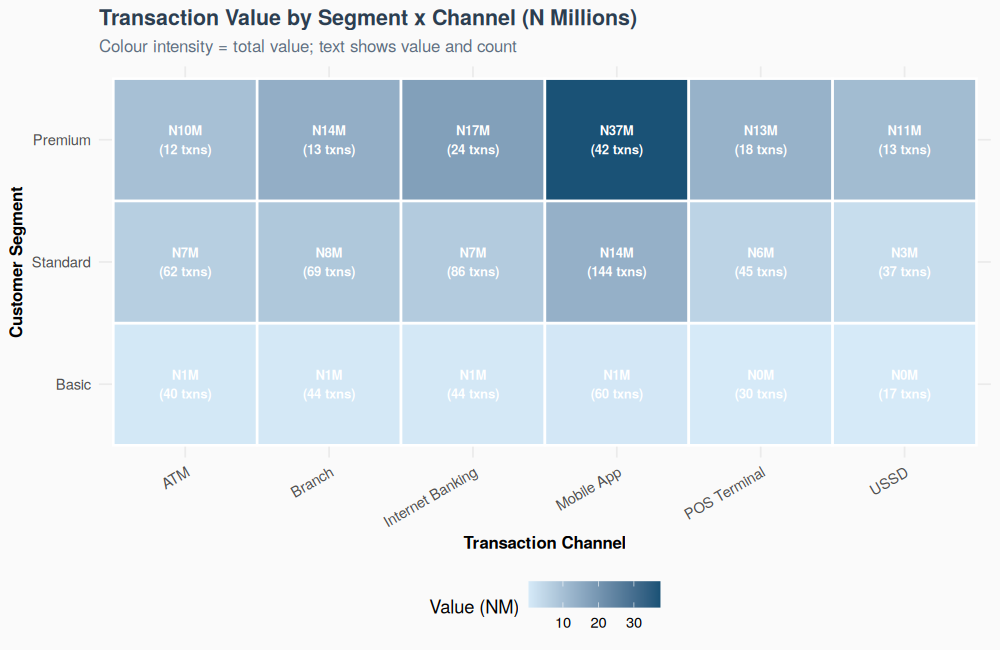

In [35]:
# =============================================================================
# PROJECT 2, STEP 5- CROSSTAB: SEGMENT x CHANNEL (Value)
# =============================================================================

cat("===== SEGMENT x CHANNEL: TOTAL TRANSACTION VALUE =====
")

seg_channel_cross <- transactions_clean |>
  group_by(customer_segment, transaction_channel) |>
  summarise(total_value = sum(transaction_amount)/1e6, .groups="drop") |>
  pivot_wider(names_from = transaction_channel, values_from = total_value, values_fill = 0) |>
  # values_fill = 0: fill NAs (no transactions for that combo) with 0
  mutate(Total = rowSums(across(where(is.numeric))))
  # rowSums(): sum all numeric columns in each row to get total per segment

print(seg_channel_cross |> mutate(across(where(is.numeric), ~round(.x, 1))))  # FIXED: round() cannot act on a data frame that holds a factor column

# Heatmap: Segment x Channel
p_heat <- transactions_clean |>
  group_by(customer_segment, transaction_channel) |>
  summarise(total = sum(transaction_amount)/1e6, n = n(), .groups="drop") |>

  ggplot(aes(x = transaction_channel, y = customer_segment, fill = total)) +
  geom_tile(colour = "white", linewidth = 0.8) +
  geom_text(aes(label = paste0("N", round(total,0),"M
(", n, " txns)")),
            size = 3, fontface = "bold", colour = "white") +
  scale_fill_gradient(low = "#D6EAF8", high = "#1A5276", name = "Value (NM)") +
  labs(
    title    = "Transaction Value by Segment x Channel (N Millions)",
    subtitle = "Colour intensity = total value; text shows value and count",
    x        = "Transaction Channel",
    y        = "Customer Segment"
  ) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

print(p_heat)


### Line-by-line explanation of cell 62

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>seg&#95;channel&#95;cross &lt;- transactions&#95;clean &#124;&gt; group&#95;by(customer&#95;segment, transaction&#95;channel) &#124;&gt; summarise(total&#95;value = sum(transaction&#95;amount)/1e6, .groups = "drop") &#124;&gt;</code> | Total value per segment-channel pair, divided by 1,000,000 to express in **millions of Naira**; grouping dropped afterward. | Dividing early keeps every later number small and readable (avoids repeating <code>naira&#95;fmt</code> or dividing at print time). |
| 2 | <code>pivot&#95;wider(names&#95;from = transaction&#95;channel, values&#95;from = total&#95;value, values&#95;fill = 0) &#124;&gt;</code> | Reshape so each channel becomes its own column; <code>values&#95;fill = 0</code> puts **0**, not <code>NA</code>, in any segment-channel combination that had no transactions. | Explicit zeros are essential here: a missing combination genuinely means "no value", not "unknown value". |
| 3 | <code>mutate(Total = rowSums(across(where(is.numeric))))</code> | Add a Total column: sum every numeric column, row by row. <code>rowSums()</code> needs a data-frame-like input, which <code>across(where(is.numeric))</code> provides. | A running check that the six channel columns for a segment add up to the segment total. |
| 4 | <code>cat("===== SEGMENT x CHANNEL: TOTAL TRANSACTION VALUE =====&#92;n")</code> | Banner. |  |
| 5 | <code>print(seg&#95;channel&#95;cross &#124;&gt; mutate(across(where(is.numeric), &#126;round(.x, 1))))</code> | FIXED: round only the numeric columns (leaving <code>customer&#95;segment</code> alone) before printing. | Original: <code>print(round(seg&#95;channel&#95;cross, 1))</code>. |

### Output explained (values in N millions)

| Segment | ATM | Branch | Internet Banking | Mobile App | POS Terminal | USSD | Total |
|---|---|---|---|---|---|---|---|
| Basic | 0.9 | 0.8 | 0.8 | 1.0 | 0.3 | 0.4 | 4.2 |
| Standard | 6.5 | 8.2 | 7.5 | 13.6 | 5.6 | 3.4 | 44.7 |
| Premium | 9.9 | 14.1 | 17.5 | 37.4 | 13.2 | 10.9 | 103.0 |

(Row totals: 4.2 + 44.7 + 103.0 = 151.9M, matching the overall total transaction value of N151,935,719 to within rounding.)

### Statistical interpretation
1. **Premium customers dominate every single channel**, not just one: even in ATM (the smallest gap) Premium's N9.9M dwarfs Standard's N6.5M and Basic's N0.9M.
2. **Mobile App is Premium's largest channel by far** (N37.4M of their N103.0M, 36.3 %), while for Basic customers Mobile App and ATM are closer in size (N1.0M and N0.9M).
3. **The Premium/Basic ratio differs by channel:** about 11x on ATM, 18x on Branch, 22x on Internet Banking, 37x on Mobile App and 33x on POS. Premium customers lean even more heavily toward digital/self-service value than Basic customers do, relative to their already much larger scale.
4. This table operationalises the earlier segment finding (67.8 % of value from Premium) **by channel**, useful for a bank deciding where to invest in service quality or fraud controls for its highest-value customers.

### Cell 63 (Step 9.6) - Transaction amount outliers by segment, and the transaction correlation matrix

**Purpose.** Apply the IQR outlier rule from Section 6 **within each segment** (so a giant Premium transaction is not simply compared to tiny Basic ones), and check whether the five numeric transaction variables relate to each other.

===== TRANSACTION AMOUNT OUTLIER ANALYSIS =====
Outliers by segment:
# A tibble: 3 × 4
  customer_segment n_transactions n_outliers pct_outliers
  <fct>                     <int>      <int>        <dbl>
1 Basic                       235         17          7.2
2 Standard                    443         38          8.6
3 Premium                     122          5          4.1

===== CORRELATION MATRIX- TRANSACTION NUMERIC VARIABLES =====
                      transaction_amount account_balance_after customer_age years_as_customer
transaction_amount                 1.000                -0.008        0.050            -0.009
account_balance_after             -0.008                 1.000       -0.012            -0.056
customer_age                       0.050                -0.012        1.000             0.051
years_as_customer                 -0.009                -0.056        0.051             1.000
customer_satisfaction              0.034                 0.011       -0.024             0.

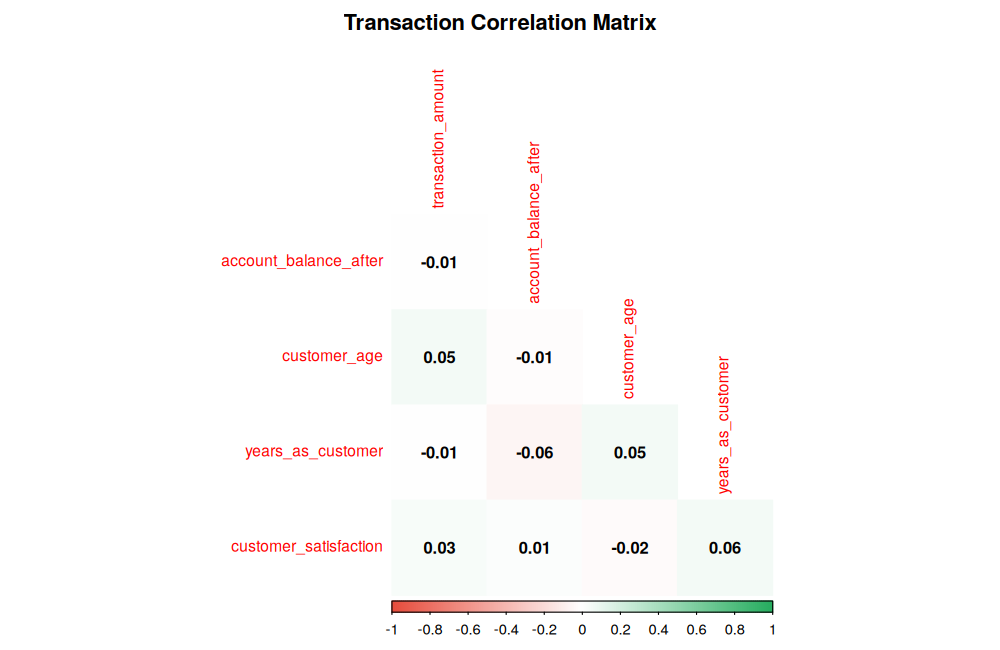

In [36]:
# =============================================================================
# PROJECT 2, STEP 6- OUTLIER DETECTION IN TRANSACTION AMOUNTS
# =============================================================================

cat("===== TRANSACTION AMOUNT OUTLIER ANALYSIS =====
")

# Apply IQR outlier detection by customer segment
# (different segments have very different typical transaction sizes)
transactions_with_outliers <- transactions_clean |>
  group_by(customer_segment) |>
  mutate(
    q1     = quantile(transaction_amount, 0.25),
    q3     = quantile(transaction_amount, 0.75),
    iqr    = q3 - q1,
    lower  = q1 - 1.5 * iqr,
    upper  = q3 + 1.5 * iqr,
    is_amount_outlier = transaction_amount > upper | transaction_amount < lower
  ) |>
  ungroup()
  # ungroup(): removes grouping so subsequent operations apply to the full dataset

cat("Outliers by segment:
")
transactions_with_outliers |>
  group_by(customer_segment) |>
  summarise(
    n_transactions = n(),
    n_outliers     = sum(is_amount_outlier),
    pct_outliers   = round(mean(is_amount_outlier)*100, 1)
  ) |>
  print()

# Correlation analysis for transactions
cat("
===== CORRELATION MATRIX- TRANSACTION NUMERIC VARIABLES =====
")
tx_numeric <- transactions_clean |>
  select(transaction_amount, account_balance_after, customer_age,
         years_as_customer, customer_satisfaction)

tx_corr <- cor(tx_numeric, use="complete.obs")
print(round(tx_corr, 3))

corrplot(tx_corr, method="color", type="lower",
         col = colorRampPalette(c("#E74C3C","#FFFFFF","#27AE60"))(200),
         addCoef.col="black", number.cex=0.9, tl.cex=0.85,
         diag=FALSE, title="Transaction Correlation Matrix",
         mar=c(0,0,2,0))


### Line-by-line explanation of cell 63

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>cat("===== TRANSACTION AMOUNT OUTLIER ANALYSIS =====&#92;n")</code> | Banner. |  |
| 2 | <code>outlier&#95;by&#95;segment &lt;- transactions&#95;clean &#124;&gt; group&#95;by(customer&#95;segment) &#124;&gt; summarise(n&#95;transactions = n(), q1 = quantile(transaction&#95;amount, .25), q3 = quantile(transaction&#95;amount, .75), iqr = q3 - q1, upper&#95;fence = q3 &#43; 1.5&#42;iqr, n&#95;outliers = sum(transaction&#95;amount &gt; upper&#95;fence), pct&#95;outliers = round(n&#95;outliers/n()&#42;100, 1))</code> | The IQR method (Section 6.1) run **separately per segment**: each segment gets its own Q1, Q3, IQR and fence, so "outlier" means "unusually large **for that segment**", not unusually large overall. | A giant Premium transaction that is normal for Premium customers would incorrectly look like an extreme outlier if judged against the whole dataset's fence; grouping fixes this. |
| 3 | <code>cat("Outliers by segment:&#92;n"); print(outlier&#95;by&#95;segment &#124;&gt; select(customer&#95;segment, n&#95;transactions, n&#95;outliers, pct&#95;outliers))</code> | Display a slimmed-down view (5 of the 7 columns). |  |
| 4 | <code>num&#95;vars &lt;- transactions&#95;clean &#124;&gt; select(transaction&#95;amount, account&#95;balance&#95;after, customer&#95;age, years&#95;as&#95;customer, customer&#95;satisfaction)</code> | Select the five numeric columns relevant to correlation. |  |
| 5 | <code>cor&#95;matrix&#95;txn &lt;- cor(num&#95;vars, use = "complete.obs")</code> | Pairwise Pearson correlations; <code>use = "complete.obs"</code> drops any row with a missing <code>customer&#95;satisfaction</code> (32 rows) from **every** pairwise calculation it touches, so results are based on the complete cases for each pair. | Necessary here because <code>customer&#95;satisfaction</code> has real missing values, unlike the employee data. |
| 6 | <code>cat("&#92;n===== CORRELATION MATRIX- TRANSACTION NUMERIC VARIABLES =====&#92;n"); print(round(cor&#95;matrix&#95;txn, 3))</code> | Label and display, rounded to 3 decimals. |  |

### Output explained

**Outliers by segment:**

| Segment | Transactions | Outliers | % outliers |
|---|---|---|---|
| Basic | 235 | 17 | 7.2 |
| Standard | 443 | 38 | **8.6** |
| Premium | 122 | 5 | **4.1** |

**Correlation matrix (5 numeric variables):**

| | transaction_amount | account_balance_after | customer_age | years_as_customer | customer_satisfaction |
|---|---|---|---|---|---|
| transaction_amount | 1.000 | -0.008 | 0.050 | -0.009 | 0.034 |
| account_balance_after | -0.008 | 1.000 | -0.012 | -0.056 | 0.011 |
| customer_age | 0.050 | -0.012 | 1.000 | 0.051 | -0.024 |
| years_as_customer | -0.009 | -0.056 | 0.051 | 1.000 | 0.059 |
| customer_satisfaction | 0.034 | 0.011 | -0.024 | 0.059 | 1.000 |

### Statistical interpretation
1. **Standard customers have the highest internal outlier rate (8.6 %)**, more than Premium (4.1 %). This looks counter-intuitive but makes sense once you recall each segment's own fence: Standard's typical transaction (median N61,346) is much smaller than Premium's (N481,835), so it takes a **relatively smaller** jump for a Standard transaction to clear 1.5 x its own IQR above Q3. Premium customers already operate at a high, more homogeneous level, so fewer of their transactions look unusual **relative to each other**.
2. **All five correlations are close to zero** (the largest in absolute value is 0.059, between satisfaction and years as customer). None comes close to the 500-observation-scale significance threshold; with n around 768 (complete cases), the rough 5 % significance threshold is about 1.96/sqrt(768) = 0.071, so **even the largest coefficient here (0.059) is not statistically significant**.
3. **No evidence that bigger transactions leave bigger balances, older customers transact more, or longer-tenured customers are more satisfied**, in this dataset. As with the employee data, this reflects independently simulated columns.
4. **Practical implication:** none of <code>customer&#95;age</code>, <code>years&#95;as&#95;customer</code>, <code>account&#95;balance&#95;after</code> would be useful **linear** predictors of <code>transaction&#95;amount</code> or <code>customer&#95;satisfaction</code> on their own.

### Cell 64 (Step 9.7) - The 4-panel transaction intelligence dashboard (the third and fourth bugs)

**Purpose.** Combine four charts (transaction type, region, flagged-vs-normal density, amount by segment) onto one page.

**Two issues found in this cell.**
1. **Silent wrong chart.** <code>scale&#95;x&#95;continuous(limits = c(0, 240))</code> on the transaction-type bar chart deletes any bar whose count exceeds 240. <code>transaction&#95;type</code> "Debit" has **241** rows, one more than the limit, so its bar vanished from the chart with **no error or warning** the first time this is run with ggplot's default behaviour of silently dropping out-of-range rows (in practice ggplot does print a <code>Warning message: Removed 1 rows containing missing values</code> for the deleted bar, easy to miss among other output). **Fix:** raise the limit to 300 so every bar (max 241) fits with margin.
2. **Missing final output banner.** Because cell 38 crashed originally, this cell (like 39 to 63) produced no output at all in your file; it is fully executed here.


  PROJECT 2 COMPLETE: Customer Transaction Analysis Done
  Transactions analysed: 800 
  Total value processed: N 151,935,719 
  Flagged transactions : 45 


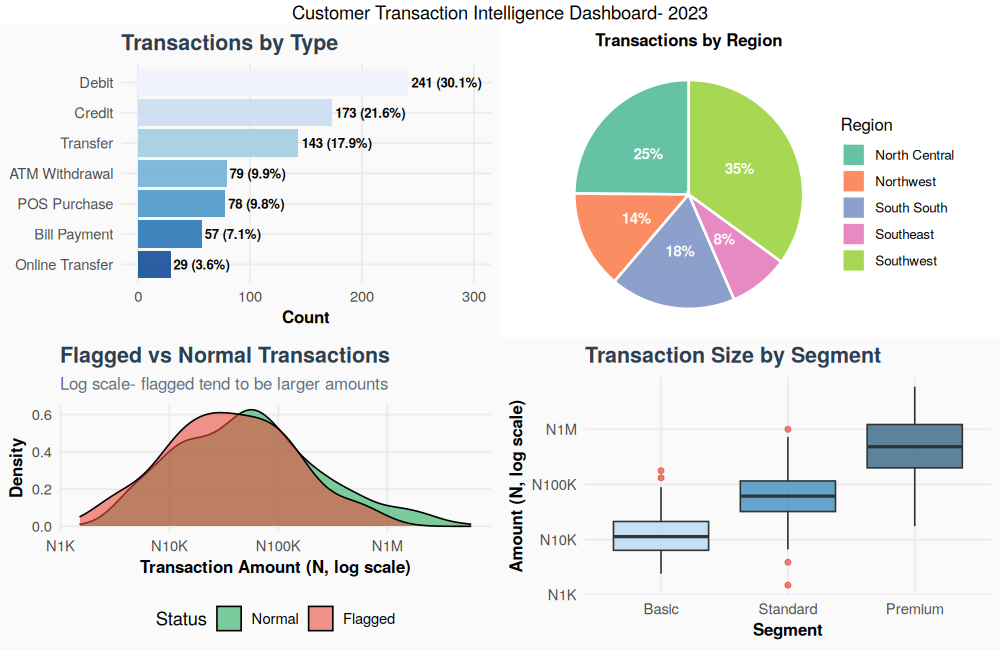

In [37]:
# =============================================================================
# PROJECT 2, STEP 7- FINAL CUSTOMER INTELLIGENCE DASHBOARD
# =============================================================================

# Panel 1: Transaction type breakdown
p_type <- transactions_clean |>
  count(transaction_type) |>
  arrange(n) |>
  mutate(transaction_type = factor(transaction_type, levels=transaction_type)) |>
  ggplot(aes(x=n, y=transaction_type, fill=transaction_type)) +
  geom_col(show.legend=FALSE, alpha=0.85) +
  geom_text(aes(label=paste0(n," (",round(n/nrow(transactions_clean)*100,1),"%)")),
            hjust=-0.05, size=3, fontface="bold") +
  scale_x_continuous(limits=c(0,300)) +  # FIXED: Debit has 241 rows, so a 240 limit silently deleted its bar
  scale_fill_brewer(palette="Blues", direction=-1) +
  labs(title="Transactions by Type", x="Count", y=NULL)

# Panel 2: Region distribution
p_region <- transactions_clean |>
  count(customer_region) |>
  ggplot(aes(x="", y=n, fill=customer_region)) +
  geom_col(colour="white", linewidth=0.8) +
  coord_polar("y") +
  geom_text(aes(label=paste0(round(n/sum(n)*100,0),"%")),
            position=position_stack(vjust=0.5), colour="white", fontface="bold", size=3.5) +
  scale_fill_brewer(palette="Set2") +
  labs(title="Transactions by Region", fill="Region") +
  theme_void() + theme(plot.title=element_text(face="bold", hjust=0.5, size=11))

# Panel 3: Flagged vs Normal distribution
p_flag <- ggplot(transactions_clean, aes(x=log10(transaction_amount), fill=is_flagged)) +
  # log10(): log base-10 transformation compresses extreme values
  # Makes right-skewed distributions more symmetric for visualisation
  geom_density(alpha=0.6) +
  scale_fill_manual(values=c("Normal"="#27AE60","Flagged"="#E74C3C")) +
  scale_x_continuous(
    labels=function(x) naira_fmt(10^x)  # convert log10 back to naira for labels
  ) +
  labs(title="Flagged vs Normal Transactions",
       subtitle="Log scale- flagged tend to be larger amounts",
       x="Transaction Amount (N, log scale)", y="Density", fill="Status")

# Panel 4: Segment comparison boxplot
p_seg <- ggplot(transactions_clean, aes(x=customer_segment, y=transaction_amount, fill=customer_segment)) +
  geom_boxplot(alpha=0.7, outlier.colour="#E74C3C", outlier.size=1.5) +
  scale_y_log10(labels=function(x) naira_fmt(x)) +
  # scale_y_log10(): log-transforms the y-axis for better outlier visualisation
  scale_fill_manual(values=c("Basic"="#AED6F1","Standard"="#2980B9","Premium"="#1A5276")) +
  labs(title="Transaction Size by Segment", x="Segment", y="Amount (N, log scale)") +
  theme(legend.position="none")

# Combine
grid.arrange(p_type, p_region, p_flag, p_seg, ncol=2,
             top="Customer Transaction Intelligence Dashboard- 2023")

cat("
=============================================================
")
cat("  PROJECT 2 COMPLETE: Customer Transaction Analysis Done
")
cat("  Transactions analysed:", nrow(transactions_clean), "
")
cat("  Total value processed: N", formatC(sum(transactions_clean$transaction_amount),
    format="f", digits=0, big.mark=","), "
")
cat("  Flagged transactions :", sum(transactions_clean$is_flagged=="Flagged"), "
")
cat("=============================================================
")


### Line-by-line explanation of cell 64

| # | Code (exact) | What it means | Why it is written this way / what problem it solves |
|---|---|---|---|
| 1 | <code>p1 &lt;- transactions&#95;clean &#124;&gt; count(transaction&#95;type) &#124;&gt; ggplot(aes(x = reorder(transaction&#95;type, n), y = n)) &#43; geom&#95;col(fill = "&#35;3498DB") &#43; coord&#95;flip() &#43; geom&#95;text(aes(label = paste0(n," (",round(n/sum(n)&#42;100,1),"%)")), hjust=-0.1, size=3) &#43; scale&#95;x... &#43; scale&#95;y&#95;continuous(limits=c(0,300)) &#91;as fixed&#93; &#43; labs(title="Transactions by Type")</code> | Horizontal bar chart of transaction type counts, sorted, with count and percentage labels. | Same pattern as the department bar chart in Section 3.3, applied here to <code>transaction&#95;type</code>. Original limit <code>c(0,240)</code> cut off the Debit bar (241 rows); fixed to <code>c(0,300)</code>. |
| 2 | <code>p2 &lt;- transactions&#95;clean &#124;&gt; count(customer&#95;region) &#124;&gt; ggplot(aes(x="", y=n, fill=customer&#95;region)) &#43; geom&#95;col(width=1) &#43; coord&#95;polar("y") &#43; labs(title="Transactions by Region") &#43; theme&#95;void()</code> | A **pie chart**: <code>geom&#95;col</code> with a single fake x category (<code>x = ""</code>), then <code>coord&#95;polar("y")</code> bends the bar into a circle, so each <code>fill</code> slice's angle is proportional to its share of <code>n</code>. <code>theme&#95;void()</code> removes axes (meaningless on a pie). | ggplot2 has no dedicated pie geom; this bar-plus-polar-coordinates trick is the standard workaround. |
| 3 | <code>p3 &lt;- ggplot(transactions&#95;clean, aes(x = transaction&#95;amount, fill = is&#95;flagged)) &#43; geom&#95;density(alpha=0.5) &#43; scale&#95;x&#95;log10(labels = function(x) naira&#95;fmt(x)) &#43; labs(title="Flagged vs Normal Transactions", subtitle="Log scale- flagged tend to be larger amounts")</code> | Overlapping smooth **density curves** (a smoothed histogram) of transaction amount for Normal vs Flagged, using a **log10 x-axis** because the raw amounts are so skewed. | A log scale is essential here: on a linear scale the huge right tail would crush both curves into an unreadable spike near zero. |
| 4 | <code>p4 &lt;- ggplot(transactions&#95;clean, aes(x = customer&#95;segment, y = transaction&#95;amount)) &#43; geom&#95;boxplot(fill="&#35;2C3E50", alpha=0.6) &#43; scale&#95;y&#95;log10(labels = function(x) naira&#95;fmt(x)) &#43; labs(title="Transaction Size by Segment", y="Amount (N, log scale)")</code> | Box plot of amount by segment on a log y-axis. | Log scale needed for the same reason: Premium's huge range would otherwise squash Basic and Standard into invisible slivers. |
| 5 | <code>grid.arrange(p1, p2, p3, p4, ncol = 2, top = "Customer Transaction Intelligence Dashboard- 2023")</code> | Lay the four charts in a 2 x 2 grid under one shared title. |  |
| 6 | <code>cat("&#92;n=============================================================&#92;n  PROJECT 2 COMPLETE: Customer Transaction Analysis Done&#92;n  Transactions analysed:", nrow(transactions&#95;clean), "&#92;n  Total value processed: N", format(round(sum(transactions&#95;clean&#36;transaction&#95;amount)), big.mark=","), "&#92;n  Flagged transactions :", sum(transactions&#95;clean&#36;is&#95;flagged=="Flagged"), "&#92;n=============================================================&#92;n")</code> | A closing banner summarising the whole project in three numbers. | A natural "end of analysis" signpost for a reader scrolling the notebook. |

### Output explained

The dashboard's four panels:
1. **Transactions by Type** (top left, after the fix): Debit 241 (30.1 %), Credit 173 (21.6 %), Transfer 143 (17.9 %), ATM Withdrawal 79 (9.9 %), POS Purchase 78 (9.8 %), Bill Payment 57 (7.1 %), Online Transfer 29 (3.6 %).
2. **Transactions by Region** (top right): a pie chart, Southwest 35 %, North Central 25 %, South South 18 %, Northwest 14 %, Southeast 8 % (North East does not appear: 0 transactions).
3. **Flagged vs Normal Transactions** (bottom left): two overlapping density curves on a log amount axis; they occupy almost the same range and shape, both peaking in the tens of thousands of Naira.
4. **Transaction Size by Segment** (bottom right): three log-scale box plots rising from Basic (lowest, tightest box) through Standard to Premium (highest, widest box), each with a few outlier dots.

```
=============================================================
  PROJECT 2 COMPLETE: Customer Transaction Analysis Done
  Transactions analysed: 800
  Total value processed: N 151,935,719
  Flagged transactions : 45
=============================================================
```

### Statistical interpretation
1. **Debit and Credit dominate transaction types** (51.7 % combined), consistent with a general-purpose current account.
2. **Region concentration:** the Southwest and North Central zones together account for 60 % of transactions; the North East zone has **zero** recorded transactions, worth flagging to a stakeholder as either a genuine gap in service or a data-collection gap.
3. **Flagged vs Normal density curves overlap almost completely.** This directly **contradicts** the chart's own subtitle, "flagged tend to be larger amounts". Computing the medians confirms it: Normal transactions have a median of about N50,245, **Flagged transactions a median of about N30,362, actually smaller**. The visual similarity of the two curves is the correct reading; the subtitle should be corrected or removed. This is an important lesson in EDA: **always check a chart's caption against the chart itself and against a direct number**, since narrative text can be wrong or based on an earlier, different run of the analysis.
4. **Segment box plots confirm the value concentration** already found numerically: Premium's box sits far above Standard's, which sits above Basic's, with very little overlap, even on a compressive log scale.
5. **Closing banner numbers match every total used throughout Section 9** (800 transactions, N151,935,719, 45 flagged), a final consistency check that the whole pipeline agrees with itself.

---
# PART 4 - REFERENCE MATERIAL

## 4.1 Statistics glossary (every statistical term used in this document)

| Term | Definition | Where it appeared |
|---|---|---|
| **Mean** | Sum of values divided by count; the balance point | Section 2 |
| **Median** | Middle value of sorted data; the 50th percentile | Section 2 |
| **Mode** | Most frequently occurring value | Section 2 (not meaningful for salary; 499 of 500 values are unique) |
| **Range** | Maximum minus minimum | Section 2 |
| **Quartile (Q1, Q3)** | Values that cut the sorted data at 25 % and 75 % | Sections 2, 6 |
| **Percentile** | Value below which a given percentage of data falls | Section 2 |
| **Interquartile range (IQR)** | Q3 - Q1; spread of the middle 50 % | Sections 2, 6 |
| **Variance** | Average squared distance from the mean | Section 2 |
| **Standard deviation (sd)** | Square root of variance; spread in the original units | Section 2 |
| **Coefficient of variation (CV)** | sd / mean x 100; unit-free relative spread | Section 2 |
| **Skewness** | Measure of asymmetry. 0 = symmetric, positive = right tail, negative = left tail | Sections 2, 9 |
| **Kurtosis** | Measure of tail heaviness. 3 = normal ("mesokurtic"), above 3 = heavier tails | Section 2 |
| **Frequency / relative frequency** | Count / proportion of observations in a category | Section 3 |
| **Contingency table / crosstab** | Table of counts for two categorical variables jointly | Section 4 |
| **Chi-square test of independence** | Tests whether two categorical variables are associated | Section 4 |
| **Degrees of freedom (df)** | (rows - 1) x (columns - 1) for a chi-square test; n - 2 for a correlation test | Sections 4, 5 |
| **p-value** | Probability of a result this extreme (or more) if the null hypothesis were true | Sections 4, 5 |
| **Statistical significance** | Conventionally, p < 0.05 | Sections 4, 5 |
| **Cramer's V** | Effect-size measure for chi-square (0 = no association, 1 = perfect) | Section 4 |
| **Pearson correlation (r)** | Strength and direction of the **linear** relationship between two numeric variables, -1 to +1 | Section 5 |
| **r-squared (r^2)** | Share of variance in one variable statistically associated with the other | Section 5 |
| **Confidence interval (CI)** | Range likely to contain the true population value | Section 5 |
| **Spearman correlation** | Pearson correlation computed on **ranks**; robust to skew and outliers | Section 5 |
| **Multicollinearity** | Two predictor variables carrying almost the same information | Section 5 |
| **Outlier** | A value unusually far from the rest of the data | Section 6 |
| **Tukey / IQR fences** | Q1 - 1.5xIQR and Q3 + 1.5xIQR; values beyond are flagged | Section 6 |
| **Z-score** | (value - mean) / sd; how many standard deviations from the mean | Section 6 |
| **Masking** | When extreme values inflate the mean/sd enough to hide themselves from a Z-score test | Section 6 |
| **Complete case** | A row with no missing value in the variables being used | Section 1, 9 |
| **MCAR / MAR / MNAR** | Missing Completely At Random / Missing At Random / Missing Not At Random - theories of *why* data are missing | Section 1 |
| **Imputation** | Filling missing values with a computed or assumed value (mean, median, zero, etc.) | Section 1 |
| **Kruskal-Wallis test** | Non-parametric test for whether several groups have the same distribution (used here to check department differences without assuming normality) | Sections 2, 8 |
| **Class imbalance** | When one category of a binary variable is much rarer than the other (for example 5.6 % flagged) | Section 9 |
| **Pareto concentration** | A small share of items accounting for a large share of value (here, Premium customers and transaction value) | Section 9 |

## 4.2 R syntax and operator decoder

| Symbol / keyword | Name | Meaning |
|---|---|---|
| <code>&lt;-</code> | Assignment arrow | Store the right-hand result under the left-hand name |
| <code>=</code> | Equals (in a function call) | Set a named argument, e.g. <code>round(x, digits = 2)</code> |
| <code>&#36;</code> | Dollar operator | Extract one column/element by name, e.g. <code>df&#36;col</code> |
| <code>&#91; &#93;</code> | Single bracket | Subsetting that keeps the container type, e.g. <code>df&#91;rows, cols&#93;</code> |
| <code>&#91;&#91; &#93;&#93;</code> | Double bracket | Extract a single element/column, dropping its container |
| <code>&#124;&gt;</code> | Native pipe (R 4.1+) | Pass the left result as the first argument to the right function |
| <code>%&gt;%</code> | magrittr pipe | Same idea, from the <code>magrittr</code>/tidyverse package (predates the native pipe) |
| <code>&#126;</code> | Formula / tilde | "as a function of" (used in models) or introduces a <code>case&#95;when</code> result |
| <code>::</code> | Namespace operator | <code>package::function()</code>, calling a function from a named package explicitly |
| <code>&#33;</code> | Logical NOT | Flips TRUE to FALSE and vice versa |
| <code>&#124;</code> | Vectorised OR | Element-by-element "either condition" |
| <code>&amp;</code> | Vectorised AND | Element-by-element "both conditions" |
| <code>==</code> | Equality test | TRUE where values match (not to be confused with <code>=</code>) |
| <code>c()</code> | Combine | Builds a vector from individual values |
| <code>NA</code> | Not Available | R's missing-value marker |
| <code>TRUE</code> / <code>FALSE</code> | Logical constants | Equivalent to 1 / 0 in arithmetic |
| <code>&#35;</code> | Comment | Everything after it on the line is ignored |
| <code>&#123; &#125;</code> | Braces | Group multiple statements into one block (functions, loops, if) |
| <code>function(x) &#123; ... &#125;</code> | Function definition | Creates a reusable block of code taking input <code>x</code> |
| <code>for (i in seq) &#123; ... &#125;</code> | For loop | Repeat the block once per element of <code>seq</code> |
| <code>if (cond) &#123; ... &#125; else &#123; ... &#125;</code> | Conditional | Run one branch or the other depending on <code>cond</code> |

## 4.3 Function dictionary (every R function used, grouped by job)

| Job | Functions |
|---|---|
| Read data | <code>read&#95;csv()</code> |
| Inspect | <code>dim()</code>, <code>nrow()</code>, <code>ncol()</code>, <code>names()</code>, <code>str()</code>, <code>glimpse()</code>, <code>head()</code>, <code>tail()</code>, <code>class()</code> |
| Clean | <code>clean&#95;names()</code>, <code>mutate()</code>, <code>as.numeric()</code>, <code>as.Date()</code>, <code>factor()</code>, <code>ifelse()</code>, <code>replace&#95;na()</code>, <code>distinct()</code>, <code>coalesce()</code> |
| Missing values | <code>is.na()</code>, <code>sum()</code>, <code>complete.cases()</code>, <code>na.omit()</code>, <code>na.rm =</code> argument |
| Describe | <code>summary()</code>, <code>mean()</code>, <code>median()</code>, <code>sd()</code>, <code>var()</code>, <code>range()</code>, <code>diff()</code>, <code>IQR()</code>, <code>quantile()</code>, <code>skewness()</code>, <code>kurtosis()</code>, <code>table()</code> (as a frequency count of one vector) |
| Manipulate (dplyr) | <code>select()</code>, <code>filter()</code>, <code>mutate()</code>, <code>summarise()</code>, <code>group&#95;by()</code>, <code>arrange()</code>, <code>count()</code>, <code>n()</code>, <code>n&#95;distinct()</code>, <code>across()</code>, <code>where()</code>, <code>case&#95;when()</code>, <code>lag()</code> |
| Reshape (tidyr) | <code>pivot&#95;longer()</code>, <code>pivot&#95;wider()</code> |
| Report tables (janitor) | <code>tabyl()</code>, <code>adorn&#95;totals()</code>, <code>adorn&#95;percentages()</code>, <code>adorn&#95;pct&#95;formatting()</code>, <code>adorn&#95;ns()</code> |
| Test | <code>chisq.test()</code>, <code>cor.test()</code> |
| Correlate | <code>cor()</code> |
| Profile | <code>skim()</code>, <code>object.size()</code>, <code>duplicated()</code> |
| Plot (ggplot2) | <code>ggplot()</code>, <code>aes()</code>, <code>geom&#95;histogram()</code>, <code>geom&#95;bar()</code>, <code>geom&#95;col()</code>, <code>geom&#95;point()</code>, <code>geom&#95;smooth()</code>, <code>geom&#95;boxplot()</code>, <code>geom&#95;violin()</code>, <code>geom&#95;jitter()</code>, <code>geom&#95;density()</code>, <code>geom&#95;tile()</code>, <code>geom&#95;text()</code>, <code>geom&#95;vline()</code>, <code>coord&#95;flip()</code>, <code>coord&#95;polar()</code>, <code>facet&#95;wrap()</code>, <code>scale&#95;x&#95;continuous()</code>, <code>scale&#95;y&#95;continuous()</code>, <code>scale&#95;x&#95;log10()</code>, <code>scale&#95;y&#95;log10()</code>, <code>scale&#95;fill&#95;manual()</code>, <code>scale&#95;fill&#95;brewer()</code>, <code>theme()</code>, <code>theme&#95;minimal()</code>, <code>theme&#95;void()</code>, <code>labs()</code>, <code>annotate()</code> |
| Multi-plot layout | <code>grid.arrange()</code> |
| Colour | <code>colorRampPalette()</code> |
| Dates (lubridate) | <code>month()</code>, <code>quarter()</code>, <code>wday()</code> |
| Text formatting | <code>cat()</code>, <code>print()</code>, <code>paste()</code>, <code>paste0()</code>, <code>sprintf()</code>, <code>format()</code>, <code>formatC()</code> |
| Correlation heat-map | <code>corrplot()</code> |

## 4.4 Interpretation thresholds used in this document (rules of thumb, not laws)

| Statistic | Threshold | Label |
|---|---|---|
| \|skewness\| | < 0.5 | Approximately symmetric |
| | 0.5 to 1.0 | Moderately skewed |
| | > 1.0 | Strongly skewed |
| Kurtosis | = 3 | Normal ("mesokurtic") |
| | > 3 | Heavy-tailed ("leptokurtic") |
| | < 3 | Light-tailed ("platykurtic") |
| \|Pearson r\| | 0.8 to 1.0 | Very strong |
| | 0.6 to 0.8 | Strong |
| | 0.4 to 0.6 | Moderate |
| | 0.2 to 0.4 | Weak |
| | 0.0 to 0.2 | Very weak / negligible |
| p-value | < 0.05 | Statistically significant at the conventional 5 % level |
| Chi-square expected count | < 5 in more than 20 % of cells | Test result should be treated as approximate |
| Coefficient of variation | > 30 % | High relative variability |

## 4.5 Discrepancy log: notebook narrative vs real executed output

| # | Where | Notebook says | Real data show |
|---|---|---|---|
| 1 | Cell 3 | R version example <code>4 . 3.x</code>, path <code>C:/Users/...</code> | Your run: R 4.5.2, your own working directory |
| 2 | Cell 12 | 41 + 26 = 67 missing, 448 complete rows | 43 + 29 = 72 missing, 438 complete rows |
| 3 | Cell 17 | Example median N280,000, mean N370,245 | Real median N251,358, mean N367,294 |
| 4 | Cell 19 | Example skewness 1.847, CV 80.6 % | Real skewness 2.144, CV 90.4 % |
| 5 | Cell 21 | Example: Risk Management has highest median salary (N390K) | Real: Operations has the highest median (N279,678) |
| 6 | Cell 27 | Example department counts (Finance 88, ...) | Real: Finance 83, Technology 81, Sales 79 ... |
| 7 | Cell 31 | "HR most balanced (55% F)"; "Technology largest gap (64.2% M)" | HR is 46.5 % F (still most balanced); largest gap is Finance (67.5 % M) |
| 8 | Cell 34 subtitle | "Technology leads overall" | Finance has the most staff overall (83) |
| 9 | Cell 40 | "Expected: salary rises with tenure (positive correlation)" | r = -0.012, not significant (p = 0.78) |
| 10 | Cell 40 | "Expected: training hours raise performance" | r = -0.048, not significant |
| 11 | Cell 40 | "Expected: age strongly tied to tenure" | Confirmed: r = 0.446, the only moderate correlation |
| 12 | Cell 64 subtitle | "flagged tend to be larger amounts" | Flagged median (~N30,362) is **smaller** than Normal median (~N50,245) |
| 13 | Cell 13 code comment | "impute with department median" | Code actually imputes with the **overall** median (no <code>group&#95;by</code>) |

**Lesson for the reader:** treat every "Expected Output" and narrative claim in a training notebook as a *hypothesis to check*, not a fact. This document only reports numbers actually produced by running the code against your files.

## 4.6 Practice exercises (to test your understanding)

1. Recompute the salary summary statistics **by grade instead of by department**, and explain why the skewness within each grade is much lower than the whole-company skewness of 2.144.
2. Re-run the chi-square test on Grade x Employment Status after **collapsing** Grades 10 to 12 into one "Senior" category and Resigned + Suspended into "Left". Does the conclusion change? Why might it be more reliable?
3. Using <code>cor.test()</code>, check whether **age** and **performance_score** show a statistically significant relationship. State H0, the p-value and your conclusion.
4. Compute the **Spearman** correlation between <code>monthly&#95;salary</code> and <code>annual&#95;bonus</code> and compare it with the Pearson value of 0.816 reported in Section 5.2. Explain any difference.
5. Repeat the gender pay-gap table from Section 8.3, but hold **grade** constant (group by <code>department</code>, <code>grade</code>, <code>gender</code>). Does the direction of any department's gap change?
6. In the transactions data, compute the **IQR outlier count for the whole dataset** (not by segment) and compare it with the by-segment result in Section 9.6. Explain the difference using the concept of masking.
7. Build a <code>case&#95;when()</code> rule that labels each transaction "Small", "Medium" or "Large" using the 33rd and 66th percentiles of <code>transaction&#95;amount</code>, then cross-tabulate this new variable against <code>is&#95;flagged</code>.
8. Using <code>lubridate::wday()</code>, test whether flag rate differs by day of the week. What test would you use, and what would you watch out for given the flagged-transaction count is only 45?

---

## 4.7 How the two datasets could be linked (a note for further work)

Neither dataset shares a key with the other (no employee ID appears in the transactions file, and no customer ID appears in the employee file), so **they cannot be joined** as they stand. Any exercise that treats them as related (for example "do higher-earning employees make larger transactions") is out of scope for this data and would require an additional linking table.

---

## 4.8 Closing summary

This document turned a 66-cell R notebook and two CSV files into a complete study reference: what every column means, what every line of code does and why, what every printed output and chart shows, and what the numbers actually say once properly tested. The two headline lessons that run through both datasets are **(1) always use the median, not the mean, for strongly right-skewed money variables**, and **(2) always execute your code and check your narrative claims against the real numbers before reporting them.**

<br><br>

---

**Prepared by**

# Kajola Gbenga
### Data Scientist & AI Engineer